# 02. 데이터 수집과 구성 보기 — 전체 11단계 중 2단계

## 오늘 하실 일

위에서부터 코드 셀을 차례로 실행하면서, 셀 바로 아래 「✍️ 내 생각」 칸에 그 결과가 무슨 뜻인지 적습니다.

- 코드 셀은 위에서부터 차례로 돌려야 합니다. 맨 앞 준비 셀이 아래 셀들이 쓸 경로와 함수를 만듭니다. 맨 뒤 2026년 셀만은 혼자 돌아갑니다.
- 적으신 것을 읽고 제가 그 칸 아래에 「클로드 검토」를 붙이겠습니다.
- 맨 끝 「✍️ 2단계를 닫으며」의 1번과 2번을 채우면 2단계가 닫힙니다.

---

어디서 무엇을 받아 무엇을 쓸지, 받은 것이 몇 줄 몇 칸이고 각 칸이 무슨 값인지 보는 단계입니다.

데이터를 받는 코드는 같은 폴더의 `02_수집_api.ipynb`(전력거래소 발전원별 발전량 API — 2024·2026년 시간별)와 `02_수집_asos.ipynb`(기상청 시간자료)에 있습니다. 2024년은 09-15에 다 받았고, 2026년은 09-18까지 96일(1월 1일 ~ 4월 6일)을 받아 107일이 남았습니다.

09-12에 이 노트북에 적혀 있던 글은 `docs/2단계_09-12_기록.md`로 옮겼습니다. 2026-09-18에 셀마다 적는 형식으로 바꾸면서 처음부터 다시 적기로 했기 때문입니다. 2024년 2월 29일을 뺀다는 결정은 그때 하셨고 3단계에서 그대로 씁니다.

| 단계 | 이름 |
|---|---|
| 1 | 과제 정의 |
| 2 | 데이터 수집과 구성 보기 ◀ 이 노트북 |
| 3 | 정제 |
| 4 | 탐색적 분석 |
| 5 | 변환·파생변수 |
| 6 | 분석계획 |
| 7 | 모델링과 검정 |
| 8 | 모델 확정과 핵심인자 |
| 9 | 이 과제만의 물음 — 2026년은 평소와 얼마나 달랐나 |
| 10 | 그 답을 숫자로 내기 |
| 11 | 결론 |

진행 기록(지금 어디)은 리포의 `README.md`가 원본입니다. 단계마다 무엇을 하고 내가 무엇을 정하는지는 옵시디언 볼트 「빅데이터 분석의 순서」에 있습니다.


## 물음 — 이 데이터가 어떻게 생겼나

시간별 파일(2023·2025)과 EPSIS 월별 표에서 행·열·결측·중복 시간을 보고, **시간별 LNG의 월 합계가 EPSIS 값과 맞는지** 확인한다. 맞으면 두 자료가 같은 것을 세고 있다는 뜻이고(단위 MWh↔GWh, 범위 = 전력시장 거래분), 안 맞으면 어디가 다른지부터 알아야 한다.

아직 아무것도 정하지 않는다. 아래 1-2를 실행하고, 보이는 것을 1-3에 적는다.

<div style="border: 2px solid var(--vscode-focusBorder, #3794ff); border-left-width: 6px; border-radius: 8px; padding: 4px 18px 10px; background: var(--vscode-textBlockQuote-background, rgba(127, 127, 127, 0.1));">

## 📌 물음 결론 — 이 데이터가 어떻게 생겼나

**왜 생긴 물음인가** — 1단계를 닫으며 「지금 과제 정의에 적합한 데이터가 실제로 있는지 확인한다」고 적었다. 받은 자료가 몇 줄 몇 칸이고, 시간별 LNG 월 합계가 EPSIS 월별 표와 맞는지 본 물음이다.

### 결정 — 2023·2025년은 그대로 쓰고, 2024년 2월 29일은 빼고, 2026년에 깨져서 온 날은 하루씩 따로 본다

**결정 근거** — 「EPSIS 대조」 셀에서 2023·2025년은 월 합계 차이가 0.0~0.1%였고, 2024년은 2월 −4.0%(하루가 빠짐)·8월 −98.1%였다. 「ASOS·API 파일 상태」 셀에서 2024년은 2월 29일 파일이 0행이고 8월 31일치가 전부 192행이 아니었으며, 2026년은 0행 1일·48행 14일·120행 1일이었다. 판단은 「EPSIS 대조」 아래와 「ASOS·API 파일 상태」 아래의 「✍️ 내 생각」에 적었다.

**남은 것** — 2024년 8월과 2026년 5월을 뺄지는 3단계 물음 1에서 정했다(뺐다). 2026년 7월 11일부터는 아직 안 올라와서 README 「되돌아올 수 있는 곳」에 적었다.

</div>

<div style="border: 2px dashed var(--vscode-focusBorder, #3794ff); border-left: 6px solid var(--vscode-focusBorder, #3794ff); border-radius: 8px; padding: 4px 18px 10px;">

## 🗂️ 물음 셀 흐름 — 셀마다 어디서 나왔나

| 셀 | 어디서 나왔나 — 단계 · 물음 · 칸 | 거기에 적힌 생각이나 본 것 | 그래서 무엇이 정해지지 않았나 |
|---|---|---|---|
| 연간 파일 세 해 | 2단계 물음 칸 · 판단 재료 칸 (1) — 물음을 열 때 클로드가 계획 | 받은 그대로의 데이터를 먼저 본다 — 행·열·결측·중복 시간 | 받은 파일이 몇 줄 몇 칸이고 어떤 연료가 들어 있는지 |
| 연료별 행 수 | 판단 재료 칸 (1) | 한 해가 8,760행(365일 × 24시간)이면 빠진 시각이 없다 | 연료마다 해마다 빠진 시각 없이 다 있는지 |
| LNG 중복·빠진 시각·기초통계 | 판단 재료 칸 (1) | 맞힐 값은 LNG 하나다 | LNG에 겹치거나 빠진 시각이 있는지 |
| EPSIS 대조 | 2단계 물음 칸 · 판단 재료 칸 (2) | 시간별 LNG의 월 합계가 EPSIS 값과 맞으면 두 자료가 같은 것을 센다 | 시간별 파일과 EPSIS 월별 표가 같은 것을 세는지 |
| 월별 그림 | 판단 재료 칸 (3) | 월별로 LNG·원전·석탄을 한 그림에 놓는다 | 해마다·달마다 세 연료가 어떻게 움직였는지 |
| ASOS·API 파일 상태 | 판단 재료 칸 (4) | 기온 파일과 2024년 API 파일을 연다 | 두 파일이 비어 있지 않은지 |
| 2026년은 어디까지 받았나 | 판단 재료 셀들 → 클로드가 더함 | 위 셀들은 2023·2024·2025년만 봤다. 2026년은 예측과 비교할 해라 따로 본다 | 2026년을 어디까지 받았고, 다 받은 달의 합계가 EPSIS와 맞는지 |

</div>

## 판단 재료 — 받은 그대로의 데이터를 본다

네 덩어리이고 셀도 넷으로 나눠 두었다 — 위에서부터 차례로 실행한다: (1) KPX 시간별 파일의 모양·연료별 행 수·빠진 시각 (2) LNG 월 합계 vs EPSIS (3) 월별 그림 (4) 기온 파일과 2024 API 파일이 비어 있지 않은지.

In [164]:
# 전체 11단계 중 → 2단계 데이터 수집과 구성 보기 · 준비 — 아래 셀들이 쓸 경로와 함수를 만든다. 결과는 찍지 않는다
import os, glob                             # 폴더·파일 경로를 다루는 모듈과, 파일 이름을 한꺼번에 찾는 모듈
import pandas as pd                         # 표(데이터프레임)를 다루는 라이브러리
import matplotlib.pyplot as plt             # 그림 그리는 라이브러리
plt.rcParams["font.family"] = "AppleGothic" # 맥에서 그림 속 한글이 깨지지 않게
plt.rcParams["axes.unicode_minus"] = False  # 마이너스 부호가 깨지지 않게
pd.set_option("display.width", 160)         # 표가 줄바꿈 없이 넓게 보이게

ROOT = os.getcwd()                          # 지금 폴더(보통 notebooks/)에서 시작해
while not os.path.isdir(os.path.join(ROOT, "data")) and ROOT != os.path.dirname(ROOT):
    ROOT = os.path.dirname(ROOT)            # data 폴더가 보일 때까지 위로 올라간다 = 프로젝트 루트
RAW = os.path.join(ROOT, "data", "raw")     # 원자료 폴더

def load_kpx(year):                         # 연간 파일 한 해를 읽어 열 이름을 통일해 돌려주는 함수
    folder = os.path.join(RAW, "kpx")
    name = [f for f in os.listdir(folder) if f"{year}1231" in f][0]      # 파일명에 20231231 같은 기준일이 들어 있다
    df = pd.read_csv(os.path.join(folder, name), encoding="utf-8-sig")   # 맨 앞 BOM이 있는 utf-8
    df.columns = ["date", "hour", "fuel", "cap_mw", "mwh"]              # 해마다 열 이름이 달라서(공백·'원료원') 자리로 통일
    df["fuel"] = df["fuel"].str.strip()      # 연료 이름 앞뒤 공백 제거
    df["year"] = year                        # 어느 해 파일인지 표시
    return df

def load_api(year):                          # API로 받은 한 해를 읽어 같은 열 이름으로 돌려주는 함수
    파일 = [f for f in sorted(glob.glob(os.path.join(RAW, "api", f"{year}*.csv")))
            if os.path.getsize(f) >= 100]    # 100바이트 미만 = 0행으로 온 날이라 건너뛴다
    df = pd.concat([pd.read_csv(f) for f in 파일], ignore_index=True)     # 하루치 파일들을 위아래로 붙인다
    df = df.rename(columns={"fuelTpCd": "fuel", "amgo": "mwh"})          # 연간 파일과 같은 이름으로 바꾼다
    df["date"] = pd.to_datetime(df["tradeYmd"].astype(str))              # 20240101 을 날짜로
    df["hour"] = df["tradeNo"].astype(int)                               # 1~24 시간 표기 (연간 파일과 같다)
    df["year"] = year
    return df[["date", "hour", "fuel", "mwh", "year"]]

print("준비 끝 — 프로젝트 폴더:", ROOT)


준비 끝 — 프로젝트 폴더: /Users/kimchangju/vs코드 /개인 프로젝트/lng-project


In [165]:
# 전체 11단계 중 → 2단계 데이터 수집과 구성 보기 · 연간 파일 세 해(2023·2024·2025)를 읽어 몇 줄 몇 칸인지, 어떤 연료가 들어 있는지 본다
for 해 in (2023, 2024, 2025):                                             # 세 해를 하나씩
    folder = os.path.join(RAW, "kpx")
    name = [f for f in os.listdir(folder) if f"{해}1231" in f][0]
    원본 = pd.read_csv(os.path.join(folder, name), encoding="utf-8-sig")   # 파일을 끝까지 읽는다
    연료 = sorted(원본[원본.columns[2]].astype(str).str.strip().unique())    # 세 번째 열이 연료 이름이다
    print(f"[{해}] {원본.shape[0]:,}행 {원본.shape[1]}칸 · 열 이름 {list(원본.columns)}")
    print(f"       연료 {len(연료)}종: {', '.join(연료)}")

kpx = pd.concat([load_kpx(2023), load_kpx(2024), load_kpx(2025)], ignore_index=True)   # 세 해를 위아래로 붙인다
print("\n세 해 합친 모양 (행, 열):", kpx.shape)
print(kpx.dtypes)                            # 자료형 — 숫자여야 할 열이 문자(object)면 여기서 보인다
print(kpx.head(3))


[2023] 179,208행 5칸 · 열 이름 ['거래일자', '시간', '연료원', ' 설비용량(MW) ', ' 전력거래량(MWh) ']
       연료 21종: IGCC, LNG, 경유, 기타, 매립가스, 무연탄, 바이오SRF, 바이오가스, 바이오매스, 바이오중유, 부생가스, 수력, 양수, 연료전지, 원자력, 유연탄, 중유, 태양광, 폐기물, 풍력, 해양에너지
[2024] 110,544행 5칸 · 열 이름 ['거래일자', '시간', '원료원', '설비용량(MW)', '전력거래량(MWh)']
       연료 13종: IGCC, 급전가능 재생에너지, 매립가스, 바이오SRF, 바이오가스, 바이오매스, 바이오중유, 소수력, 수력, 연료전지, 태양광, 풍력, 해양에너지
[2025] 224,928행 5칸 · 열 이름 ['거래일자', '거래시간', '연료원별', '설비용량(MW)', '전력거래량(MWh)']
       연료 26종: IGCC, LNG, LPG, 가스압, 경유, 급전가능 재생에너지, 기타, 매립가스, 무연탄, 바이오SRF, 바이오가스, 바이오매스, 바이오중유, 부생가스, 소수력, 수력, 양수, 연료전지, 원자력, 유연탄, 전기저장장치(비중앙), 중유, 태양광, 폐기물, 풍력, 해양에너지

세 해 합친 모양 (행, 열): (514680, 6)
date       object
hour        int64
fuel       object
cap_mw    float64
mwh       float64
year        int64
dtype: object
         date  hour fuel   cap_mw      mwh  year
0  2023-01-01     1  원자력  24650.0  19561.0  2023
1  2023-01-01     2  원자력  24650.0  19561.0  2023
2  2023-01-01     3  원자력  24650.0  19562.0  2023


## ✍️ 내 생각

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답:
- 23,24,25년도 행에 적힌 내용이 다르다. 우리가 원하는 데이터만 뽑아야 할 것 같다. 다행인건 5칸인 일자, 시간, 연료원, 설비용량, 전력거래량은 다 적혀있다는 것.
- 결과가 준비끝이라고 나왔는데.. 데이터를 보관할 장소를 고르는건가?  그 아래 셀을 보면, 2023,2024년 자료를 가져오고 있다. 24년도는 데이터에 특정한 월에 문제가 있는 것으로 아는데 그래도 들고올 수는 있는거 아닌가?? 여기서 왜 안가져왔지?
- 2번 셀을 보면 kpx 데이터를 하나로 합쳤나 보다. 아마 1번 셀에서 조인을 한 것 같다. 컬럼이 같으니까 그대로 아래로 연결하면 되겠지. 그래서 404136,6개로 값이 나오고. 그리고 kpx 는 날짜, 시간, 연료가 어떤 것인지, cap_mw는 생산량 이런 것일거고, mwh는 시간당? 뭐 year는 년도가 나오겠다. 그 아래 보면 나오는데. 아 cap_mw는 최대생산량 뭐 그런 개념인 것으로 보인다. mwh는 시간당 생산할 수 있는 것이고. 그렇다면 1번에서 가정했던 원자력이 변화에 맞게 유동적으로 줄이고 늘리고 하는데 어느 정도 막 유연하게 반응할 수 있지는 않겠다.






### 클로드 답 — 연간 파일 세 해

> **짧게**
>
> ① 조인이 아니라 세로로 쌓기(concat)입니다. 조인은 옆으로 붙여 칸을 늘리는 것입니다.
> ② `cap_mw`는 설비 크기, `mwh`는 그 시간에 실제로 낸 양입니다.
> ③ 2025년 행 수는 224,928이 맞습니다. 200,000으로 찍힌 것은 제 코드 잘못이었습니다.


**먼저 제 잘못 하나.** 이 셀이 2025년을 「200,000행」으로 찍은 것은 제가 코드에 `nrows=200000`(앞에서 20만 줄만 읽기)을 걸어 둔 탓입니다. 2025년 파일의 진짜 행 수는 **224,928행**입니다. 연료 목록은 20만 줄 안에 26종이 다 들어 있어 맞습니다. 셀을 고쳤으니 다시 돌리시면 224,928로 나옵니다.

**맞게 읽으신 것**

- 세 해의 열 이름이 서로 다르다 — 맞습니다. 2023년은 `연료원`·`시간`에 앞뒤 공백까지 붙어 있고, 2024년은 `원료원`, 2025년은 `연료원별`·`거래시간`입니다. 전력거래소가 해마다 이름을 바꿔 올립니다.
- 다섯 칸의 뜻은 세 해가 같다 — 맞습니다. 그래서 `load_kpx`가 이름이 아니라 자리 순서로 `date·hour·fuel·cap_mw·mwh`로 통일합니다.
- 「컬럼이 같으니까 그대로 아래로 연결하면 되겠지」 — 이 판단이 맞고, 실제로 그렇게 했습니다.

**다르게 읽으신 것**

1. **「1번 셀에서 조인을 한 것 같다」 — 조인이 아니라 세로로 쌓은 것입니다.** 이 둘은 다른 일입니다.
   - 조인(join·merge)은 표 둘을 **옆으로** 붙입니다. 「날짜+시간」 같은 열쇠를 맞춰서 오른쪽에 **새 칸**을 답니다. 나중에 LNG 표에 기온을 붙일 때 쓰는 것이 조인이고, 그때는 칸이 늘어납니다.
   - 여기서 한 것은 `concat`, **아래로** 쌓기입니다. 열 이름이 같으니 **줄만** 늘고 칸 수는 6칸 그대로입니다. 179,208 + 110,544 + 224,928 = 514,680이고, 합친 결과가 514,680행입니다.
2. **「준비 끝」은 데이터를 보관할 장소를 고른 것이 아닙니다.** 준비 셀이 한 일은 셋입니다 — ⓐ 라이브러리를 불러오고 ⓑ `data` 폴더가 보일 때까지 위로 올라가 프로젝트 폴더 경로를 찾아 `RAW`에 담고 ⓒ 파일을 읽어 열 이름을 통일해 주는 함수 둘(`load_kpx`·`load_api`)을 만들었습니다. 데이터를 옮기거나 저장한 것은 없고, 아래 셀들이 쓸 도구를 만들어 둔 것입니다.
3. **`cap_mw`와 `mwh`는 「최대생산량」과 「시간당 생산할 수 있는 것」이 아닙니다.**
   - `cap_mw` = **설비용량**(MW). 그 시각에 갖춰져 있던 발전기의 크기입니다. 실제로 돌았는지와 무관합니다.
   - `mwh` = 그 **한 시간 동안 실제로 거래된 전력량**(MWh). 「할 수 있는 것」이 아니라 「실제로 한 것」입니다.
   - 첫 줄이 그 차이를 보여 줍니다. 2023-01-01 1시 원자력은 설비가 24,650MW인데 그 시간에 19,561MWh를 냈습니다. 설비의 79%만 쓴 것입니다.
   - 이 구분이 뒤에서 걸립니다. 저희가 맞힐 정답은 `mwh`(실제로 발전한 양)이고, 입력 후보에 넣기로 한 태양광은 `cap_mw`(설비가 얼마나 깔렸나)입니다. 둘을 섞으면 안 됩니다.
4. **「원자력이 유연하게 반응할 수 있지는 않겠다」는 아직 확인되지 않았습니다.** 결론 자체는 맞는 말입니다만, 이 셀에 나온 것은 한 시각의 숫자 세 줄뿐입니다. 원전이 시각마다 얼마나 오르내리는지 보려면 8,760개 값의 변동 폭을 살펴봐야 하고, 그것은 4단계(탐색)에서 합니다. 지금은 **적어만 두고 확인은 4단계로 넘깁니다.**
5. **2024년은 가져왔습니다.** 셀이 세 해를 다 읽습니다. 다만 2024년 연간 파일 자체에 **LNG가 없습니다** — 연료가 13종인데 LNG·원자력·유연탄·무연탄·양수가 전부 빠져 있고 재생에너지 쪽만 들어 있습니다. 전력거래소가 2024년분을 다른 구성으로 올린 것입니다. 그래서 2024년 LNG는 API로 따로 받아 씁니다(아래 세 번째 셀).

**📘 빅분기 연결 — 2과목 데이터 통합**

필기에서 「데이터 통합」이라고 한 덩어리로 부르는 것이 실은 방향이 다른 두 가지입니다.

- **행을 늘리는 통합**(concat·union) — 구조가 같은 표를 아래로 쌓습니다. 같은 항목을 기간만 나눠 받았을 때 씁니다. 여기서 세 해를 붙인 것이 이것입니다. 조건은 「열 구성이 같을 것」이고, 이름이 다르면 먼저 맞춰야 합니다. `load_kpx`에서 이름을 통일한 것이 그 작업입니다.
- **열을 늘리는 통합**(join·merge) — 다른 항목을 열쇠로 맞춰 옆에 붙입니다. 5단계에서 LNG 표에 기온·습도·일사를 붙일 때 「날짜+시간」을 열쇠로 이 조인을 씁니다.

필기에서 조인의 종류(inner·left·outer)를 묻는 문제가 나오는데, 그 차이는 **한쪽에만 있는 열쇠를 어떻게 할 것인가**입니다. 기온을 붙일 때로 옮겨 보면 — LNG는 있는데 그 시각 기온이 없을 때 inner는 그 줄을 버리고, left는 LNG를 남기고 기온을 빈 칸으로 둡니다. 저희는 ASOS에 풍속 빈 칸이 68개 있으니(물음 5·8) 이 선택이 실제로 걸립니다. 5단계에서 정합니다.

In [166]:
# 전체 11단계 중 → 2단계 데이터 수집과 구성 보기 · 연료별 행 수 — 8,760 = 365일 × 24시간이면 그 해에 빠짐없이 있는 것
print(kpx.groupby(["year", "fuel"]).size().unstack(0).fillna(0).astype(int))


year         2023  2024  2025
fuel                         
IGCC         8760  8784  8760
LNG          8760     0  8760
LPG             0     0  8760
가스압             0     0  8760
경유           8760     0  8760
급전가능 재생에너지      0  5136  8760
기타           8760     0  8760
매립가스         8760  8784  8760
무연탄          8760     0  8760
바이오SRF       4008  8784  8760
바이오가스        8760  8784  8760
바이오매스        8760  8784  8760
바이오중유        8760  8784  8760
부생가스         8760     0  8760
소수력             0  8784  8760
수력           8760  8784  8760
양수           8760     0  8760
연료전지         8760  8784  8760
원자력          8760     0  8760
유연탄          8760     0  8760
전기저장장치(비중앙)     0     0  5928
중유           8760     0  8760
태양광          8760  8784  8760
폐기물          8760     0  8760
풍력           8760  8784  8760
해양에너지        8760  8784  8760


## ✍️ 내 생각

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 10분 단위로 끊었으니까 8760개는 데이터가 모두 있다는 뜻이다. 2023년 데이터를 보면 lpg, 가스압, 급전가능 재생에너지 뭐 등등 몇 개가 아예 데이터가 없고, 바이오 SRF라는 데이터도 절반 정도가 없다. 그러나 우리가 보려고 하는건 lng, 그리고 뭐 다른 발전 주요 발전 에너지원인 원자력, 석탄이나 이런 것들이니까 그런 것들이 실질적으로 있는지 아닌지가 중요하겠다. 그렇다면 결국 전체적인 에너지 생산을 고려하고, 거기서 너무 세부적인 것들이라면 데이터가 없으면 넘어가고, 큰 비중을 차지하는 경우 데이터가 없다면 문제가 발생할 수밖에 없겠다. 이건 결측치 처리 방향으로 해야하는걸까?? 어렵네. 일단 보면 lng,lpg,바이오가스,태양광, 폐기물 등등 에너지원을 얻는 다양한 방법들이 있으며, 각자의 특성에 대한 이해도 필요할 것으로 보인다. 물론 지금 lng에 한정해서 데이터 자체가 어떤 맥락을 그리는지 보려는 것이기 때문에 그리 중요하지 않을 수도 있겠다.

새롭게 추가된 데이터도 있고, 데이터 자체가 균일하지 않다는 점을 알 수 있다.




### 클로드 답 — 연료별 행 수

> **짧게**
>
> ① 10분 단위가 아니라 1시간 단위입니다.
> ② 2023년 칸의 0은 결측이 아니라 그 해에 그 항목 자체가 없었던 것입니다.
> ③ 2024년 연간 파일에는 LNG와 원자력이 통째로 없습니다.


**맞게 읽으신 것**

- 「8,760개는 데이터가 모두 있다는 뜻」 — 맞습니다. 365 × 24 = 8,760이고, 2024년은 윤년이라 366 × 24 = 8,784입니다. 그래서 2024년 칸만 8,784로 찍힙니다.
- 「우리가 보려는 건 LNG, 그리고 원자력·석탄이니까 그런 것들이 실질적으로 있는지가 중요하겠다」 — 이것이 이 셀을 보는 핵심입니다.
- 「데이터 자체가 균일하지 않다」·「새롭게 추가된 데이터도 있다」 — 맞습니다. 2023년 21종에서 2025년 26종으로 늘었습니다. LPG·가스압·전기저장장치(비중앙)·소수력·급전가능 재생에너지가 뒤에 생겼습니다.

**다르게 읽으신 것**

1. **「10분 단위로 끊었으니까」 — 10분이 아니라 1시간 단위입니다.** 8,760은 365일 × **24시간**입니다. 10분 단위면 한 해가 52,560개가 됩니다. 이 자료는 한 시간에 한 줄입니다.
2. **「2023년에 LPG·가스압·급전가능 재생에너지가 아예 없다」 — 값이 빈 것이 아니라 그 해 파일에 그 항목 자체가 없는 것입니다.** 결측(있어야 할 칸이 빈 것)과 다릅니다. LPG 발전이 2023년에 없었던 것이 아니라 「기타」에 묶여 있었을 가능성이 큽니다. 어느 쪽인지는 이 자료만으로 못 가립니다 — **확인 불가**입니다.
3. **「바이오SRF도 절반 정도가 없다」 — 여기는 연중에 생긴 것입니다.** 2023년 4,008시각은 167일입니다. 항목이 그 해 중간부터 집계되기 시작했다는 뜻입니다.
4. **「이건 결측치 처리 방향으로 해야 하는 걸까」 — 여기 있는 연료들은 결측 처리 대상이 아닙니다.** 저희가 쓰는 것은 LNG·원자력·태양광 셋뿐이고, 셋 다 2023·2025년에 8,760으로 꽉 차 있습니다. 나머지 23종은 **애초에 모델에 안 들어갑니다.** 3단계에서 다룰 진짜 결측은 따로 셋입니다 — 2024년 8월(값이 틀림) · 2026년 5월 2~17일(LNG가 없거나 틀림) · 풍속 68칸.
5. **2024년 칸을 다시 보십시오.** LNG·원자력·유연탄·무연탄·양수·중유·경유·폐기물·부생가스·기타가 전부 0입니다. 「큰 비중을 차지하는 경우 데이터가 없다면 문제가 발생할 수밖에 없겠다」고 쓰셨는데, 2024년 연간 파일이 바로 그 경우입니다. 그래서 2024년은 연간 파일을 쓰지 않고 API로 따로 받았습니다.

**📘 빅분기 연결 — 2과목 결측값의 종류**

필기에서 결측을 셋으로 나눕니다.

- **완전 무작위 결측(MCAR)** — 빠진 것과 데이터 내용이 아무 상관이 없습니다. 장비가 우연히 한 줄을 놓친 경우.
- **무작위 결측(MAR)** — 빠진 이유가 **다른 칸**으로 설명됩니다. 「2024년 8월에만 빠졌다」처럼 날짜를 알면 설명되는 경우.
- **비무작위 결측(MNAR)** — 빠진 이유가 **그 값 자체**에 있습니다. 발전량이 0일 때만 보고가 안 올라가는 식.

이 구분이 중요한 이유는 **처리 방법이 달라지기 때문**입니다. MCAR이면 그 줄을 지워도 남은 데이터가 원래 모습을 지킵니다. MNAR이면 지우는 순간 데이터가 한쪽으로 기웁니다(낮은 값만 사라지니 평균이 올라갑니다). 2024년 8월은 「8월 한 달 통째로」라 날짜로 설명되니 MAR 쪽인데, 8월이 여름이라 **빼면 여름 조건만 얇아집니다.** 그래서 빼는 데에도 대가가 있고, 그것이 2단계를 닫는 칸의 2번 물음입니다.

한 줄 더 — 이 셀의 0들은 **결측이 아닙니다.** 결측은 「있어야 할 칸이 빈 것」인데, 2023년 LPG는 애초에 그 칸이 없었습니다. 필기에서 이것을 구조적 결측이라고 따로 부르기도 합니다.

In [167]:
# 전체 11단계 중 → 2단계 데이터 수집과 구성 보기 · LNG만 떼서 중복 시각·빠진 시각·기초통계를 본다 (2024년은 연간 파일에 없어 API에서 가져온다)
lng = kpx[kpx["fuel"] == "LNG"].copy()                                   # 연간 파일에서 LNG 행만
lng24 = load_api(2024); lng24 = lng24[lng24["fuel"] == "LNG"].copy()      # 2024년은 API에서 LNG만
lng = pd.concat([lng[["date","hour","mwh","year"]], lng24[["date","hour","mwh","year"]]], ignore_index=True)
lng["ts"] = pd.to_datetime(lng["date"]) + pd.to_timedelta(lng["hour"].astype(int) - 1, unit="h")  # 1~24시 표기를 0~23시 시각으로

print("LNG 행 수:", len(lng), "| 중복 시각:", lng["ts"].duplicated().sum())
for y in (2023, 2024, 2025):
    full = pd.date_range(f"{y}-01-01", f"{y}-12-31 23:00", freq="h")     # 그 해의 모든 시각 목록
    have = set(lng.loc[lng["year"] == y, "ts"])                           # 실제로 있는 시각
    print(f"{y}년 빠진 시각 수:", sum(1 for t in full if t not in have))
print("\nLNG 발전량(MWh) 기초통계 — 해별")
print(lng.groupby("year")["mwh"].describe().round(0))


LNG 행 수: 26280 | 중복 시각: 0
2023년 빠진 시각 수: 0
2024년 빠진 시각 수: 24
2025년 빠진 시각 수: 0

LNG 발전량(MWh) 기초통계 — 해별
       count     mean     std     min      25%      50%      75%      max
year                                                                     
2023  8760.0  17525.0  5205.0  5631.0  13504.0  17038.0  21054.0  36534.0
2024  8760.0  16770.0  7217.0   155.0  13030.0  17102.0  21563.0  37882.0
2025  8760.0  18177.0  5964.0  4838.0  13674.0  17785.0  22313.0  38033.0


## ✍️ 내 생각

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 일단 코드를 내가 제대로 이해하진 못하지만, 시간을 0~23로 모양을 맞추고, for 문은 반복문인 것으로 배웠는데.. 반복하면서 특정한 년도에 빠진 시각수를 돌리면서 체크하는 것으로 보인다. 0개로 결괏값에 나왔으니 시간이 빠질 일은 없고 그 위에서 시간의 모양을 맞췄으니까 둘은 합쳐도 되는 데이터다.

- 24년에 시각 수가 24가 있다. 즉 이건 하루가 빠졌다는 말이다. 아마 이미 알고 있는 정보지만 2월 29일 데이터가 있고 그 날짜에 데이터값이 없기에 저렇게 적힌 것으로 보인다.
- 24년도 데이터를 보면, count는 같다. 그런데 중앙값, std가 차이가 많이 나고 특히 min 값이 이상하게 찍혀있다. 그 때문에 편차도 많이 늘어났겠지? 사분위수를 보면 크게 차이가 안난다는 데이터로 미루어봤을 때 특정한 값들이 이상하게 적혀있을 가능성이 높다. 전체적인 사분위수 비율로 보면 문제가 없는데 특정한 이상치들이 있어가지고 24년도 데이터에 문제가 있는 것으로 보인다. 24년도 데이터의 어느 부분에 문제가 생겼는지 확인해야겠다.
- 또한 groupby를 써서, year단위로 나누었고, mwh에 대한 수학적 데이터를 표시하는 메서드를 사용한다. describe는 해당하는 데이터에 약 8개 정도의 수학적인 특성, 뭐 개수, 평균, 표준편차, 최솟값, 사분위수, 최대값 등이 나와 있는 것을 볼 수 있다. 보면 23년 최대 최소를 보면 25년이 23년보다 편차가 커졌다는 걸 알 수 있고, 사분위수들 또한 숫자가 큰 것으로 보아 에너지 사용량 자체가 더 늘어났다고 볼 수 있을 것.




### 클로드 답 — LNG 중복·빠진 시각·기초통계

> **짧게**
>
> ① 2024년 count 8,760은 윤년인데 2월 29일 24시각이 빠진 수입니다.
> ② 「2025년 편차가 커졌다」는 맞고, 「에너지 사용량이 늘었다」는 아직 확인 안 됐습니다.
> ③ min 155가 튄 것은 8월 때문입니다.


**맞게 읽으신 것**

- 「시간을 0~23으로 모양을 맞추고」 — 맞습니다. 원자료는 1~24로 오는데 `- 1`을 해서 0~23으로 바꾸고 날짜에 더해 하나의 시각(`ts`)으로 만들었습니다.
- 「for 문은 반복문… 특정한 연도에 빠진 시각 수를 돌리면서 체크한다」 — 맞습니다.
- 「0개로 나왔으니 시간이 빠질 일은 없고, 시간의 모양을 맞췄으니 둘은 합쳐도 되는 데이터다」 — 맞습니다. 중복 0 + 빠짐 0은 「그 해의 모든 시각이 하나도 겹치지 않고 하나도 빠지지 않고 한 번씩 있다」는 뜻입니다.
- 「2024년에 24가 빠졌다, 즉 하루가 빠졌다. 2월 29일이다」 — 맞습니다. API에 20240229 파일이 0행으로 왔습니다(아래 ASOS·API 셀에서 확인됩니다).
- 「groupby로 year 단위로 나누고 describe로 여덟 가지 값을 본다」 — 맞습니다.
- 「2024년은 count는 같은데 std가 크고 min이 이상하다, 특정 값들이 이상하게 적혀 있을 가능성이 높다」 — **이 읽기가 정확합니다.** 2024년 min 155 MWh는 다른 해 최솟값(2023년 5,631 / 2025년 4,838)의 3% 수준입니다. 사분위수는 세 해가 거의 같은데 min만 튄다는 것은 「전체가 잘못된 게 아니라 일부가 잘못됐다」는 뜻입니다.

**다르게 읽으신 것**

1. **「2024년 count는 같다」 — 8,760으로 같지만 뜻이 다릅니다.** 2024년은 윤년이라 온전하면 **8,784**여야 합니다. 8,760은 2월 29일 24시각이 빠진 수이고, 우연히 2023·2025년과 같은 숫자가 된 것입니다.
2. **「2025년이 2023년보다 편차가 커졌다, 즉 에너지 사용량 자체가 더 늘어났다」 — 앞 절반은 맞고 뒤 절반은 아직 확인이 안 됩니다.**
   - 맞는 것: 2025년 std 5,964가 2023년 5,205보다 큽니다. 사분위수도 전부 위로 올라갔습니다.
   - 확인 안 된 것: 「에너지 사용량 자체가 늘었다」는 **총 전력수요** 이야기인데 이 표는 LNG만 본 것입니다. 물음 2의 표를 보면 전력시장계는 2023년 544,482에서 2025년 547,119 GWh로 0.5% 늘었을 뿐인데 LNG는 3.7% 늘었습니다. **총량이 는 것보다 LNG가 더 늘어난 것**이고, 「전체가 늘었다」와는 다른 말입니다. 물음 2에서 쓰신 인플레이션 비유가 정확히 이 구분입니다.
3. **「2024년 데이터의 어느 부분에 문제가 생겼는지 확인해야겠다」** — 이 물음이 다음 셀(EPSIS 대조)에서 바로 답이 나옵니다. 순서가 맞게 가고 있습니다.

**📘 빅분기 연결 — 2과목 기초통계와 이상값 탐지**

`describe()`가 여덟 개를 주는데, 무엇을 보라고 주는지가 필기의 요지입니다.

- **count** — 몇 개가 있나. 여기서 이미 결측이 보입니다(8,760 대 8,784).
- **mean과 std** — 가운데와 퍼짐. 둘 다 **모든 값을 계산에 넣기 때문에** 이상값 하나에 끌려갑니다.
- **min·25%·50%·75%·max** — 순서대로 줄 세웠을 때의 위치. **이상값에 안 끌려갑니다.** 값 하나가 아무리 작아도 중앙값은 안 움직입니다.

그래서 필기가 「평균과 중앙값을 같이 보라」고 하는 것이고, 이번 표가 그 이유를 그대로 보여 줍니다. 2024년은 **중앙값(17,102)이 세 해 중 가장 높은데 평균(16,770)은 가장 낮습니다.** 가운데 값들은 멀쩡한데 아래쪽 꼬리가 평균을 끌어내렸다는 뜻이고, 창주 님이 읽으신 그대로입니다.

이상값을 찾는 기준으로 필기에 나오는 것이 **IQR 규칙**입니다. IQR = 75% − 25%이고 「25% − 1.5 × IQR보다 작으면 이상값」으로 봅니다. 2024년으로 계산하면 IQR = 21,563 − 13,030 = 8,533이고 아래 경계는 13,030 − 12,800 = **230 MWh**입니다. min 155는 이 경계 아래입니다. 4단계에서 상자그림을 그리면 이 점들이 상자 밖에 찍힙니다.

다만 **IQR이 걸렀다고 해서 지우는 것이 아닙니다.** 지침에도 「원인을 붙인 뒤 뺄지 남길지 정한다」고 적어 두었습니다. 지금은 「155가 이상하다」까지만 알고, 왜 그런지는 다음 셀에서 봅니다.

In [168]:
# 전체 11단계 중 → 2단계 데이터 수집과 구성 보기 · 시간별 LNG 월 합계를 EPSIS 월별 표와 대 본다 · 앞 셀들을 먼저 실행한 뒤에 돌린다
cols = ["기간","원자력","유연탄","무연탄","석탄계","유류","LNG","양수","연료전지","석탄가스화","태양","풍력",
        "수력","해양","바이오","폐기물","신재생계","기타","전력시장계","PPA계","합계"]           # 머리글 두 줄을 한 줄 이름으로
ep = pd.read_csv(os.path.join(RAW, "epsis_fuel_monthly.csv"), encoding="cp949", skiprows=2, header=None, names=cols)
ep["month"] = pd.to_datetime(ep["기간"], format="%Y/%m")   # '2026/07' 같은 글자를 날짜로
ep = ep.sort_values("month").reset_index(drop=True)          # 오래된 달부터 · 줄 번호도 0부터 다시 매긴다
print("EPSIS 표 기간:", ep["month"].min().date(), "~", ep["month"].max().date(), "| 행 수:", len(ep))

monthly = lng.groupby(lng["ts"].dt.to_period("M"))["mwh"].sum().div(1000).rename("우리_GWh")   # 시간별 MWh를 달로 합쳐 GWh로
cmp = ep.set_index(ep["month"].dt.to_period("M"))["LNG"].rename("EPSIS_GWh").to_frame().join(monthly, how="inner")
cmp["차이_%"] = ((cmp["우리_GWh"] - cmp["EPSIS_GWh"]) / cmp["EPSIS_GWh"] * 100).round(2)   # 0에 가까워야 같은 자료
print("\n시간별 LNG 월 합계 vs EPSIS 월별 표 (GWh) — 2023·2024·2025")
print(cmp.round(1).to_string())


EPSIS 표 기간: 2002-01-01 ~ 2026-07-01 | 행 수: 295

시간별 LNG 월 합계 vs EPSIS 월별 표 (GWh) — 2023·2024·2025
         EPSIS_GWh   우리_GWh  차이_%
2023-01    15038.9  15038.9   0.0
2023-02    13311.3  13311.3   0.0
2023-03    13777.9  13778.0   0.0
2023-04    11550.8  11550.8  -0.0
2023-05    11431.9  11431.9   0.0
2023-06    11686.2  11686.2  -0.0
2023-07    13568.5  13568.5   0.0
2023-08    14306.5  14306.5   0.0
2023-09    12517.0  12517.1   0.0
2023-10    10793.3  10793.3  -0.0
2023-11    11890.2  11899.6   0.1
2023-12    13628.3  13636.9   0.1
2024-01    15676.0  15676.0   0.0
2024-02    12781.6  12271.5  -4.0
2024-03    14385.3  14385.4   0.0
2024-04    11626.5  11654.2   0.2
2024-05    11969.0  11968.6  -0.0
2024-06    12715.9  12730.8   0.1
2024-07    15002.8  15004.9   0.0
2024-08    16690.9    311.0 -98.1
2024-09    13512.2  13514.4   0.0
2024-10    11842.8  11862.2   0.2
2024-11    12772.7  12772.7   0.0
2024-12    14754.6  14754.6   0.0
2025-01    15345.2  15345.2   0.0
2025-02    14953.8

## ✍️ 내 생각

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: epsis는 한국전력거래소의 전력통계시스템으로 전력이 어떤 에너지원으로부터 생성되는지를 적어놓은 데이터셋으로 보인다. 지금 보면 2023년부터 2025년까지 데이터셋을 보는데, 우리가 가져온 데이터셋과, 한국전력거래소라는 기준을 비교해서 우리가 가져온 데이터가 실질적으로 적합한 데이터인지 아닌지를 비교한다. diff_%라는 값이 있는데 여기서 차이가 난다면 뭔가 우리가 가져온 데이터가 잘못되었다는 것일 텐데, 시간별 합계가 전체의 합과 같기에 데이터가 문제는 없어 보인다. 그런데 2024년 데이터셋을 가져 왔는데 왜 여기서 비교를 안하는건지 모르겠다..? -> 23년,25년은 큰 문제가 없다.

- 24년도가 난리가 났다. 보니까 아까 위에서 설명한 것처럼 24년도에 데이터가 적합하게 적혀있지 않은 이상치들이 있을 것으로 예상했는데, 2월과 8월에서 문제가 발생했다. 그런데 2월의 경우를 생각해보면, 한 달을 보통 뭐 30일로 잡으면 보통 하루의 값을 전체 비중의 약 3.3%로 잡고, 그러면 지금 2월에서 4%정도가 차이가 나니까 하루정도가 값이 없다는 위의 내용과 맞아 떨어진다고 볼 수 있다. 그런데 9월의 경우 그냥 값이 없는 것이다. 98.1이 적힌걸 보면 그냥 8월 자체가 해당하는 데이터가 없다고 보는게 맞겠다. 다행인 점은 7,9월은 전혀 그렇지 않은데 그렇다면 8월 자체에 측정이나 뭐 다른 문제가 있어 보인다.




### 클로드 답 — EPSIS 대조

> **짧게**
>
> ① 「9월」은 8월의 오타입니다.
> ② 8월은 값이 없는 것이 아니라 **틀린 값이 들어 있는** 것입니다. 그래서 더 위험합니다.
> ③ 2024년도 지금은 비교하고 있습니다.


**맞게 읽으신 것**

- EPSIS가 무엇인지 — 맞습니다. 전력거래소가 운영하는 전력통계정보시스템이고, 여기서 받은 것은 **연료원별 월별 전력거래량** 표입니다.
- 왜 대조하는가 — 「우리가 가져온 데이터가 실질적으로 적합한 데이터인지 비교한다」, 맞습니다. 하루치 API 파일 수백 개를 붙여 만든 시간별 표를 전력거래소가 직접 낸 월별 숫자와 맞춰 보는 것입니다. **출처가 다른 두 경로가 같은 숫자를 내면 저희가 붙인 방식이 맞다는 뜻입니다.**
- 「차이가 난다면 뭔가 우리가 가져온 데이터가 잘못되었다는 것」 — 맞습니다.
- 「2023·2025년은 큰 문제가 없다」 — 맞습니다. 24개월 중 22개월이 0.0%이고 2023년 11·12월만 0.1%입니다.
- 2024년 2월 −4.0%를 하루치로 읽으신 계산 — **맞습니다.** 29일 중 하루면 3.4%이고, 2월은 날마다 발전량이 달라 4.0%가 나옵니다. 하루가 빠졌다는 앞 셀 결론과 맞아떨어집니다.
- 8월 −98.1%를 「8월 자체가 해당하는 데이터가 없다」로 읽으신 것 — 맞습니다. EPSIS 16,690.9 GWh인데 저희 것은 311.0 GWh입니다.
- 「7월·9월은 전혀 그렇지 않으니 8월 자체에 문제가 있어 보인다」 — 맞습니다. 7월 0.0%, 9월 0.0%입니다. 8월 한 달만 따로 깨졌습니다.

**다르게 읽으신 것**

1. **「9월의 경우 그냥 값이 없는 것이다」 — 9월이 아니라 8월입니다.** 바로 아래 줄에 「8월 자체에 문제가 있어 보인다」고 고쳐 쓰셨으니 읽기는 맞았고 첫 줄이 오타입니다.
2. **「2024년 데이터셋을 가져왔는데 왜 여기서 비교를 안 하는지 모르겠다」 — 지금은 비교하고 있습니다.** 09-12에 이 셀은 2023·2025년만 봤고, 창주 님 지적을 받고 2024년을 넣어 다시 돌린 것이 지금 표입니다. 12개월이 다 나와 있습니다.
3. **「8월 자체가 데이터가 없다」 — 정확히는 「없다」가 아니라 「엉뚱한 값이 들어 있다」입니다.** 이 차이가 3단계에서 갈립니다.
   - 없는 것이면(2024년 2월 29일처럼) 그 칸이 비어 있으니 지우면 끝입니다.
   - 8월은 **값이 들어 있습니다.** 하루 120행(연료 5종)이 오고 LNG도 294~551 MWh로 찍혀 있습니다. 숫자가 있으니 **안 지우면 모델이 그대로 배웁니다.** 정상이 하루 47만 MWh인데 8월만 1만 MWh로 배우면 모델은 「8월에는 LNG를 거의 안 쓴다」를 평소 패턴으로 알게 됩니다.
   - 그래서 위험한 쪽은 오히려 8월입니다. 빈 칸은 눈에 띄지만 틀린 값은 안 띕니다.

**📘 빅분기 연결 — 2과목 데이터 정합성 검증**

필기에서 「데이터 품질 진단」으로 나오는 대목이고, 지금 한 일이 그중 **정확성**을 보는 방법입니다.

핵심은 **혼자서는 정확성을 못 본다**는 것입니다. 앞 셀에서 한 것들(중복 0개, 빠진 시각 0개, 기초통계)은 전부 **그 데이터 안에서** 하는 검사라, 2024년 8월처럼 「값이 다 차 있는데 틀린」 경우를 못 잡습니다. count는 8,760으로 멀쩡했고 중복도 없었습니다.

잡아낸 것은 **바깥의 다른 출처와 맞춰 본 것**입니다. 이것을 교차검증이라고 부릅니다. 조건이 둘입니다 — ⓐ 두 출처가 서로 독립일 것(EPSIS 월별 표는 저희 API 수집과 별개로 만들어집니다) ⓑ 같은 단위로 맞출 수 있을 것(저희는 시간별이라 월로 합쳐야 비교됩니다. 이 셀이 월 합계를 낸 이유입니다).

아카데미 프로젝트로 옮겨 보면, 스케일 불량 분류에서 측정 장비가 낸 값을 그 장비 안에서만 보면 「값이 다 있다」로 끝납니다. 같은 코일을 다른 검사 기록과 맞춰 봐야 「이 장비가 8월에 잘못 찍었다」가 보입니다.

**남은 것 하나** — 2023년 11·12월의 0.1%(11월은 9.4 GWh 차이)는 반올림으로 설명되지 않는 크기입니다. 모델에 영향이 없는 수준이라 넘어가지만, 왜 그런지는 **확인 불가**입니다. 「안다」고 말하지 않겠습니다.

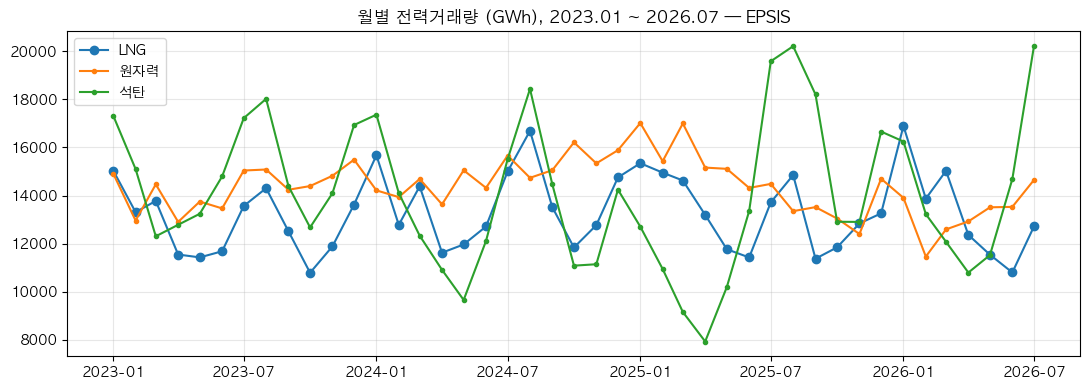

In [169]:
# 전체 11단계 중 → 2단계 데이터 수집과 구성 보기 · 월별 LNG·원전·석탄 그림 (EPSIS 기준, 2023.01~2026.07) · 앞 셀들을 먼저 실행한 뒤에 돌린다
# ── 그림 — 월별 LNG·원전·석탄, 2023.01~2026.07 (EPSIS 기준) ───────────
recent = ep[ep["month"] >= "2023-01-01"]
plt.figure(figsize=(11, 4))
plt.plot(recent["month"], recent["LNG"], marker="o", label="LNG")
plt.plot(recent["month"], recent["원자력"], marker=".", label="원자력")
plt.plot(recent["month"], recent["석탄계"], marker=".", label="석탄")
plt.title("월별 전력거래량 (GWh), 2023.01 ~ 2026.07 — EPSIS")
plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()


## ✍️ 내 생각

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: y값은 전력거래량이고(발전량이라고 생각하자) 우측은 시계열이다. 그러면 시간에 따라 이 특정한 에너지원이 얼마나 전기를 생성했는데 사용되었는지를 설명한다. 특이하게 보이는건 석탄이 엄청나게 요동치고 있다는 것, 특히 2025년 중반 매우 적게 연소되었다가 25년 여름쯔음에 많이 사용되고 있는데.. 이건 단순히 계절의 패턴과 다르다. 보통 석탄만 좁혀서 보면, 년단위로 끊어서 보면, 1월에 비해 7월 즉 여름이 더 많이 사용되는 것으로 보인다. 그리고 그 각 겨울과 여름의 사이 봄이나 가을의 경우 상대적으로 감소하는 경향을 띤다.

- 원자력은 25년도 1월까지 단기적으로 진동하지만 점차 늘어나는 경향성을 보이다가 26년 초까지 서서히 감소한다. 하지만 26년도 1월을 기점으로 다시금 올라가는데..? 이건 어떤 이유가 있을 것이다. 이것이 아마 우리가 보려는 여러 외적인 요소에 의해서 발전량을 늘린 이유이지 않을까??

- lNG를 보자. 진짜 마음대로 날아다니는데, 석탄과 비슷한 경향성을 보인다. 적합한 표현일지는 모르겠지만 녹색 선이 그림을 그리면 파란 선이 따라가는 느낌을 받는데? 이런건 정확하진 않은 표현인 것 같다. 쨌든 석탄과 비슷하게 계절의 영향을 그리고 있으며 겨울, 여름의 피크 지점에서 많이 사용된다. 

- 전체적인 에너지 생산, 그러니까 모든 생산량을 총 더하면 년도가 늘어남에 따라 에너지 총 사용량의 변화도 볼 수 있을 것이고, 거기에 해당하는 각 에너지원의 비중도 살펴야할 것 같다. 그러면 전체가 늘어난 비율 대비 상대적으로 얼마나 늘었는지, (같은 비율로 늘면 그냥 예전과 같은 것이고, 전체가 는것보다 조금만 늘어났다면 상대적으로 감소한 것이니까. 이건 경제의 인플레이션 개념과 비슷하다. 월급이 올라도 물가가 그것보다 더 오르면 실질소득이 감소한 것처럼)


- 24년도 8월에 lng데이터가 없는데 어떻게 그래프는 그려진거지?? 잘 모르겠다..



### 클로드 답 — 월별 그림

> **짧게**
>
> ① 이 그림은 EPSIS로 그렸습니다. 그래서 2024년 8월도 그려집니다.
> ② 석탄이 요동치는 것이 아니라 해마다 같은 계절 모양입니다.
> ③ **이 데이터에는 발전소에서 태운 LNG만 있습니다. 집 난방용 도시가스는 없습니다.**
> ④ 원전이 오르내리는 원인은 확인 못 합니다.


**맞게 읽으신 것**

- y가 전력거래량, x가 시간 — 맞습니다. 단위는 GWh이고 월 합계입니다.
- 석탄과 LNG가 계절을 따라 움직인다 — 맞습니다. 1월과 7~8월이 높고 봄·가을이 낮습니다.
- 「LNG가 석탄과 비슷한 경향성을 보인다」 — 맞습니다.
- 「전체 생산량을 다 더해서 연도별 총 사용량 변화를 보고, 각 에너지원의 비중을 봐야겠다」 — **맞는 판단이고, 물음 2에서 그 표를 만들었습니다.** 인플레이션 비유도 정확합니다. 전력시장계가 2024년에 0.9% 늘 때 LNG가 6.7% 늘어 몫이 28.2%에서 29.8%로 올라갔고, 2025년에 전체가 −0.4%일 때 LNG가 −2.8%라 몫이 29.1%로 내려갔습니다.

**다르게 읽으신 것**

1. **「2025년 중반 매우 적게 연소되었다가 여름쯤 많이 사용되는데, 이건 단순히 계절의 패턴과 다르다」 — 계절 패턴이 맞습니다.** 석탄의 저점은 봄(4~5월)과 가을(10월)이고 고점은 1월과 8월인데, 세 해가 같은 모양입니다. 2025년만 다른 것이 아닙니다. 「요동친다」로 읽히는 것이 실은 해마다 같은 모양의 되풀이입니다.
2. **「1월에 비해 7월, 즉 여름이 더 많이 사용되는 것으로 보인다」 — 석탄은 8월이 가장 높고 LNG는 1월이 가장 높습니다.** 겨울이 LNG의 최고점입니다(받아 둔 기간 전체의 최댓값은 2026년 1월 16,895.9 GWh입니다). **1단계에 적으신 2번 원인(추우면 난방 수요가 늘어 LNG 소모가 많다)과 관련이 있습니다** — 다만 이 자료는 발전용이라 난방용 도시가스는 안 들어 있고, 겨울이 높은 것이 난방 때문인지 다른 이유인지는 아직 모릅니다. 4단계에서 기온과 맞춰 봅니다.
3. **「원자력이 2026년 1월을 기점으로 다시 올라가는데, 이건 우리가 보려는 외적인 요소 때문이지 않을까」 — 원인을 지금 붙이면 안 됩니다.** 원전 발전량이 오르내리는 가장 흔한 까닭은 **계획예방정비**입니다. 원자로를 열여덟 달쯤 돌리면 연료를 갈아야 해서 한두 달 세웁니다. 어느 호기가 언제 섰는지는 공개 자료가 없어서(지침의 「발전기별 정비 기록」이 이것입니다) 저희는 **원인을 모른 채 결과만 입력으로 넣습니다.** 「왜 늘었나」가 아니라 「늘었다는 사실」만 모델에 알려 줍니다.
4. **「녹색 선이 그림을 그리면 파란 선이 따라가는 느낌」** — 창주 님도 「정확하진 않은 표현」이라 쓰셨는데 맞습니다. 그림에서 두 선이 같이 움직이는 것으로는 **어느 쪽이 먼저인지** 못 봅니다. 둘 다 같은 것(계절)에 반응하면 나란히 움직입니다. 순서를 보려면 시차를 두고 비교해야 하고, 그것은 4단계입니다.
5. **「2024년 8월에 LNG 데이터가 없는데 어떻게 그래프는 그려진 거지」 — 이 그림은 저희 API 데이터가 아니라 EPSIS 월별 표로 그렸습니다.** 셀 첫 줄에 「EPSIS 기준」이라고 적혀 있습니다. EPSIS는 전력거래소가 직접 집계한 숫자라 2024년 8월도 16,690.9 GWh로 멀쩡히 들어 있습니다. **깨진 것은 API로 받아 온 저희 파일이지 실제 발전량이 아닙니다.** 바꿔 말하면 2024년 8월에 LNG 발전은 정상으로 있었고, 그 시간별 내역을 저희가 못 받은 것입니다.

**📘 빅분기 연결 — 2과목 시각화와 상관의 해석**

필기에서 시계열 그림을 넷으로 나눠 봅니다.

- **추세** — 오래 두고 한 방향으로 가는 움직임. 이 그림에서는 신재생이 꾸준히 올라가는 것.
- **계절성** — **정해진 길이로 되풀이되는** 움직임. 석탄·LNG의 1월·8월 고점이 이것입니다. 되풀이되는지 보려면 최소 두 번은 돌아야 하고, 저희는 2023~2025년으로 세 번 봅니다.
- **주기** — 길이가 정해지지 않은 채 오르내리는 것. 경기 같은 것.
- **불규칙** — 나머지.

「단순히 계절의 패턴과 다르다」고 읽으신 대목이 계절성과 불규칙을 가르는 지점인데, **세 해를 겹쳐 놓고 같은 달끼리 비교해야** 갈립니다. 한 해만 쭉 이어 보면 계절성도 요동으로 보입니다.

그리고 「녹색이 그리면 파랑이 따라간다」에 붙는 필기 개념이 **교란**입니다. 아카데미에서 `spec_country`가 잘 맞는 것처럼 보였는데 실은 `steel_kind` 구성 때문이었던 것과 같은 모양입니다. 석탄과 LNG가 나란히 움직이는 것도 둘 사이에 관계가 있어서가 아니라 **둘 다 계절과 전력수요에 반응해서**일 수 있습니다. 이 프로젝트에서 석탄을 입력에 안 넣기로 한 이유 중 하나가 이것이고, 6단계에서 인과지도를 그릴 때 이 고리를 그립니다.

In [170]:
# 전체 11단계 중 → 2단계 데이터 수집과 구성 보기 · ASOS 기온과 API 파일 — 있는지·비었는지 본다 · 앞 셀들을 먼저 실행한 뒤에 돌린다
asos_dir = os.path.join(RAW, "asos")
asos = pd.concat([pd.read_csv(os.path.join(asos_dir, f), encoding="utf-8-sig")
                  for f in sorted(os.listdir(asos_dir)) if f.endswith(".csv")], ignore_index=True)   # 달마다 한 파일을 하나로
print("ASOS 행 수:", len(asos), "| 기간:", asos["tm"].min(), "~", asos["tm"].max())
for col in ["ta", "hm", "ws", "icsr"]:        # 기온·습도·풍속·일사
    if col in asos.columns:
        print(f"  {col} 빈 칸 수: {asos[col].isna().sum()}", "(일사는 밤에 비는 것이 정상)" if col == "icsr" else "")

print("\nAPI로 받은 해 — 하루 192행(연료 8종 × 24시간)이 아닌 날")
for 해 in (2024, 2026):
    파일 = sorted(glob.glob(os.path.join(RAW, "api", f"{해}*.csv")))
    빈 = [os.path.basename(f)[:8] for f in 파일 if os.path.getsize(f) < 100]          # 100바이트 미만 = 0행으로 온 날
    표 = pd.concat([pd.read_csv(f) for f in 파일 if os.path.getsize(f) >= 100], ignore_index=True)
    줄수 = 표.groupby("tradeYmd").size(); 이상 = 줄수[줄수 != 192]
    print(f"  {해}년 — 파일 {len(파일)}개 · 0행으로 온 날 {len(빈)}일 {빈} · 192행이 아닌 날 {len(이상)}일")
    for 행수, 날들 in 이상.groupby(이상).groups.items():                              # 행 수가 같은 날끼리 묶어서 본다
        print(f"      {행수}행으로 온 날 {len(날들)}일: {min(날들)} ~ {max(날들)}")


ASOS 행 수: 32136 | 기간: 2023-01-01 00:00 ~ 2026-08-31 23:00
  ta 빈 칸 수: 0 
  hm 빈 칸 수: 0 
  ws 빈 칸 수: 68 
  icsr 빈 칸 수: 14444 (일사는 밤에 비는 것이 정상)

API로 받은 해 — 하루 192행(연료 8종 × 24시간)이 아닌 날
  2024년 — 파일 366개 · 0행으로 온 날 1일 ['20240229'] · 192행이 아닌 날 31일
      120행으로 온 날 31일: 20240801 ~ 20240831
  2026년 — 파일 191개 · 0행으로 온 날 1일 ['20260517'] · 192행이 아닌 날 15일
      48행으로 온 날 14일: 20260503 ~ 20260516
      120행으로 온 날 1일: 20260502 ~ 20260502


## ✍️ 내 생각

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: asos는 기상관측 자료다. 세부적인 데이터들이 굉장히 많은데 다 쓸 필요는 없고 필요한 것들을 가져와야할 것이다. ta, hm, ws, icsr네 개를 일단 코드상에선 가져온 것이다. ta는 온도, hm은 뭘까? 아래 찾아본 값이다. 온도, 상대습도, 일사량은 태양에너지 때문인 것 같고. 풍속은 풍력 재생에너지 데이터에 필요해서인가?? 다른건 상대습도는 왜 들고온거지 잘 모르겠네??

일단 26년도 데이터가 다 모이진 않았는데 8월 31일까지는 모일 수 있나?? icsr은 밤에 비는 것이 정상이라면, 그 비는 비율이 비슷해야 할 것. 일조량에 따라 혹시 잘못 적힌 값은 없는지 살펴봐야 할 것. 보통 여름이 일조가 길고, 겨울이 짧은데..

2024년 api파일수 366개다. 보니까 위에서 본 것처럼 0행으로 온 날은 2월 29일 그러니까 이 날짜는 결측치로 보고 그냥 삭제하는 방향이 적절해 보이고, 192행이 아닌 날 31일은 위에서 본 8월일 것이다. 192행이 아니라는건 데이터 값들이 적혀 있는데 우리가 비교하는 어떤 영역에 속한 값들이 적혀있지 않다는 의미일 것이다.

2026년을 보면, 0행으로 온 날 1일은 2월 29일처럼 이것도 삭제하는 방향이 맞을 것 같고, 아닌 날 15일은 따로 각각을 분석해봐야겠다. 48행이 14일, 120행은 1일이라니.. 이거 도대체 뭐 어떻게 데이터가 적혀온걸까? 살펴봐야겠다. 그리고 그 전에 우리가 진짜 사용하려는 데이터가 어떤 데이터인지도 알아야겠지. 예컨대 48행으로 왔다고 해도 우리가 필요한 데이터가 이 48행 안에 다 들어가 있다면 지금 뭐 적게 온 상황 자체가 문제라고 볼 수는 없으니까.

컬럼	의미	단위	첫 행 값
ta	기온 (Temperature of Air)	°C	0.9
hm	상대습도 (HuMidity)	%	72
icsr	일사량 (Incoming Solar Radiation)	MJ/m² (시간 누적)	공란
ws	풍속 (Wind Speed)	m/s	1.4
참고로 같이 들어있는 관련 컬럼들:

wd = 풍향 (16방위, 200 = 남남서쪽)
td = 이슬점온도, pv = 수증기압
pa = 현지기압, ps = 해면기압
ss = 일조시간(hr), icsr와 짝
ts = 지면온도, m005Te~m03Te = 지중온도(5cm/10cm/20cm/30cm)
*Qcflg = 해당 값의 품질검사 플래그 (9 = 결측/오류 처리, 공란 = 정상)


### 클로드 답 — ASOS·API 파일 상태

> **짧게**
>
> ① 풍속은 풍력 때문이 아니라 딸려 온 칸이고, 입력에 안 씁니다.
> ② ASOS는 2026년 8월 31일까지 다 받았습니다. 덜 받은 것은 발전량 API입니다.
> ③ 2026년에 0행으로 온 날은 2월 29일이 아니라 5월 17일입니다.


**맞게 읽으신 것**

- ASOS가 기상관측 자료라는 것, 네 칸(ta·hm·icsr·ws)만 가져온 것 — 맞습니다. 찾아 적으신 열 뜻 표도 맞습니다.
- 「icsr은 밤에 비는 것이 정상이라면 그 비는 비율이 비슷해야 할 것」 — **이것이 검사가 됩니다.** 물음 3에서 그 표를 만들었습니다.
- 2024년 0행으로 온 날이 2월 29일이라는 것 — 맞습니다.
- 「192행이 아닌 날 31일은 위에서 본 8월」 — 맞습니다. 20240801~20240831입니다.
- 「192행이 아니라는 건 우리가 비교하는 어떤 영역에 속한 값들이 적혀 있지 않다는 의미」 — 맞습니다. 120행이면 연료 5종 × 24시간이라 세 종이 통째로 빠진 것입니다.
- 「48행으로 왔다고 해도 우리가 필요한 데이터가 그 안에 다 들어가 있다면 적게 온 것 자체가 문제라고 볼 수는 없다」 — **이 판단이 맞습니다.** 행 수가 적은 것 자체가 아니라 **LNG가 그 안에 있느냐**가 문제입니다. 물음 1·6에서 확인하셨고, 48행짜리에는 수력·양수만 있어 LNG가 없습니다.

**다르게 읽으신 것**

1. **「hm은 왜 들고온 거지」 · 「풍속은 풍력 재생에너지 데이터에 필요해서인가」**
   - **습도(hm)** — 습도가 높으면 같은 기온이라도 체감이 달라 냉방 부하가 달라집니다. 가스터빈은 들이마시는 공기가 덥고 습할수록 출력이 떨어지기도 합니다. 넣을지 말지는 **5단계에서 정하실 것**이고 지금은 받아만 둔 것입니다.
   - **풍속(ws)** — 풍력 때문이 아닙니다. 지침에 적은 입력 후보 여덟에 풍력은 없습니다. ASOS 시간자료를 받으면 여러 칸이 한꺼번에 딸려 오는데 그중 넷을 남긴 것입니다. 풍속은 지금으로선 쓸 데가 없고, 그래서 **풍속 빈 칸 68개는 모델에 영향이 없습니다.** 물음 5·8에서 본 것은 「이 자료가 어떻게 생겼나」를 익히는 연습에 가깝습니다.
2. **「2026년 데이터가 다 모이진 않았는데 8월 31일까지는 모일 수 있나」 — ASOS는 이미 8월 31일까지 다 받았습니다.** 셀 첫 줄에 2023-01-01 00시부터 2026-08-31 23시까지로 나옵니다. 덜 모인 것은 **발전량 API**입니다. 기상 자료와 발전량 자료는 출처가 달라 받은 기간도 다릅니다. **한쪽의 진도로 다른 쪽을 짐작하면 안 됩니다.**
3. **「2026년 0행으로 온 날 1일은 2월 29일처럼」 — 2026년은 윤년이 아닙니다.** 0행으로 온 날은 **5월 17일**입니다. 성격도 다릅니다. 2024년 2월 29일은 그 날짜 자체가 API에 없는 것이고, 2026년 5월 17일은 있어야 할 날인데 안 온 것입니다. 5월 2일(120행)·3~16일(48행)과 한 덩어리로 **5월 2일부터 17일까지 16일이 이어서 깨졌습니다.**
4. **「2026년 15일은 따로 각각을 분석해봐야겠다」 — 맞는 방향이고 물음 6에서 보셨습니다.** 결과는 「5월 2일은 120행인데 LNG 하루 합이 1,047 MWh(정상인 5월 1일은 328,788) · 5월 3~16일은 48행이고 수력·양수뿐이라 LNG가 아예 없음」입니다.
5. **2026년이 왜 중요한지 한 번 더.** 2026년은 학습에도 채점에도 안 씁니다. **9단계에서 「모델이 예측한 값」과 「실제 값」을 비교할 때만 씁니다.** 그러니 5월 2~17일이 깨진 것은 모델을 망치는 게 아니라 **9단계에서 비교할 날이 16일 줄어드는 것**입니다. 적용 구간 1~6월 181일 가운데 16일이니 8.8%입니다.

**📘 빅분기 연결 — 2과목 데이터 수집과 자료의 이질성**

여러 출처를 쓸 때 필기가 짚는 것이 **출처마다 기준이 다르다**는 것입니다. 저희 자료 넷을 늘어놓으면 그대로 보입니다.

| 자료 | 잘게 나눈 단위 | 기간 | 시각 표기 | 갱신 |
|---|---|---|---|---|
| KPX 연간 파일 | 시간별·연료별 | 2023·2025 | 1~24 | 해가 끝나고 한 번 |
| 발전량 API | 시간별·연료별 | 2024·2026 | 1~24 | 날마다 |
| ASOS | 시간별·관측소별 | 2023~2026.08 | 0~23 | 날마다 |
| EPSIS | 월별·연료별 | 2002~2026.07 | 없음 | 달마다 |

이것을 하나로 합치려면 **가장 거친 쪽에 맞춰야** 합니다. EPSIS가 월별이니 저희 시간별을 월로 합쳐서 비교했습니다. 반대는 안 됩니다 — 월 합계를 24로 나눠 시간별을 만들면 없던 정보를 지어내는 것입니다.

시각 표기도 그렇습니다. KPX·API는 1~24로 「그 시간대의 끝」을 적고 ASOS는 0~23으로 「그 시간대의 시작」을 적습니다. 그대로 조인하면 한 시간씩 밀립니다. 준비 셀에서 `- 1`을 한 것이 이 조정이고, 5단계에서 기온을 붙일 때 실제로 걸립니다. 필기에서 「데이터 통합 시 단위·형식 표준화」라고 부르는 대목이 이것입니다.

## 2026년은 어디까지 받았나

위 셀들이 본 것은 학습과 채점에 쓸 2023·2024·2025년입니다. 2026년은 예측한 값과 비교할 해라서 따로 봅니다. 아직 받는 중이라 다른 해와 평균을 대 보면 오해를 부릅니다 — 1~7월만 있어서 여름이 절반만 들어가 있습니다. 그래서 여기서는 비교하지 않고 지금 상태만 봅니다.

아래 셀은 어디까지 받았는지와, 달을 다 받은 달의 LNG 합계가 EPSIS 월별 표와 맞는지를 찍습니다.


In [171]:
# 전체 11단계 중 → 2단계 데이터 수집과 구성 보기 · 2026년은 어디까지 받았고 달 합계가 EPSIS와 맞는지 본다 · 앞 셀들을 먼저 실행한 뒤에 돌린다
lng26 = load_api(2026)                                                    # API로 받은 2026년 전체
lng26 = lng26[lng26["fuel"] == "LNG"].copy()                              # LNG 행만
lng26["ts"] = pd.to_datetime(lng26["date"]) + pd.to_timedelta(lng26["hour"].astype(int) - 1, unit="h")
print("2026년 LNG —", lng26["ts"].min().strftime("%m-%d"), "~", lng26["ts"].max().strftime("%m-%d"),
      f"· {len(lng26)}시각 · 중복 {lng26['ts'].duplicated().sum()}개")

표 = lng26.groupby(lng26["ts"].dt.strftime("%Y%m")).agg(받은시각=("mwh", "size"), 우리_GWh=("mwh", "sum"))
표["우리_GWh"] = (표["우리_GWh"] / 1000).round(1)                          # MWh를 GWh로
표["그달시각"] = [pd.Period(m, freq="M").days_in_month * 24 for m in 표.index]   # 그 달 전체 시각 수
표["다받음"] = ["예" if a == b else "아니오" for a, b in zip(표["받은시각"], 표["그달시각"])]
표["EPSIS_GWh"] = ep.set_index(ep["month"].dt.strftime("%Y%m"))["LNG"].round(1)   # 같은 달의 EPSIS 값
표["차이_%"] = ((표["우리_GWh"] - 표["EPSIS_GWh"]) / 표["EPSIS_GWh"] * 100).round(2)
print("\n2026년 월별 LNG — 우리가 받은 것과 EPSIS 월별 표")
print(표[["받은시각", "그달시각", "다받음", "우리_GWh", "EPSIS_GWh", "차이_%"]].to_string())


2026년 LNG — 01-01 ~ 07-10 · 4224시각 · 중복 0개

2026년 월별 LNG — 우리가 받은 것과 EPSIS 월별 표
        받은시각  그달시각  다받음   우리_GWh  EPSIS_GWh   차이_%
ts                                                
202601   744   744    예  16895.9    16895.9   0.00
202602   672   672    예  13873.5    13873.5   0.00
202603   744   744    예  15028.6    15028.6   0.00
202604   720   720    예  12366.1    12366.1   0.00
202605   384   744  아니오   5799.3    11542.9 -49.76
202606   720   720    예  10790.8    10804.4  -0.13
202607   240   744  아니오   3800.0    12717.1 -70.12


## ✍️ 내 생각

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 위에서 비교한 것과 같다. 월별로 우리가 받은 데이터와 epsis가 제시한 데이터를 비교해서 원하는 데이터가 다 제대로 모였는지 비교하는 것. 지금 시점에서 4월 며칠 144개가 받아졌는데 144개면 보통 하루 24시간을 기준으로 한다면 6일 더 받아진 것이겠지? 일단 차분히 더 모아야 진행이 되겠다. 1~3월에는 사용할 수 있겠다. 데이터 상의 문제가 없다.

- 5월 부터 문제가 발생했다. 5월 7월 문제가 꽤 큰데...? 6월의 이정도는 그냥 무시해도 괜찮을 것 같은데.. 다 각각 어떻게 데이터를 세부적으로 보고 방향을 정해야할 것으로 보인다.


### 클로드 답 — 2026년은 어디까지 받았나

> **짧게**
>
> ① 4월은 다 받았습니다. 덜 받은 달은 5월과 7월입니다.
> ② 5월과 7월은 원인이 반대입니다. 7월은 아직 안 올라온 것이고, 5월은 깨져서 온 것입니다.


**맞게 읽으신 것**

- 「위에서 비교한 것과 같다. 월별로 우리가 받은 데이터와 EPSIS를 비교해서 제대로 모였는지 본다」 — 맞습니다.
- 「1~3월은 사용할 수 있겠다. 데이터 상의 문제가 없다」 — 맞습니다. 차이 0.00%입니다.
- 「5월부터 문제가 발생했다. 5월·7월 문제가 꽤 크다. 6월 이 정도는 무시해도 괜찮을 것 같다」 — 맞습니다. 5월 −49.76%, 7월 −70.12%, 6월 −0.13%입니다.
- 「각각 어떻게 데이터를 세부적으로 보고 방향을 정해야 할 것으로 보인다」 — 맞는 판단이고 물음 6에서 보셨습니다.

**다르게 읽으신 것**

1. **「4월 며칠 144개가 받아졌는데 6일 더 받아진 것이겠지」 — 표를 다른 줄로 보신 것 같습니다.** 지금 표에서 4월은 720시각을 다 받았고(「다받음: 예」) EPSIS와 0.00%입니다. 덜 받은 달은 **5월(744 중 384)과 7월(744 중 240)** 둘입니다. 아마 그 전에 돌리셨을 때의 숫자를 보신 듯합니다. 지금 표 기준으로는 1·2·3·4·6월이 다 찼습니다.
2. **5월과 7월은 「모자란다」로 같아 보이지만 원인이 반대입니다.**
   - **7월** — 아직 API에 안 올라온 것입니다. 7월 11일부터 없습니다. **기다리면 옵니다.** 남은 날을 받으면 채워집니다.
   - **5월** — 날짜는 왔는데 그 안이 깨진 것입니다. 5월 2~17일 16일이 120행·48행·0행으로 왔습니다. **다시 요청해도 같을 가능성이 큽니다**(2024년 8월이 그랬습니다). 호출 여유가 생기면 5월 가운데 하루를 다시 요청해 확인하겠습니다.
3. **6월 −0.13%는 무시해도 되는 것이 맞습니다.** 720시각을 다 받았고 차이가 13.6 GWh입니다. 다만 「왜 0.00%가 아닌가」는 **확인 불가**입니다. 2023년 11·12월의 0.1%와 같은 성격으로 보이지만 원인을 모릅니다.

**📘 빅분기 연결 — 4과목 데이터 누수**

이 셀이 2026년을 다루니 한 번 짚어 둡니다. 누수는 **모델이 실제로는 알 수 없었을 정보를 미리 알고 배우는 것**입니다. 그러면 채점 점수가 실제보다 좋게 나오고 진짜 새 데이터에서는 무너집니다.

시계열에서 흔한 두 가지입니다.

- **미래를 섞는 것** — 2023~2026년을 통째로 섞어 무작위로 8 대 2로 나누면, 2026년 3월 값으로 배운 모델이 2026년 1월을 맞히게 됩니다. 실제 상황에서는 있을 수 없는 일입니다. 지침에서 **무작위 k-fold를 쓰지 않고 시간순으로 자른다**고 정한 이유입니다.
- **정답이 입력에 섞여 드는 것** — 석탄과 총 전력수요를 입력에 넣으면 LNG = 총량 − 나머지라는 뺄셈이 됩니다. 모델이 맞히는 것이 아니라 답을 옮겨 적는 것이 됩니다. 지침에서 이 둘을 뺀 이유입니다.

그래서 2026년은 **학습에도 채점에도 안 들어갑니다.** 2단계에서 2026년을 보는 것은 「나중에 비교할 자료가 어떻게 생겼나」를 미리 확인하는 것이고, 여기서 본 것이 모델을 고치는 데 쓰이면 그것도 누수입니다. 지침의 「2026년에 맞추려고 모델을 고치지 않습니다」가 이 뜻입니다.

---

# 추가 확인 1

위 칸들을 적으면서 나온 물음 셋입니다. 창주 님이 쓰신 말 그대로 옮겼습니다.


## 물음 1 — 이상하게 결과가 나온 날 구성요소는?

> 「24년도 데이터의 어느 부분에 문제가 생겼는지 확인해야겠다」
> 「48행이 14일, 120행은 1일이라니.. 이거 도대체 뭐 어떻게 데이터가 적혀온걸까? 살펴봐야겠다. 그리고 그 전에 우리가 진짜 사용하려는 데이터가 어떤 데이터인지도 알아야겠지. 예컨대 48행으로 왔다고 해도 우리가 필요한 데이터가 이 48행 안에 다 들어가 있다면 지금 뭐 적게 온 상황 자체가 문제라고 볼 수는 없으니까」
> 「5월 7월 문제가 꽤 큰데...? 6월의 이정도는 그냥 무시해도 괜찮을 것 같은데.. 다 각각 어떻게 데이터를 세부적으로 보고 방향을 정해야할 것으로 보인다」


<div style="border: 2px solid var(--vscode-focusBorder, #3794ff); border-left-width: 6px; border-radius: 8px; padding: 4px 18px 10px; background: var(--vscode-textBlockQuote-background, rgba(127, 127, 127, 0.1));">

## 📌 물음 1 결론

**왜 생긴 물음인가** — 「ASOS·API 파일 상태」 셀에서 2026년에 48행·120행으로 온 날을 보고 「48행으로 왔다고 해도 우리가 필요한 데이터가 이 48행 안에 다 들어가 있다면 지금 뭐 적게 온 상황 자체가 문제라고 볼 수는 없으니까」라고 적었다. 그날들에 어떤 연료가 들어 있는지 본 물음이다.

### 결정 — 120행인 날은 무연탄·원자력·유전이 빠진 5종이고, 48행인 날은 수력·양수뿐이라 LNG가 없어서 못 쓴다

**결정 근거** — 물음 1 셀에서 정상인 날은 192행(연료 8종 × 24시간)이었다. 120행인 날은 2024년 8월 전체와 2026년 5월 2일이고, 48행인 날은 2026년 5월 3~16일이다. 판단은 물음 1 아래 「✍️ 내 생각」에 적었다.

**남은 것** — 120행인 2024년 8월은 LNG만 떼어 쓸 수 있는지 물음 4에서 봤다(못 쓴다). 뺄지는 3단계 물음 1에서 정했다(뺐다).

</div>

In [172]:
# 전체 11단계 중 → 2단계 데이터 수집과 구성 보기 · 물음 1 — 행 수가 네 가지(192·120·48·0)로 오는데 각각 무엇이 들어 있나 · 앞 셀들을 먼저 실행한 뒤에 돌린다
기준 = sorted(pd.read_csv(os.path.join(RAW, "api", "20240731.csv"))["fuelTpCd"].unique())   # 정상인 날에 오는 연료 8종
볼날 = [("20240731", "정상 기준"), ("20240801", "120행"), ("20260502", "120행"),
        ("20260503", "48행"), ("20240229", "0행")]

줄 = []                                                                   # 먼저 다섯 날을 한 표로 요약한다
상세 = {}
for ymd, 표시 in 볼날:
    경로 = os.path.join(RAW, "api", f"{ymd}.csv")
    크기 = os.path.getsize(경로)
    if 크기 < 100:                                                         # 100바이트 미만 = 표로 못 읽는 날
        줄.append({"날짜": ymd, "": 표시, "바이트": 크기, "행": 0, "연료종수": 0,
                   "빠진연료": ", ".join(기준), "LNG_하루합": None})
        상세[ymd] = open(경로, encoding="utf-8-sig").read()
        continue
    d = pd.read_csv(경로)
    있는 = sorted(d["fuelTpCd"].unique())
    빠진 = [f for f in 기준 if f not in 있는]
    lng = d.loc[d["fuelTpCd"] == "LNG", "amgo"].sum()
    줄.append({"날짜": ymd, "": 표시, "바이트": 크기, "행": len(d), "연료종수": len(있는),
               "빠진연료": ", ".join(빠진) if 빠진 else "없음", "LNG_하루합": round(lng)})
    상세[ymd] = d.groupby("fuelTpCd")["amgo"].agg(["size", "sum"]).round(0).rename(columns={"size": "행", "sum": "하루합_MWh"})

정상2026 = sorted(pd.read_csv(os.path.join(RAW, "api", "20260501.csv"))["fuelTpCd"].unique())  # 2026년 정상인 날
print("정상인 날에 오는 연료 8종:", 기준)
print("2026년 정상인 날(5월 1일)도 같은 8종인가:", 정상2026 == 기준, "— 같으니 기준은 2024년 하나로 둔다")
print("행 수는 연료 종수 × 24시간이다. 192행=8종 · 120행=5종 · 48행=2종 · 0행=아무것도 없음")
print()
print(pd.DataFrame(줄).to_string(index=False))

print("\n날마다 연료별로 자세히")
for ymd, 표시 in 볼날:
    print(f"\n[{ymd}] {표시}")
    print(상세[ymd] if not isinstance(상세[ymd], str) else f"  파일에 든 글자: {상세[ymd]!r}")


정상인 날에 오는 연료 8종: ['LNG', '무연탄', '수력', '신재생·기타', '양수', '원자력', '유연탄', '유전']
2026년 정상인 날(5월 1일)도 같은 8종인가: True — 같으니 기준은 2024년 하나로 둔다
행 수는 연료 종수 × 24시간이다. 192행=8종 · 120행=5종 · 48행=2종 · 0행=아무것도 없음

      날짜        바이트   행  연료종수                                   빠진연료  LNG_하루합
20240731 정상 기준 6368 192     8                                     없음 471306.0
20240801  120행 3899 120     5                           무연탄, 원자력, 유전   9642.0
20260502  120행 3851 120     5                           무연탄, 원자력, 유전   1047.0
20260503   48행 1410  48     2         LNG, 무연탄, 신재생·기타, 원자력, 유연탄, 유전      0.0
20240229    0행    4   0     0 LNG, 무연탄, 수력, 신재생·기타, 양수, 원자력, 유연탄, 유전      NaN

날마다 연료별로 자세히

[20240731] 정상 기준
           행   하루합_MWh
fuelTpCd              
LNG       24  471306.0
무연탄       24    7646.0
수력        24   19266.0
신재생·기타    24  110473.0
양수        24   11159.0
원자력       24  465688.0
유연탄       24  578091.0
유전        24     130.0

[20240801] 120행
           행   하루합_MWh
fuelTpCd              
LNG       24  

## ✍️ 내 생각

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답:정상인 192행의 경우 8종이다. 그러니까 24시간을 기준으로 한다면, 8종이라면 192행의 데이터가 와야하는 것. 
24년도 8월을 보면, 무연탄, 원자력, 유전?? 이라는 유전은 뭘까? 원유겠지?? 무연탄 유연탄은 석탄인것 같은데 따로 구분을 두나보다. 이건 뭐 크게 중요친 않은데.. 일단 데이터 구성을 보자. 3개의 데이터가 빠져있으니까 전체적인 데이터를 비교하는데 문제가 있다. 대신 24년도 8월에 lng는 있으니까 그건 어떻게 lng만 따로 떼서 이용할 수는 있는거 아닌가?? 모델링하는데 문제가 없지 않을까??

- 그리고 26년 5월 2일도 24년 8월과 비슷한데 lng하루합?? 이거 결과 위치가 조금 행이 이상하게 적혀서 모르겠는데 하루 합 자체가 이상하다. 24년도 8월과 비슷하면 그래도 양이 비슷하게 찍혀야 하는데 이렇게 적은건 뭐 부족한거 아니야?? 

- 26년 5월을 보자. 적힌게 2개구나.. 보면 수력과 양수 자료만 있는 것으로 보이고,.. 이런건 어떻게 써야하지?? 아니 못쓸 것 같다. lng데이터가 없으니까. 24년 2월 29일과 마찬가지로 그냥 없애야할 것 같은데..? 다른 방법이 있나? 클로드에게 물어보고 선택지가 무엇이 있는지 탐구해보자.

---

→ **어디로 이어졌나** — 여기서 「클로드에게 물어보고 선택지가 무엇이 있는지 탐구해보자」고 적으셨습니다. 2024년 8월을 뺄지 남길지는 **3단계 물음 1**에서 정합니다. 2026년 5월 2~17일을 어떻게 할지도 **3단계**입니다.


### 클로드 답 — 물음 1

> **짧게**
>
> ① 「유전」은 기름을 태우는 발전입니다. EPSIS의 「유류」와 같은 값인 것을 확인했습니다.
> ② 2024년 8월 LNG는 값이 틀려서 따로 떼서도 못 씁니다.
> ③ 120행짜리 둘(2024년 8월·2026년 5월 2일)은 모양은 같은데 남은 LNG 값이 아홉 배 다릅니다.


**맞게 읽으신 것**

- 「정상인 192행은 8종. 24시간 기준이면 8종일 때 192행이 와야 한다」 — 맞습니다. 192 = 8 × 24입니다.
- 「3개의 데이터가 빠져 있으니 전체적인 데이터를 비교하는 데 문제가 있다」 — 맞습니다. 2024년 8월과 2026년 5월 2일은 둘 다 **무연탄·원자력·유전**이 빠진 5종입니다. 빠진 연료가 두 날에 똑같습니다.
- 「26년 5월 3일은 적힌 게 2개. 수력과 양수 자료만 있다. 이런 건 못 쓸 것 같다, LNG 데이터가 없으니까」 — 맞습니다. LNG 하루합이 0.0으로 찍힌 것이 그 뜻입니다.

**다르게 읽으신 것**

1. **「유전은 뭘까? 원유겠지?」 — 기름을 태우는 발전(중유·경유)입니다.** 이건 **확인했습니다.** 2024년 7월 한 달을 더해 보니 API의 「유전」이 5.7 GWh이고, EPSIS 같은 달 「유류」가 5.663 GWh입니다. 같은 항목입니다. 양이 아주 작은 것도 맞습니다 — 2024년 7월 31일 하루 합이 130 MWh인데 같은 날 LNG는 471,306 MWh입니다. 3,600분의 1입니다. 기름 발전은 지금 거의 안 씁니다.
2. **「무연탄 유연탄은 석탄인 것 같은데 따로 구분을 두나 보다」 — 맞습니다.** 둘 다 석탄인데 종류가 다릅니다. 유연탄은 발전소에서 태우는 주력 석탄이고(2024년 7월 31일 578,091 MWh), 무연탄은 양이 훨씬 적습니다(같은 날 7,646 MWh). EPSIS 표에서도 둘을 묶어 「석탄계」로 냅니다.
3. **「24년 8월에 LNG는 있으니까 LNG만 따로 떼서 이용할 수는 있는 거 아닌가? 모델링하는 데 문제가 없지 않을까?」 — 이 물음의 답이 물음 4입니다.** 답은 **못 씁니다**입니다. 8월 LNG 값이 있기는 한데 그 값 자체가 틀렸습니다. 8월 1일 하루 합이 9,642 MWh인데 7월 31일은 471,306 MWh입니다. 49분의 1입니다. **행이 있는 것과 값이 맞는 것은 다른 일입니다.**
4. **「26년 5월 2일도 24년 8월과 비슷하면 그래도 양이 비슷하게 찍혀야 하는데 이렇게 적은 건 뭐 부족한 거 아니야?」 — 「비슷하다」가 행 구성에만 해당합니다.** 둘 다 120행·5종이고 빠진 연료도 같습니다. 그런데 남아 있는 LNG 값은 8월 1일이 9,642, 5월 2일이 1,047로 아홉 배 차이가 납니다. **깨지는 방식이 같아도 남은 값이 같은 것은 아닙니다.** 둘 다 못 쓴다는 결론은 같습니다.
5. **「26년 5월 3일은 24년 2월 29일과 마찬가지로 그냥 없애야 할 것 같은데? 다른 방법이 있나?」** — 선택지를 아래에 적습니다.

**2026년 5월 2~17일을 어떻게 할 것인가 — 고르실 것과 그 대가**

먼저 전제 둘을 분명히 해 둡니다. ⓐ 2026년은 **학습에도 채점에도 안 들어갑니다.** 9단계에서 「예측한 값 대 실제 값」을 비교할 때만 씁니다. ⓑ 그러니 이 16일을 어떻게 하든 **모델 자체는 달라지지 않습니다.** 달라지는 것은 9단계에서 비교할 날의 수입니다.

- **빼고 간다(그 16일은 9단계 비교에서 제외)** — 적용 구간 1~6월 181일 중 165일로 비교합니다. 대가는 5월이 얇아지는 것입니다. 5월 31일 중 15일만 남습니다. 월별로 잔차를 볼 때 5월만 표본이 절반이라는 것을 한계에 적어야 합니다.
- **EPSIS 월 합계로 5월을 채운다** — EPSIS에 2026년 5월 LNG가 11,542.9 GWh로 있습니다. 그런데 저희 정답은 **시간별**입니다. 월 합계를 744로 나눠 시간별을 만들면 없던 정보를 지어내는 것이고, 그 값으로 모델을 채점하면 「평평한 값을 얼마나 잘 맞히나」를 보게 됩니다. **권하지 않습니다.**
- **5월은 월 단위로만 비교한다** — 시간별 비교에서는 5월을 빼고, 월별 그림에서만 EPSIS 월 합계로 5월을 넣습니다. 9단계 결과가 시간별 표와 월별 표 둘로 나뉘는데, 지침에 이미 「예측 대 실제(시간별·월별)」로 적혀 있으니 무리가 없습니다.
- **다시 요청해 본다** — 2024년 8월은 다시 요청해도 같았습니다. 5월도 같을 가능성이 크지만 확인은 안 해 봤습니다. 호출 여유가 생기면 5월 가운데 하루를 다시 요청해 보겠습니다. 한 건이면 됩니다.

**제 제안은 세 번째입니다.** 시간별 비교에서 16일을 빼되 월별 비교에는 EPSIS로 5월을 남기면, 잃는 것 없이 5월이 통째로 사라지는 것만 막습니다. 다만 정하시는 것은 창주 님이고, 실제로 정하는 곳은 **3단계**입니다. 2단계에서는 「이런 상태다」까지 확인하면 됩니다.

**📘 빅분기 연결 — 2과목 데이터 품질과 이상값의 원인 규명**

필기에서 이상값 처리를 「탐지 → **원인 규명** → 처리」 순으로 놓습니다. 가운데 단계를 건너뛰지 말라는 것이 요지입니다.

원인에 따라 처리가 달라지기 때문입니다.

- **측정·수집 오류** — 원래 값이 따로 있는데 잘못 들어온 경우. 지우거나 바른 값으로 바꿉니다. 2024년 8월과 2026년 5월이 여기입니다. EPSIS에 정상 값이 있으니 **실제 발전은 정상이었고 수집만 깨졌다**는 것이 확인됩니다.
- **실제로 일어난 일** — 값이 튄 것이 사실인 경우. 지우면 안 됩니다. 정비로 발전기가 섰거나 공휴일이라 수요가 적었던 날이 여기입니다.

이 둘을 안 가르고 「IQR 밖이니 지운다」로 처리하면 **실제로 일어난 드문 일을 없애 버립니다.** 그러면 모델은 평소만 배우고 드문 날에는 크게 틀립니다. 지침에 「원인 없이 제거하지 않습니다」라고 적어 둔 것이 이 뜻입니다.

그리고 이 물음이 보여 준 것이 하나 더 있습니다. **「행 수가 적다」는 것 자체는 판정이 아닙니다.** 48행이어도 필요한 연료가 그 안에 있으면 쓸 수 있고, 192행이어도 값이 틀렸으면 못 씁니다. 창주 님이 앞 칸에서 쓰신 그대로입니다.

## 물음 2 — 해마다 연료별 비중이 어떻게 달라졌나

> 「전체적인 에너지 생산, 그러니까 모든 생산량을 총 더하면 년도가 늘어남에 따라 에너지 총 사용량의 변화도 볼 수 있을 것이고, 거기에 해당하는 각 에너지원의 비중도 살펴야할 것 같다. 그러면 전체가 늘어난 비율 대비 상대적으로 얼마나 늘었는지, (같은 비율로 늘면 그냥 예전과 같은 것이고, 전체가 는것보다 조금만 늘어났다면 상대적으로 감소한 것이니까. 이건 경제의 인플레이션 개념과 비슷하다. 월급이 올라도 물가가 그것보다 더 오르면 실질소득이 감소한 것처럼)」


<div style="border: 2px solid var(--vscode-focusBorder, #3794ff); border-left-width: 6px; border-radius: 8px; padding: 4px 18px 10px; background: var(--vscode-textBlockQuote-background, rgba(127, 127, 127, 0.1));">

## 📌 물음 2 결론

**왜 생긴 물음인가** — 「월별 그림」 아래에 「전체가 늘어난 비율 대비 상대적으로 얼마나 늘었는지」를 봐야 한다고 적었다. 전체 거래량 대비 연료별 비중이 해마다 어떻게 달라졌는지 본 물음이다.

### 결정 — 없음. 2024년은 석탄이 줄고 LNG가 늘었고, 2025년은 반대였다는 것까지 봤다

**멈춘 이유** — 물음 2 셀에서 전년 대비로 2024년은 석탄 −9.8%·LNG +6.7%, 2025년은 석탄 +2.1%·LNG −2.8%로 방향이 뒤집힌 것을 봤다. 물음 2 아래 「✍️ 내 생각」에 「여긴 뭐 다른 이유가 있나 이런 것도 추가적으로 지금 봐야하는게 맞겠지??」라고 물었고, 가격 자료를 받지 않아서 이 프로젝트로는 확인할 수 없다는 답에서 멈췄다.

**남은 것** — 가격은 10단계(그 답을 숫자로 내는 단계)에서 해석 재료로만 쓴다.

</div>

In [173]:
# 전체 11단계 중 → 2단계 데이터 수집과 구성 보기 · 물음 2 — 해마다 연료별 비중이 어떻게 달라졌나 (EPSIS 연간 합계) · 앞 셀들을 먼저 실행한 뒤에 돌린다
연 = ep[ep["month"].dt.year.between(2023, 2025)].groupby(ep["month"].dt.year)[
     ["LNG", "원자력", "석탄계", "신재생계", "전력시장계"]].sum().round(0)          # 해마다 연료별 연간 합계
print("연간 전력거래량 (GWh) — EPSIS")
print(연.to_string())

몫 = (연[["LNG", "원자력", "석탄계", "신재생계"]].div(연["전력시장계"], axis=0) * 100).round(1)
print("\n전력시장계에서 차지하는 몫 (%)")
print(몫.to_string())

print("\n전년 대비 증감 (%) — 전체가 는 것보다 덜 늘면 몫은 줄어든다")
print((연.pct_change() * 100).round(1).dropna().to_string())


연간 전력거래량 (GWh) — EPSIS
            LNG       원자력       석탄계     신재생계     전력시장계
month                                                 
2023   153501.0  171550.0  178897.0  33697.0  544482.0
2024   163730.0  178749.0  161387.0  37818.0  549387.0
2025   159227.0  175549.0  164790.0  41082.0  547119.0

전력시장계에서 차지하는 몫 (%)
        LNG   원자력   석탄계  신재생계
month                        
2023   28.2  31.5  32.9   6.2
2024   29.8  32.5  29.4   6.9
2025   29.1  32.1  30.1   7.5

전년 대비 증감 (%) — 전체가 는 것보다 덜 늘면 몫은 줄어든다
       LNG  원자력  석탄계  신재생계  전력시장계
month                            
2024   6.7  4.2 -9.8  12.2    0.9
2025  -2.8 -1.8  2.1   8.6   -0.4


## ✍️ 내 생각

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 문득 생각이 났는데 이 아이디어가 맞으려면 24년도 자료에 문제가 있다고 판단했는데 클로드에게 물으니 궁금한게 풀렸다.(아 그러면 24년도 epsis에 따르면 그때 사용한 lng는 알 수 있는데 우리가 api로 가져온건 그 날짜에 해당하는 세부적인 값을 모른다는거야?? - 맞다고 한다) 

주요한 건 그러면 전년 대비 증감, lng를 좁혀서 보면 되는데, 24년에 늘었다가 25년에 줄었다..? 전체가 준것보다 가장 많이 줄었고 그것을 채운게 석탄이다. 24년도는 보면 석탄에서 빠진 것들이 다른 것이 채우는 흐름이었는데 여기는 석탄계가 는 것. 그리고 중요한건 지수곱이라는 점이다. 숫자 자체도 있지만 그 크기를 봐야 한다. 신재생 에너지가 12.2 해서 약 4200 늘었는데, 그 다음 25년에 8.6인데 3200 늘었으니까?? 아니다 비슷하구나..

흠 그러면 결론적으로 보면 lng는 25년 전력시장에서 가장 많이 감소한 품목이라고 할 수 있는데 여긴 뭐 다른 이유가 있나 이런 것도 추가적으로 지금 봐야하는게 맞겠지??




### 클로드 답 — 물음 2

> **짧게**
>
> ① 이 표는 EPSIS만으로 만들어서 2024년 8월 구멍과 상관이 없습니다.
> ② 「지수곱」이 아니라 단순 증감률입니다.
> ③ 「2025년에 LNG가 왜 줄었나」는 가격을 안 받아서 이 프로젝트로는 확인 못 합니다.


**맞게 읽으신 것**

- 「24년 EPSIS에 따르면 그때 사용한 LNG는 알 수 있는데 API로 가져온 건 그 날짜에 해당하는 세부적인 값을 모른다」 — 맞습니다. **이 표는 EPSIS만으로 만들었으니 2024년 8월 구멍과 상관이 없습니다.** 창주 님이 「이걸 비교하려면 24년도에 결측치가 없어야 하는 거 아니야?」라고 물으셨는데, 그 걱정이 이 표에는 해당하지 않습니다.
- 「24년에 늘었다가 25년에 줄었다」 — 맞습니다. LNG는 +6.7% 뒤 −2.8%입니다.
- 「24년도는 석탄에서 빠진 것을 다른 것이 채우는 흐름이었는데 여기는 석탄계가 늘었다」 — 맞습니다. 2024년은 석탄 −9.8%에 LNG +6.7%·원자력 +4.2%·신재생 +12.2%였고, 2025년은 석탄 +2.1%에 LNG −2.8%·원자력 −1.8%였습니다. **방향이 뒤집혔습니다.**
- 「신재생이 12.2%로 4,200 늘었는데 다음 해 8.6%에 3,200이니… 아니다, 비슷하구나」 — **계산이 맞고, 스스로 고치신 것도 맞습니다.** 33,697 → 37,818이 +4,121(12.2%)이고 37,818 → 41,082가 +3,264(8.6%)입니다. 퍼센트가 12.2에서 8.6으로 내려갔는데 늘어난 양은 비슷합니다. **밑이 커지면 같은 양도 작은 퍼센트가 됩니다.** 퍼센트만 보면 「성장이 꺾였다」로 읽히지만 양으로 보면 비슷하게 늘고 있습니다.
- 「LNG는 25년 전력시장에서 가장 많이 감소한 품목」 — 맞습니다. 퍼센트로도 −2.8%로 가장 크고, 양으로도 −4,503 GWh로 원자력 −3,200 GWh보다 큽니다.

**다르게 읽으신 것**

1. **「중요한 건 지수곱이라는 점이다」 — 여기 쓰인 것은 지수가 아니라 단순 증감률입니다.** (올해 − 작년) ÷ 작년 × 100입니다. 지수곱은 여러 해의 증가율을 곱해서 누적을 보는 것인데 이 표에는 없습니다. 다만 짚으신 요지 — 「숫자 자체도 있지만 그 크기를 봐야 한다」 — 는 맞고, 그게 바로 위의 신재생 계산입니다.
2. **「LNG가 25년에 가장 많이 감소한 건데 여긴 다른 이유가 있나, 이런 것도 추가적으로 지금 봐야 하는 게 맞겠지?」 — 지금은 못 봅니다.** 이 프로젝트의 데이터로는 답이 안 나오기 때문입니다.
   - 2025년에 LNG가 준 이유를 보려면 **연료 가격**과 **발전기별 정비 기록**이 있어야 합니다. 어느 쪽이 싸서 먼저 돌렸는지가 정하기 때문입니다.
   - 가격은 **일부러 안 받았습니다.** 지침에 적힌 이유 그대로입니다 — 2026년에 달라진 것이 바로 그 가격이라, 모델에 알려 주면 「평소와 얼마나 달랐나」가 0에 가까워집니다. 가격은 10단계에서 해석 재료로 씁니다.
   - 정비 기록은 공개 자료가 없습니다.
   - 그러니 지금 판정은 **「확인 불가」**입니다. 「LNG가 줄었다」는 사실이고, 「왜 줄었나」는 이 프로젝트의 물음이 아닙니다.
3. **범위를 넓히지 않는 것이 지침입니다.** 창주 님이 세우신 기준 ③이 「데이터가 부족하다는 이유로 주제를 조금씩 바꾸면 처음 하려던 것에서 멀어진다」입니다. 여기서 「2025년에 왜 줄었나」를 쫓아가면 가격 자료를 끌어와야 하고, 그러면 원래 물음(2026년은 평소와 얼마나 달랐나)이 흐려집니다. **궁금한 것은 적어 두고 넘어가는 편이 맞습니다.**

**📘 빅분기 연결 — 2과목 구성비와 증감률**

같은 데이터를 세 가지로 읽을 수 있고, 답이 다 다릅니다.

- **절대량**(GWh) — LNG가 2025년에 159,227 GWh입니다. 크기를 알 수 있지만 다른 해와 비교가 안 됩니다.
- **구성비**(%) — 전력시장계에서 LNG가 29.1%입니다. **전체 대비 어느 만큼인가**를 봅니다. 전체가 커지면 같은 양이라도 몫이 줄어듭니다.
- **증감률**(%) — 작년 대비 −2.8%입니다. **혼자서 얼마나 변했나**를 봅니다. 밑이 얼마인지는 안 보입니다.

창주 님이 쓰신 인플레이션 비유가 정확히 구성비와 증감률의 관계입니다. 월급이 오른 것은 증감률이고, 물가보다 덜 올랐으면 구성비가 준 것입니다. 2025년 LNG가 그렇습니다 — 양은 159,227 GWh로 2023년(153,501)보다 많은데 몫은 29.1%로 2024년(29.8%)보다 낮습니다.

필기에서 「구성비를 볼 때는 분모가 무엇인지 확인하라」는 문제가 나오는데, 이 표가 그 예입니다. 분모가 **전력시장계**이고 PPA(발전사와 수요자가 시장을 거치지 않고 직접 맺은 계약)는 빠져 있습니다. 태양광이 많이 들어가는 쪽이라 신재생의 진짜 몫은 이 표보다 큽니다. 저희는 전력시장 안의 LNG를 보는 것이니 이 분모가 맞습니다만, 「신재생이 7.5%밖에 안 된다」로 읽으면 틀립니다.

## 물음 3 — 일사(icsr) 빈 칸이 달마다 몇 %인가

> 「icsr은 밤에 비는 것이 정상이라면, 그 비는 비율이 비슷해야 할 것. 일조량에 따라 혹시 잘못 적힌 값은 없는지 살펴봐야 할 것. 보통 여름이 일조가 길고, 겨울이 짧은데..」

「24년도 8월에 lng데이터가 없는데 어떻게 그래프는 그려진거지?? 잘 모르겠다」는 코드로 볼 것이 아니라 설명으로 답할 것이라 검토 칸에서 다룹니다.


<div style="border: 2px solid var(--vscode-focusBorder, #3794ff); border-left-width: 6px; border-radius: 8px; padding: 4px 18px 10px; background: var(--vscode-textBlockQuote-background, rgba(127, 127, 127, 0.1));">

## 📌 물음 3 결론

**왜 생긴 물음인가** — 「ASOS·API 파일 상태」 아래에 「icsr은 밤에 비는 것이 정상이라면, 그 비는 비율이 비슷해야 할 것」이라고 적었다. 일사 빈 칸이 달마다 몇 %인지 본 물음이다.

### 결정 — 일사 빈 칸은 달마다 37.5~54.7%이고, 밤이라서 정상이다. 더 보지 않는다

**결정 근거** — 물음 3 셀에서 빈 칸 비율이 1월 54.2% → 6·7월 37.5% → 12월 54.7%로 매끄럽게 움직였고, 값이 있는 시각이 하루 평균 1월 11.0시간·6·7월 15.0시간이라 낮 길이와 맞았다. 기온·습도는 빈 칸이 없었다. 판단은 물음 3 아래 「✍️ 내 생각」에 적었다(「이상하게 튀는게 없으니 이 부분은 추가로 볼 필요는 없어 보인다」).

**남은 것** — 밤 빈 칸은 3단계 준비 ②에서 0으로 채웠다.

</div>

In [174]:
# 전체 11단계 중 → 2단계 데이터 수집과 구성 보기 · 물음 3 — 일사(icsr) 빈 칸이 달마다 몇 %인가 · 앞 셀들을 먼저 실행한 뒤에 돌린다
asos["ts"] = pd.to_datetime(asos["tm"])                                            # 글자로 된 시각을 날짜로
asos["월"] = asos["ts"].dt.month                                                    # 달만 뗀다
표 = asos.groupby("월").agg(시각수=("icsr", "size"), 일사빈칸=("icsr", lambda s: s.isna().sum()))
표["빈칸_%"] = (표["일사빈칸"] / 표["시각수"] * 100).round(1)
표["값있는시각_하루평균"] = ((표["시각수"] - 표["일사빈칸"]) / (표["시각수"] / 24)).round(1)   # 하루 몇 시간에 값이 있나
print("달마다 일사(icsr) 빈 칸 — 밤이라 비는 것이면 여름이 적고 겨울이 많아야 한다")
print(표.to_string())

print("\n기온(ta)·습도(hm)·풍속(ws) 빈 칸 — 달별 (0이면 빈 칸 없음)")
print(asos.groupby("월")[["ta", "hm", "ws"]].apply(lambda g: g.isna().sum()).to_string())


달마다 일사(icsr) 빈 칸 — 밤이라 비는 것이면 여름이 적고 겨울이 많아야 한다
     시각수  일사빈칸  빈칸_%  값있는시각_하루평균
월                               
1   2976  1612  54.2        11.0
2   2712  1376  50.7        11.8
3   2976  1394  46.8        12.8
4   2880  1161  40.3        14.3
5   2976  1116  37.5        15.0
6   2880  1080  37.5        15.0
7   2976  1116  37.5        15.0
8   2976  1126  37.8        14.9
9   2160   994  46.0        13.0
10  2232  1083  48.5        12.4
11  2160  1166  54.0        11.0
12  2232  1220  54.7        10.9

기온(ta)·습도(hm)·풍속(ws) 빈 칸 — 달별 (0이면 빈 칸 없음)
    ta  hm  ws
월             
1    0   0   0
2    0   0   0
3    0   0  31
4    0   0   0
5    0   0   0
6    0   0   0
7    0   0   0
8    0   0   0
9    0   0   0
10   0   0   0
11   0   0   0
12   0   0  37


## ✍️ 내 생각

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 일사 칸을 보면, 뭐 이정도면 충분하겠다. 굳이 다른 년도수까지 비교해서 볼 필요까지는 과할 것 같다. 가능하긴 하겠지만 막 중요해보이진 않는다. 보면 시간적으로 여름에 적고 겨울로 갈수록 그 숫자가 매끄럽게 떨어진다. 즉 1월 기준 높았다가 여름까지 쭉 떨어지고... 다시 9월부터 늘어난다. 이상하게 튀는게 없으니 이 부분은 추가로 볼 필요는 없어 보인다.

그리고 풍속을 보자. 풍속에서 문제가 있는 빈칸이 있다고 했는데.. 이게 내가 년도를 따로 구분해서 봤는지 기억이 잘 안난다. 3월 12월에 빈칸인데, 이게 지금 기준이 10분 단위로 측정하는건가?? 하루 24개가 찍히는데 총 31칸이 찍혔다는 말인가? 한 달이면 30개의 24개니까 약 720행인데 거기서 3월에 31개가 빈칸이라는 말인가??




### 클로드 답 — 물음 3

> **짧게**
>
> ① 이 표는 네 해치를 달별로 합친 것입니다. 3월 시각수 2,976은 744 × 4해입니다.
> ② 9~12월 시각수가 작은 것은 2026년 ASOS를 8월까지만 받아서입니다.
> ③ 기온과 습도는 빈 칸이 하나도 없습니다.


**맞게 읽으신 것**

- 「여름에 적고 겨울로 갈수록 숫자가 올라간다. 1월 기준 높았다가 여름까지 쭉 떨어지고 다시 9월부터 늘어난다」 — 빈칸 비율을 정확히 읽으셨습니다. 1월 54.2% → 6·7월 37.5% → 12월 54.7%입니다.
- 「이상하게 튀는 게 없으니 이 부분은 추가로 볼 필요는 없어 보인다」 — 맞습니다. 값이 있는 시각의 하루 평균을 보면 1월 11.0시간, 6·7월 15.0시간입니다. 서울의 낮 길이가 동지에 10시간 안쪽, 하지에 15시간 가까이이니 **낮 길이와 맞습니다.** 일사가 밤에 비는 것이 정상이라는 전제가 확인된 것입니다.
- 「굳이 다른 연도까지 비교해서 볼 필요까지는 과할 것 같다」 — 맞습니다. 이 표가 이미 네 해를 합친 것이라 해마다 나누면 같은 그림이 네 번 나옵니다.

**다르게 읽으신 것**

1. **「이게 지금 기준이 10분 단위로 측정하는 건가?」 — 한 시간에 한 줄입니다.** 하루 24줄입니다.
2. **「한 달이면 720행인데 3월에 31개가 빈칸이라는 말인가?」 — 한 달이 아니라 네 해치 3월을 합친 것입니다.** 표의 「시각수」 칸을 보시면 3월이 **2,976**입니다. 744(한 달) × 4해(2023·2024·2025·2026)입니다. 그러니 31개는 **네 해치 3월 2,976시각 가운데 31개**입니다.
   - 이 표는 「달」로 묶은 것이지 「연·월」로 묶은 것이 아닙니다. 계절 패턴을 보려는 표라서 해를 합쳤습니다.
   - 실제로 그 31개가 어느 해 어느 날인지는 물음 5에서 나옵니다. **2024년 3월 11~12일 이틀에 몰려 있습니다.**
3. **9~12월의 시각수가 2,160·2,232로 작은 이유** — 2026년 ASOS는 8월 31일까지만 받았습니다. 그래서 9월 이후는 세 해치(2023·2024·2025)뿐입니다. 9월 2,160 = 720 × 3, 10월 2,232 = 744 × 3입니다. **빈칸 비율을 비교할 때 분모가 달 마다 다르다는 것을 알고 봐야 합니다.**
4. **아래 표(ta·hm·ws)에서 ta와 hm이 전부 0인 것을 그냥 넘기지 마십시오.** 기온과 습도는 3년 8개월 32,136시각에 빈 칸이 하나도 없습니다. **저희가 실제로 쓸 기상 칸은 이 둘입니다**(일사는 쓸지 5단계에서 정하고, 풍속은 안 씁니다). 그러니 **기상 쪽에는 처리할 결측이 없습니다.** 이것이 이 셀에서 얻은 결론이고, 나머지는 자료를 익히는 연습입니다.

**📘 빅분기 연결 — 2과목 결측의 패턴을 보는 법**

빈 칸을 셀 때 **어떻게 묶어서 세느냐가 답을 바꿉니다.** 이 셀이 그 예입니다.

- **전체로 세면** — 일사 14,444개, 전체의 45%입니다. 이 숫자만 보면 「거의 절반이 비었으니 쓸 수 없다」가 됩니다.
- **달로 묶어 세면** — 37.5%에서 54.7% 사이에서 계절을 따라 오르내립니다. 「밤이라 빈 것」이라는 설명이 맞아떨어집니다.
- **시각으로 묶어 세면**(여기서는 안 했습니다) — 밤 시각은 100%, 낮 시각은 0%에 가깝게 갈릴 것입니다. 그러면 「결측이 아니라 0이다」가 분명해집니다.

필기에서 이것을 결측의 **패턴**이라고 부릅니다. 무작위로 흩어져 있으면 MCAR 쪽이고, 특정 조건에 몰려 있으면 MAR이나 MNAR입니다. 일사는 **밤이라는 조건에 완전히 몰려 있으므로** 사실 결측이 아니라 「해가 없으니 0」입니다. 5단계에서 일사를 쓰기로 하면 빈 칸을 평균으로 채우는 것이 아니라 **0으로 채우는 것**이 맞습니다. 평균으로 채우면 한밤중에 햇볕이 든 것이 됩니다.

여기서 필기 함정 하나 — 「결측률이 높으면 그 변수를 버린다」는 규칙을 기계적으로 쓰면 일사를 버리게 됩니다. 45%니까요. 그런데 **원인을 보면 버릴 일이 아닙니다.** 앞의 「탐지 → 원인 규명 → 처리」가 여기서도 같습니다.

---

# 추가 확인 2

추가 확인 1을 적으면서 나온 물음 둘입니다. 창주 님이 쓰신 말 그대로 옮겼습니다.


## 물음 4 — 깨진 날의 LNG 값을 그대로 쓸 수 있나

> 「24년도 8월에 lng는 있으니까 그건 어떻게 lng만 따로 떼서 이용할 수는 있는거 아닌가?? 모델링하는데 문제가 없지 않을까??」
> 「그리고 26년 5월 2일도 24년 8월과 비슷한데 lng하루합?? (…) 하루 합 자체가 이상하다. 24년도 8월과 비슷하면 그래도 양이 비슷하게 찍혀야 하는데 이렇게 적은건 뭐 부족한거 아니야??」

하루 합계만으로는 값이 왜 이상한지 안 보이니 시간별로 24개 값을 펴서 정상인 날과 나란히 놓습니다.


<div style="border: 2px solid var(--vscode-focusBorder, #3794ff); border-left-width: 6px; border-radius: 8px; padding: 4px 18px 10px; background: var(--vscode-textBlockQuote-background, rgba(127, 127, 127, 0.1));">

## 📌 물음 4 결론

**왜 생긴 물음인가** — 물음 1 아래에 「24년도 8월에 lng는 있으니까 그건 어떻게 lng만 따로 떼서 이용할 수는 있는거 아닌가??」라고 적었다. 깨진 날의 시간별 LNG를 정상인 날과 나란히 놓고 본 물음이다.

### 결정 — 2024년 8월과 2026년 5월 2일의 LNG는 모델링에 쓰지 않는다

**결정 근거** — 물음 4 셀에서 2024년 8월 1일 하루 합이 9,642 MWh, 8월 15일이 10,443 MWh였는데 앞뒤로 정상인 7월 31일은 471,306, 9월 1일은 339,907이었다. 2026년 5월 2일은 1,047 MWh(시간별 5~58)였다. 판단은 물음 4 아래 「✍️ 내 생각」에 적었다(「24년 8월, 26년 5월 2일의 데이터는 모델링에 쓰면 안 된다」).

**남은 것** — 빼는 것은 3단계 물음 1에서 정했다. 2026년 5월 2~17일 가운데 다섯 날은 09-19에 API에 다시 요청해 같은 값이 오는 것을 확인했다(`02_수집_api` 맨 아래 셀).

</div>

In [175]:
# 전체 11단계 중 → 2단계 데이터 수집과 구성 보기 · 물음 4 — 깨진 날과 정상인 날의 시간별 LNG를 나란히 놓는다 · 앞 셀들을 먼저 실행한 뒤에 돌린다
볼날 = ["20240731", "20240801", "20240815", "20240901", "20260501", "20260502"]   # 정상·깨짐·깨짐·정상 · 정상·깨짐
모음 = {}
for ymd in 볼날:
    d = pd.read_csv(os.path.join(RAW, "api", f"{ymd}.csv"))
    lng = d[d["fuelTpCd"] == "LNG"].astype({"tradeNo": int, "amgo": float}).sort_values("tradeNo")
    모음[ymd] = lng.set_index("tradeNo")["amgo"]                                   # 1~24시를 줄 번호로

표 = pd.DataFrame(모음).round(0); 표.index.name = "시각"
print("시간별 LNG (MWh) — 정상인 날과 깨진 날을 나란히")
print(표.to_string())
print("\n하루 합계 (MWh)")
for k, v in 모음.items():
    print(f"  {k}: {v.sum():>10,.0f}")


시간별 LNG (MWh) — 정상인 날과 깨진 날을 나란히
    20240731  20240801  20240815  20240901  20260501  20260502
시각                                                            
1    13488.0     405.0     450.0   13088.0   18026.0      53.0
2    10835.0     355.0     379.0   11948.0   15984.0      54.0
3     9482.0     294.0     382.0   11385.0   15517.0      56.0
4     9273.0     295.0     390.0   10627.0   15144.0      56.0
5     9329.0     295.0     389.0   10295.0   14672.0      57.0
6     9750.0     297.0     392.0   10389.0   15642.0      57.0
7    11737.0     302.0     395.0   10252.0   17679.0      58.0
8    15123.0     316.0     396.0   10259.0   16922.0      58.0
9    18440.0     345.0     388.0   10479.0   13630.0      55.0
10   21061.0     371.0     379.0   11421.0   10583.0      50.0
11   22659.0     368.0     388.0   12738.0    8581.0      47.0
12   22744.0     359.0     420.0   13372.0    7449.0      44.0
13   22577.0     357.0     423.0   13785.0    6874.0      41.0
14   23695.0     352.0

## ✍️ 내 생각

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 24년 8월의 데이터는 그냥 쓸수 없겠다. 정상적으로 찍힌 값들과 너무 큰 차이가 난다. 이것은 수치가 잘못 측정되었거든 특정한 이유가 있을 것 같은데.. 외부적인 데이터를 찾아봐야 하는걸까? 확실한건 24년 8월에서 lng데이터는 모델링에 쓸 수 없다.

- 26년 5월을 보면.. 1은 쓸 수 있겠는데, 왜 이때 수치가 적을까?? 어떤 이유인지 찾아서 쓰면 되지 않을까? 이렇게 4자리수로 찍힌 다른 날짜들도 있을까?? 거기서 어떤 공통점이 있다면 그 이유를 찾을 수 있을 건데, 전체 데이터 셋에서 이날만 이렇게 찍힌다면 이건 흠.. 약 절반정도가 사용되었다면 점검이든 뭐든 이유가 있을 것. 5월 2일은 쓸 수 없는 데이터다. 이런 식으로 검토하면서 보는게 정확하다. 
- 전체적인 결과값이 맨 아래 적혀있는데 명확하다. 24년 8월, 26년 5월 2일의 데이터는 모델링에 쓰면 안 된다. 추가적으로 어떤 원인이 있을지 찾아볼 수 있겠다.
- 24년 9월 1일 데이터는 온전한 데이터이고, 26년 5월 1일 데이터는 적게 나온 부분에서 이유를 찾을 수 있다.
- 그런데,...? 위에서 120행으로 찍힌건 5월 2일과 5월 3일인데,.. 클로드가 내가 검토하는 방향을 잘못 이해한 것으로 보인다. 5월 2일은 120행이니까 살펴보고, 5월 3일은 48행이니까 기존 일반적인 값과 비교하면 되는데..??? 왜 5월 1일 2일을 주었지? 이건 추가 검토로 다시 확인해야겠다.

---

→ **어디로 이어졌나** — 2026년 5월 2~17일은 **`02_수집_api.ipynb`** 맨 아래 셀에서 09-19에 다시 요청해 확인했습니다. 다섯 날(5/2·3·4·5·6)을 다시 받았고 다섯 다 지금 파일과 같았습니다. API가 그렇게 갖고 있는 것이지 저희가 잘못 받은 것이 아닙니다. 뺄지 남길지는 **3단계**에서 정합니다.


### 클로드 답 — 물음 4

> **짧게**
>
> ① 2026년 5월 1일은 적은 날이 아닙니다. 제가 비교 대상으로 여름 최고점(7월 31일)을 놓은 탓입니다.
> ② 2024년 8월은 측정이 틀린 것이 아니라 수집이 깨진 것입니다. EPSIS에는 정상으로 들어 있습니다.


**맞게 읽으신 것**

- 「24년 8월 데이터는 그냥 쓸 수 없겠다. 정상적으로 찍힌 값들과 너무 큰 차이가 난다」 — 맞습니다. 8월 1일 9,642 · 8월 15일 10,443인데 7월 31일은 471,306, 9월 1일은 339,907입니다.
- 「24년 8월에서 LNG 데이터는 모델링에 쓸 수 없다」 — **이 판정이 맞습니다.** 물음 1에서 「LNG만 따로 떼서 쓸 수 있는 거 아닌가」 하셨던 것에 대한 답이 여기서 나왔습니다.
- 「5월 2일은 쓸 수 없는 데이터다. 이런 식으로 검토하면서 보는 게 정확하다」 — 맞습니다. 하루 합 1,047 MWh이고 시간별로 5에서 58 사이입니다.
- 「24년 9월 1일 데이터는 온전한 데이터」 — 맞습니다. 339,907 MWh이고 시간별 모양도 정상입니다.
- 「위에서 120행으로 찍힌 건 5월 2일과 5월 3일인데 클로드가 방향을 잘못 이해한 것으로 보인다」 — **셀 구성이 부족했던 것이 맞습니다.** 120행짜리와 48행짜리를 둘 다 봐야 하는데 48행짜리를 안 넣었습니다. 그래서 물음 6을 따로 열었습니다. 다만 날짜는 하나 어긋났습니다. **120행은 5월 2일 하나뿐이고 5월 3일부터 16일까지 14일이 48행입니다.**

**다르게 읽으신 것**

1. **「26년 5월 1일은 쓸 수 있겠는데, 왜 이때 수치가 적을까?」 — 5월 1일은 적은 날이 아닙니다.** 비교 대상이 문제였습니다.
   - 같은 표의 2024년 7월 31일(471,306)과 견주면 5월 1일(328,788)이 적어 보입니다. 그런데 7월 31일은 **여름 최고점**입니다.
   - 2024년 9월 1일(339,907)과 견주면 거의 같습니다. 5월과 9월은 둘 다 냉난방이 적은 달입니다.
   - 물음 7의 표에서도 확인됩니다. 5월 1일은 **낮은 순 10일에 들어가지 않습니다.** 10위가 304,530인데 5월 1일은 328,788입니다.
   - 그러니 **「왜 이때 수치가 적을까」를 찾을 필요가 없습니다.** 5월이 원래 낮은 달입니다. 제가 표에 7월 31일을 정상 기준으로 놓은 탓에 그렇게 보였습니다.
2. **「5월 1일 데이터는 적게 나온 부분에서 이유를 찾을 수 있다」 — 위와 같은 이유로 찾을 것이 없습니다.** 다만 5월 1일은 근로자의 날이라 공장이 쉽니다. 공휴일이 전력수요를 낮추는지는 4단계에서 확인하고, 입력에 공휴일을 넣을지는 5단계에서 정합니다. **지금 원인을 붙이지 않습니다.**
3. **「수치가 잘못 측정되었거든 특정한 이유가 있을 것 같은데, 외부적인 데이터를 찾아봐야 하는 걸까?」 — 측정 문제가 아니라 수집 문제입니다.** EPSIS에는 2024년 8월 LNG가 16,690.9 GWh로 정상으로 들어 있습니다. **실제 발전은 정상이었고, 저희가 API로 받아 온 값만 깨진 것입니다.** 그러니 바깥 자료를 더 찾아도 「왜 API가 그렇게 줬나」는 안 나옵니다. 09-15에 전력거래소 데이터셋 열 개를 봤지만 시간별로 연료가 나뉜 다른 자료가 없었습니다.

**📘 빅분기 연결 — 2과목 이상값과 결측을 가르는 법**

이 셀이 보여 준 것이 하나 있습니다. **하루 합계만 보면 못 가리고, 시간별로 펴야 갈립니다.**

- 하루 합계로만 보면 2024년 8월 1일은 「9,642 MWh, 평소보다 적은 날」입니다. 적은 날은 실제로도 있습니다(공휴일, 정비).
- 시간별로 펴 보면 **295에서 551 사이에서만 움직입니다.** 정상인 날은 9,273에서 29,332까지 세 배 넘게 오르내립니다. 하루 안의 모양 자체가 다릅니다.
- 이 모양의 차이가 「적게 쓴 날」과 「잘못 들어온 값」을 가릅니다. 실제로 적게 쓴 날이면 밤낮 차이는 그대로 있고 전체 높이만 내려갑니다.

필기에서 이것을 **단변량 이상값과 다변량·시계열 이상값**의 차이로 다룹니다. 값 하나만 놓고 보는 IQR 규칙으로는 「적은 날」과 「깨진 날」을 못 가립니다. **앞뒤 맥락을 같이 놓아야** 보입니다. 아카데미 편의점 프로젝트에서 `work_group`과 `fur_no`를 따로 보면 아무 뜻이 없다가 묶으니 뜻이 생긴 것과 같은 구조입니다 — 여기서는 「날짜」와 「시각」을 묶어야 모양이 보입니다.

그리고 이 셀이 3단계에서 쓸 판정을 둘 만들었습니다.
- **2024년 8월 1~31일** — 값이 틀렸습니다. 학습에서 뺍니다.
- **2026년 5월 2~17일** — LNG가 없거나 틀렸습니다. 9단계 시간별 비교에서 뺍니다.
둘 다 **원인이 붙었습니다**(API 수집이 깨짐, EPSIS로 확인). 지침의 「원인 없이 제거하지 않습니다」를 지킨 것입니다.

## 물음 5 — 풍속(ws) 빈 칸 68개가 어느 날인가

> 「그리고 풍속을 보자. 풍속에서 문제가 있는 빈칸이 있다고 했는데.. 이게 내가 년도를 따로 구분해서 봤는지 기억이 잘 안난다. 3월 12월에 빈칸인데, 이게 지금 기준이 10분 단위로 측정하는건가?? 하루 24개가 찍히는데 총 31칸이 찍혔다는 말인가? 한 달이면 30개의 24개니까 약 720행인데 거기서 3월에 31개가 빈칸이라는 말인가??」


<div style="border: 2px solid var(--vscode-focusBorder, #3794ff); border-left-width: 6px; border-radius: 8px; padding: 4px 18px 10px; background: var(--vscode-textBlockQuote-background, rgba(127, 127, 127, 0.1));">

## 📌 물음 5 결론

**왜 생긴 물음인가** — 물음 3 아래에 풍속 빈 칸을 보고 「3월에 31개가 빈칸이라는 말인가??」라고 적었다. 풍속 빈 칸 68개가 어느 해 어느 날 몇 시인지 본 물음이다.

### 결정 — 2023년 12월 10·11일과 2024년 3월 11·12일, 네 날에 몰려 있다. 이어져 있는지는 물음 8에서 본다

**결정 근거** — 물음 5 셀에서 68개가 네 날에만 있었다 — 2023년 12월 10일 23개·11일 14개, 2024년 3월 11일 13개·12일 18개. 판단은 물음 5 아래 「✍️ 내 생각」에 적었다(「특정한 날짜에 몰려 있다 … 데이터를 살펴서 보면 될 것」).

**남은 것** — 물음 8에서 이어 봤다.

</div>

In [176]:
# 전체 11단계 중 → 2단계 데이터 수집과 구성 보기 · 물음 5 — 풍속(ws) 빈 칸이 어느 해 어느 날 몇 시인가 · 앞 셀들을 먼저 실행한 뒤에 돌린다
빈 = asos[asos["ws"].isna()].copy()                                                # 풍속이 비어 있는 행만
빈["ts"] = pd.to_datetime(빈["tm"])
print("ASOS는 한 시간에 한 줄이다. 하루 24줄 · 한 달 720~744줄 ·", f"전체 {len(asos):,}줄")
print(f"풍속 빈 칸: {len(빈)}개\n")
print("날짜별 빈 칸 수")
print(빈.groupby(빈["ts"].dt.strftime("%Y-%m-%d")).size().to_string())
print("\n빈 칸이 난 시각 (앞 24개)")
print(", ".join(빈["ts"].dt.strftime("%m-%d %H시").head(24)))


ASOS는 한 시간에 한 줄이다. 하루 24줄 · 한 달 720~744줄 · 전체 32,136줄
풍속 빈 칸: 68개

날짜별 빈 칸 수
ts
2023-12-10    23
2023-12-11    14
2024-03-11    13
2024-03-12    18

빈 칸이 난 시각 (앞 24개)
12-10 01시, 12-10 02시, 12-10 03시, 12-10 04시, 12-10 05시, 12-10 06시, 12-10 07시, 12-10 08시, 12-10 09시, 12-10 10시, 12-10 11시, 12-10 12시, 12-10 13시, 12-10 14시, 12-10 15시, 12-10 16시, 12-10 17시, 12-10 18시, 12-10 19시, 12-10 20시, 12-10 21시, 12-10 22시, 12-10 23시, 12-11 00시


## ✍️ 내 생각

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 풍력은 바람에 영향을 받는다. 시간은 관계 없다. 그렇다면 여기서 더 봐야 할 것은 해당하는 빈칸이 막 고르게 퍼진게 아니라 특정한 날짜에 몰려 있다. 즉, 이것은 뭐 특정한 곳에 수리? 혹은 고장이 발생했다고 보면 되지 않을까? 데이터를 살펴서 보면 될 것 예컨대, 뭐 12~24시 까지 12번 연속이면 뭐 그런 이유가 있을건데 반대로 12~24시까지 빈칸인줄 알았는데 18시만 뭐 채워져있다?? 이러면 뭔가 고장? 이렇게 볼수 있겠지??




### 클로드 답 — 물음 5

> **짧게**
>
> ① 이것은 발전기 기록이 아니라 기상관측소가 잰 바람의 세기입니다.
> ② 빈 칸은 「바람이 없었다」가 아니라 「기록이 없다」입니다.
> ③ 원인은 확인 불가입니다. 품질 표시가 68개 중 33개에만 붙어 있습니다.


**맞게 읽으신 것**

- 「빈칸이 고르게 퍼진 게 아니라 특정한 날짜에 몰려 있다」 — 맞습니다. 68개가 네 날에만 있습니다. 2023년 12월 10일 23개 · 11일 14개 · 2024년 3월 11일 13개 · 12일 18개입니다.
- 「12월 10~11일, 3월 11~12일이 이어진다」 — 맞습니다. 이틀씩 두 번입니다.
- 「12~24시까지 연속이면 그런 이유가 있을 건데, 반대로 중간에 하나만 채워져 있으면 뭔가 고장이라고 볼 수 있겠지」 — **이 판단 기준이 맞고, 그것을 실제로 확인한 것이 물음 8입니다.**

**다르게 읽으신 것**

1. **「풍력은 바람에 영향을 받는다」 — 이것은 발전기 기록이 아니라 기상관측소 기록입니다.** ASOS는 기상청이 서울 108번 관측소에서 잰 바람의 세기입니다. 풍력 발전기가 얼마나 돌았는지와 아무 관계가 없습니다. 그러니 「수리나 고장」이라면 발전기가 아니라 **관측소의 풍속계**입니다.
2. **「이때는 바람 자체가 없다는 건 말이 안 되지 않을까」 — 빈 칸은 「바람이 없었다」가 아니라 「값이 없다」입니다.** 바람이 없으면 0.0으로 적힙니다. 빈 칸은 기록 자체가 없는 것입니다. 창주 님이 「점검이라고 보는 게 가장 타당해 보인다」로 가신 방향이 맞습니다.
3. **원인은 확인 불가입니다.** 제가 ASOS 원본에서 품질검사 플래그(`wsQcflg`)를 세어 봤습니다. 68개 중 **33개는 플래그 9**(기상청이 결측·오류로 처리했다는 표시)이고 **35개는 플래그도 비어 있습니다.** 네 날 모두 두 종류가 섞여 있어서 플래그만으로는 원인이 안 갈립니다. 「장비 쪽 문제로 보인다」까지가 말할 수 있는 전부입니다.
4. **이 68개는 이 프로젝트에 영향이 없습니다.** 입력 후보 여덟에 풍속이 없습니다. 저희가 쓸 기상 칸은 기온·습도(둘 다 빈 칸 0개)와 일사(쓸지는 5단계에서 정함)입니다. **풍속은 받아만 두고 안 씁니다.**

**📘 빅분기 연결 — 2과목 결측 탐지에서 「어디에」를 보는 이유**

앞의 물음 3에서 「달마다 몇 개」를 봤고, 여기서는 「어느 날 몇 개」를 봤습니다. 같은 68개인데 **묶는 단위를 바꾸니 다른 것이 보입니다.**

- 달로 묶었을 때 — 3월 31개, 12월 37개. 「3월과 12월에 문제가 있나」로 읽힙니다. 창주 님도 그렇게 읽으셨습니다.
- 날로 묶었을 때 — 네 날뿐. 「해마다 3월·12월에 생기는 일」이 아니라 **두 번의 사건**이라는 것이 드러납니다.

이 차이가 처리를 바꿉니다. 해마다 생기는 일이면 그 계절에 이 변수를 믿을 수 없다는 뜻이고, 두 번의 사건이면 그 나흘만 다루면 됩니다.

필기에서 결측을 볼 때 **결측률**(몇 퍼센트가 비었나)과 **결측 패턴**(어디가 비었나)을 나눠 보라고 하는 것이 이것입니다. 68 ÷ 32,136 = 0.2%라는 숫자는 어느 쪽인지 말해 주지 않습니다. 같은 0.2%라도 고르게 흩어져 있으면 아무 데나 채워도 되고, 나흘에 몰려 있으면 그 나흘이 통째로 빠집니다. 이어진 결측은 앞뒤 값으로 채우는 방법(보간)도 잘 안 듣습니다 — 하루 반을 이어서 채우면 지어낸 값이 됩니다.

---

# 추가 확인 3

추가 확인 2를 적으면서 나온 물음 셋입니다. 창주 님이 쓰신 말 그대로 옮겼습니다.

물음 6은 제가 빠뜨린 것을 채우는 것입니다. 물음 4 셀에 48행인 날을 안 넣어서 48행이 어떻게 나오는지 볼 수 없었습니다.


## 물음 6 — 48행인 날의 LNG는 어떻게 나오나

> 「위에서 120행으로 찍힌건 5월 2일과 5월 3일인데,.. 클로드가 내가 검토하는 방향을 잘못 이해한 것으로 보인다. 5월 2일은 120행이니까 살펴보고, 5월 3일은 48행이니까 기존 일반적인 값과 비교하면 되는데..??? 왜 5월 1일 2일을 주었지? 이건 추가 검토로 다시 확인해야겠다.」

5월 1일(정상 192행) · 2일(120행) · 3일·4일(48행)을 한 표에 놓습니다.


<div style="border: 2px solid var(--vscode-focusBorder, #3794ff); border-left-width: 6px; border-radius: 8px; padding: 4px 18px 10px; background: var(--vscode-textBlockQuote-background, rgba(127, 127, 127, 0.1));">

## 📌 물음 6 결론

**왜 생긴 물음인가** — 물음 4 아래에 「위에서 120행으로 찍힌건 5월 2일과 5월 3일인데 … 왜 5월 1일 2일을 주었지?」라고 적었다. 물음 4 셀이 48행인 날을 빠뜨려서, 5월 1일(192행)·2일(120행)·3일·4일(48행)을 한 표에 놓은 물음이다.

### 결정 — 5월 2일(값이 틀림)과 3·4일(LNG 없음)은 결측으로 처리한다

**결정 근거** — 물음 6 셀에서 5월 1일은 328,788 MWh로 정상이었다. 5월 2일은 LNG 줄이 24개 다 있었지만 값이 5~58이었고, 3·4일은 LNG 줄이 0개였다. 판단은 물음 6 아래 「✍️ 내 생각」에 적었다(「이 자료는 결측치로 처리해야할 것 같다」).

**남은 것** — 5월 2~17일을 9단계 비교에서 빼는 것은 3단계 물음 1에서 정했다.

</div>

In [177]:
# 전체 11단계 중 → 2단계 데이터 수집과 구성 보기 · 물음 6 — 5월 1일(192행)·2일(120행)·3일·4일(48행)의 시간별 LNG를 한 표에 · 앞 셀들을 먼저 실행한 뒤에 돌린다
볼날 = ["20260501", "20260502", "20260503", "20260504"]                     # 192행 · 120행 · 48행 · 48행
모음 = {}
for ymd in 볼날:
    d = pd.read_csv(os.path.join(RAW, "api", f"{ymd}.csv"))
    lng = d[d["fuelTpCd"] == "LNG"]                                          # LNG 행만
    if len(lng) == 0:                                                        # LNG가 아예 없는 날
        모음[ymd] = pd.Series(dtype=float); continue
    모음[ymd] = lng.astype({"tradeNo": int, "amgo": float}).sort_values("tradeNo").set_index("tradeNo")["amgo"]

표 = pd.DataFrame(모음).round(0); 표.index.name = "시각"
print("시간별 LNG (MWh) — 빈 칸은 그 날 LNG 행이 아예 없다는 뜻")
print(표.to_string())
print("\n날마다 LNG 행이 몇 개 왔나:", {k: len(v) for k, v in 모음.items()})


시간별 LNG (MWh) — 빈 칸은 그 날 LNG 행이 아예 없다는 뜻
    20260501  20260502  20260503  20260504
시각                                        
1    18026.0      53.0       NaN       NaN
2    15984.0      54.0       NaN       NaN
3    15517.0      56.0       NaN       NaN
4    15144.0      56.0       NaN       NaN
5    14672.0      57.0       NaN       NaN
6    15642.0      57.0       NaN       NaN
7    17679.0      58.0       NaN       NaN
8    16922.0      58.0       NaN       NaN
9    13630.0      55.0       NaN       NaN
10   10583.0      50.0       NaN       NaN
11    8581.0      47.0       NaN       NaN
12    7449.0      44.0       NaN       NaN
13    6874.0      41.0       NaN       NaN
14    6975.0      36.0       NaN       NaN
15    7207.0      31.0       NaN       NaN
16    8330.0      29.0       NaN       NaN
17   11072.0      29.0       NaN       NaN
18   15152.0      31.0       NaN       NaN
19   17874.0      34.0       NaN       NaN
20   18456.0      38.0       NaN       NaN
21   18134.0 

## ✍️ 내 생각

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답:5월 1일 데이터는 위에 적은 것처럼 그 적은 이유를 찾아볼 수 있을 것이고, 5월 2일 120행, 5월 3일,4일은 못쓰겠다. 이 자료는 결측치로 처리해야할 것 같다.

---

→ **어디로 이어졌나** — 위 물음 4와 같습니다. 09-19에 다시 요청해 확인했고, 뺄지 남길지는 **3단계**에서 정합니다.


### 클로드 답 — 물음 6

> **짧게**
>
> ① 2026년 5월 1일은 정상입니다.
> ② 120행은 5월 2일 하나뿐이고, 5월 3~16일이 48행입니다.
> ③ 깨진 방식이 셋이라 3단계에서 따로 적습니다.


**맞게 읽으신 것**

- 「5월 2일 120행, 5월 3일·4일은 못 쓰겠다. 이 자료는 결측치로 처리해야 할 것 같다」 — **맞습니다.** 5월 2일은 LNG 행이 24개 다 있지만 값이 5에서 58 사이입니다. 5월 3일·4일은 LNG 행이 0개입니다.
- 두 가지가 서로 다른 모양이라는 것을 읽으신 것 — 표에서 5월 2일은 숫자가 있고 3·4일은 빈 칸(NaN)입니다. 아래 줄의 「날마다 LNG 행이 몇 개 왔나: 5월 1일 24 · 2일 24 · 3일 0 · 4일 0」이 그것입니다.

**다르게 읽으신 것**

1. **「5월 1일 데이터는 위에 적은 것처럼 그 적은 이유를 찾아볼 수 있을 것」 — 물음 4의 답과 같습니다. 5월 1일은 적은 날이 아닙니다.** 328,788 MWh는 2024년 9월 1일(339,907)과 거의 같고, 2026년 낮은 순 10일에도 안 들어갑니다. 제가 비교 대상으로 여름 최고점인 7월 31일을 놓은 탓에 적어 보였습니다.
2. **깨진 방식이 둘이라는 것을 갈라 두십시오.** 3단계에서 처리가 달라집니다.
   - **5월 2일** — LNG 행이 있는데 **값이 틀렸습니다.** 안 지우면 모델(여기서는 9단계 비교)이 그 값을 실제로 받아들입니다. 위험한 쪽입니다.
   - **5월 3~16일** — LNG 행이 **아예 없습니다.** 합칠 때 저절로 빠지거나 빈 칸으로 남습니다. 눈에 띕니다.
   - **5월 17일** — 파일이 0행입니다. 그 날짜가 통째로 없습니다.
   셋 다 결과는 「9단계 비교에서 뺀다」로 같지만, **왜 빼는지가 다르므로 따로 적어 둡니다.**
3. **이 열엿새가 2024년 8월과 같은 것인지는 아직 모릅니다.** 겉모습은 같습니다(무연탄·원자력·유전이 빠진 120행, 남은 LNG 값이 정상의 50분의 1). 다만 2024년 8월은 다시 요청해도 같은 값이 온다는 것을 확인했고, 2026년 5월은 아직 안 해 봤습니다. **확인 전까지는 「같아 보인다」까지입니다.**

**📘 빅분기 연결 — 2과목 결측을 확인하는 순서**

이 셀이 앞 셀들과 다른 점은 **가장 작은 단위까지 내려갔다**는 것입니다. 지금까지 본 것을 순서대로 놓으면 이렇습니다.

1. **해 단위** — 기초통계에서 2024년 min이 155. 「어딘가 이상하다」
2. **달 단위** — EPSIS 대조에서 2024년 8월 −98.1%, 2026년 5월 −49.8%. 「어느 달인지 안다」
3. **날 단위** — 파일 상태 표에서 8월 1~31일이 120행, 5월 2~17일이 깨짐. 「어느 날인지 안다」
4. **시각 단위** — 이 셀. 하루 안에서 값이 어떤 모양인지. 「무엇이 잘못됐는지 안다」

**이 순서를 뒤집으면 안 됩니다.** 처음부터 시각 단위로 26,280줄을 들여다보면 아무것도 안 보입니다. 넓게 보고 이상한 곳을 찾은 다음 그 자리만 좁혀 들어가는 것이 탐색의 순서이고, 필기에서 「탐색적 데이터 분석은 요약에서 세부로」라고 하는 것이 이 뜻입니다.

그리고 **한 번에 한 단계씩 내려가야** 원인이 붙습니다. 해 단위에서 바로 「지우자」로 가면 무엇을 지우는지 모릅니다. 지금은 「2026년 5월 2일 1시의 LNG가 53 MWh로 왔다」까지 알고 있으니, 3단계에서 「이 값을 뺀다」고 적을 때 근거가 분명합니다.

## 물음 7 — LNG 하루 합이 유난히 적은 날이 또 있나

> 「26년 5월을 보면.. 1은 쓸 수 있겠는데, 왜 이때 수치가 적을까?? 어떤 이유인지 찾아서 쓰면 되지 않을까? 이렇게 4자리수로 찍힌 다른 날짜들도 있을까?? 거기서 어떤 공통점이 있다면 그 이유를 찾을 수 있을 건데, 전체 데이터 셋에서 이날만 이렇게 찍힌다면 이건 흠.. 약 절반정도가 사용되었다면 점검이든 뭐든 이유가 있을 것.」

2026년에서 하루 24시각이 다 온 날만 골라 LNG 하루 합계로 줄 세우고 요일을 붙입니다.


<div style="border: 2px solid var(--vscode-focusBorder, #3794ff); border-left-width: 6px; border-radius: 8px; padding: 4px 18px 10px; background: var(--vscode-textBlockQuote-background, rgba(127, 127, 127, 0.1));">

## 📌 물음 7 결론

**왜 생긴 물음인가** — 물음 4 아래에 「이렇게 4자리수로 찍힌 다른 날짜들도 있을까?? 거기서 어떤 공통점이 있다면 그 이유를 찾을 수 있을 건데」라고 적었다. 2026년 날짜별 LNG 하루 합계를 낮은 순으로 줄 세운 물음이다.

### 결정 — 5월 2일 말고 유난히 적은 날은 없다. 가장 낮은 아홉 날이 전부 토·일요일이라, 요일이 LNG에 영향을 준다고 봤다

**결정 근거** — 물음 7 셀에서 5월 2일(1,047 MWh) 다음으로 낮은 날은 7월 5일 258,564 MWh였고, 5월 2일을 빼면 하루 합이 가장 낮은 아홉 날이 전부 토·일요일이었다. 요일별 평균은 일요일 371,911, 수요일 479,053 MWh였다(차이는 수요일의 22%). 판단은 물음 7 아래 「✍️ 내 생각」에 적었다(「주중, 주말에 크게 영향이 있을까?? 있어보인다」).

**남은 것** — 요일은 1단계 입력 후보에 이미 있었다. 공휴일을 주말과 따로 둘지는 5단계(있는 열로 새 열을 만드는 단계)에서 본다.

→ **이어진 곳(10-05)** — 공휴일은 5단계 물음 5에서 따로 넣기로 정했다. 공휴일과 명절을 요일 대신 날 종류로 넣는다.

</div>

In [178]:
# 전체 11단계 중 → 2단계 데이터 수집과 구성 보기 · 물음 7 — 2026년 날짜별 LNG 하루 합계를 낮은 순으로 줄 세운다 · 앞 셀들을 먼저 실행한 뒤에 돌린다
파일 = [f for f in sorted(glob.glob(os.path.join(RAW, "api", "2026*.csv"))) if os.path.getsize(f) >= 100]
t = pd.concat([pd.read_csv(f) for f in 파일], ignore_index=True)
lng = t[t["fuelTpCd"] == "LNG"].copy()
일 = lng.groupby("tradeYmd").agg(시각수=("amgo", "size"), 하루합_MWh=("amgo", "sum"))
일 = 일[일["시각수"] == 24]                                                   # 24시각이 다 온 날만
일["요일"] = pd.to_datetime(일.index.astype(str)).day_name()                  # 무슨 요일인지
일["하루합_MWh"] = 일["하루합_MWh"].round(0)
보기 = 일[["하루합_MWh", "요일"]]                                             # 시각수는 전부 24라 빼고 찍는다

print(f"2026년에서 24시각이 다 온 날 {len(일)}일 · 하루 합 평균 {일['하루합_MWh'].mean():,.0f} MWh")

print("\n[표 1] 하루 합이 낮은 순 10일")
print(보기.sort_values("하루합_MWh").head(10).to_string())

print("\n[표 2] 하루 합이 높은 순 3일")
print(보기.sort_values("하루합_MWh", ascending=False).head(3).to_string())

print("\n[표 3] 요일별 — 그 요일이 며칠 있었고 하루 합 평균이 얼마인가 (MWh)")
요일별 = 일.groupby("요일")["하루합_MWh"].agg(["size", "mean"]).round(0)
요일별.columns = ["날수", "하루합_평균"]                                       # size는 시각 수가 아니라 그 요일이 며칠 있었나
print(요일별.sort_values("하루합_평균").to_string())


2026년에서 24시각이 다 온 날 176일 · 하루 합 평균 446,331 MWh

[표 1] 하루 합이 낮은 순 10일
           하루합_MWh        요일
tradeYmd                    
20260502    1047.0  Saturday
20260705  258564.0    Sunday
20260704  263681.0  Saturday
20260621  278324.0    Sunday
20260628  280593.0    Sunday
20260607  287524.0    Sunday
20260620  294715.0  Saturday
20260426  295785.0    Sunday
20260531  302093.0    Sunday
20260614  304530.0    Sunday

[표 2] 하루 합이 높은 순 3일
           하루합_MWh       요일
tradeYmd                   
20260130  671167.0   Friday
20260224  663886.0  Tuesday
20260126  661602.0   Monday

[표 3] 요일별 — 그 요일이 며칠 있었고 하루 합 평균이 얼마인가 (MWh)
           날수    하루합_평균
요일                     
Sunday     24  371911.0
Saturday   25  384563.0
Monday     25  461126.0
Friday     26  470030.0
Thursday   26  475671.0
Tuesday    25  476864.0
Wednesday  25  479053.0


## ✍️ 내 생각

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 주말에 특히 높다. 물론 월,금의 경우도 있지만 대부분 일요일, 토요일이다. 대신 26년 5월 2일 자료는 위에서 말한 것처럼 쓸 수 없는 자료다. 

- 시각수가 24를 넘어가는건 뭐지?? 데이터가 밀린건가?? 왜 25,26인 시각수가 있는거지 말이 안되는데???? 이건 또 뭐지? 잘못된 데이터 셋 아닌가?? 이러면

- 하루합이 낮은 5월 2일은 자료에서 어차피 빼야하는 데이터이고, 나머지의 경우를 보면 낮은건 주말이다. 그런데 주중, 주말에 크게 영향이 있을까?? 있어보인다. 낮은건 주말이고, 높은건 지금 3일밖에 적히지 않았지만 모두 주중이다. 표3은 전체적으로 평균을 보여주는데, 주중이 높다는 것을 보여준다. 표3에 원래 이렇게 보여줄거면 단순히 코드를 이렇게 짤 것이 아니라 주말별로 다 보여주는게 더 적합하지 않을까?



### 클로드 답 — 물음 7

> **짧게**
>
> ① 「시각수 25, 26」은 데이터 문제가 아니라 화면이 잘린 것이었습니다. 25·26은 그 요일이 며칠 있었나입니다.
> ② 표 3은 이미 요일 일곱을 다 보여 줍니다.
> ③ 주중이 주말보다 높습니다. 일요일 371,911, 수요일 479,053입니다.


**맞게 읽으신 것**

- 「하루합이 낮은 5월 2일은 어차피 빼야 하는 데이터이고, 나머지는 주말이다」 — 맞습니다. 5월 2일(1,047)을 빼면 낮은 순 9일이 전부 토요일·일요일입니다.
- 「높은 건 지금 3일밖에 적히지 않았지만 모두 주중이다」 — 맞습니다. 1월 30일(금)·2월 24일(화)·1월 26일(월)입니다.
- 「표 3은 전체적으로 평균을 보여주는데, 주중이 높다는 것을 보여준다」 — 맞습니다. 일요일 371,911 · 토요일 384,563이고 월~금은 461,126에서 479,053 사이입니다. **가장 낮은 일요일과 가장 높은 수요일의 차이가 107,142 MWh로 수요일의 22%입니다.** 요일이 LNG 발전량을 크게 움직인다는 뜻이고, 1단계 입력 후보에 요일을 넣어 둔 근거가 됩니다.
- 스스로 고치신 것 — 처음에 「주말에 특히 높다」고 쓰셨다가 아래에서 「낮은 건 주말이고 높은 건 주중」으로 고치셨습니다. **뒤의 것이 맞습니다.**

**다르게 읽으신 것**

1. **「시각수가 24를 넘어가는 건 뭐지? 왜 25, 26인 시각수가 있는 거지?」 — 데이터 문제가 아니라 화면이 잘린 것이었습니다.**
   - VS Code가 출력이 길면 가운데를 잘라 내고 맨 아래에 「Output is truncated」라고 붙입니다. 그 바람에 위쪽 표의 머리글 바로 아래에 아래쪽 표의 숫자가 붙어 보였습니다.
   - 25·26은 시각 수가 아니라 **그 요일이 2026년에 며칠 있었는가**입니다. 금요일 26일, 일요일 24일 하는 식입니다. 1월 1일부터 7월 10일까지 191일이니 요일마다 24일에서 26일씩입니다.
   - 출력을 줄이고 표마다 `[표 1]`·`[표 2]`·`[표 3]` 번호를 붙여 다시 돌리시게 한 것이 이 때문입니다. 지금은 잘리지 않습니다. **잘못된 데이터가 아닙니다.**
2. **「표 3에 원래 이렇게 보여줄 거면 주말별로 다 보여주는 게 더 적합하지 않을까?」 — 표 3이 이미 요일 일곱을 다 보여줍니다.** 평균이 낮은 순으로 줄 세워 놓아서 일요일·토요일이 맨 위에 오고 그 아래로 월·금·목·화·수가 옵니다. 일곱 줄이 다 있습니다.
   - 다만 「주말과 주중 둘로 묶어서」 보고 싶으시면 그건 **5단계에서 정하실 것**입니다. 요일을 일곱 값으로 넣을지, 주중·주말 둘로 넣을지가 파생변수 만들기의 갈림길입니다. 지금 표를 보면 월요일(461,126)이 다른 평일보다 낮아서 둘로 묶으면 그 차이가 사라집니다.
3. **「주중, 주말에 크게 영향이 있을까?? 있어 보인다」 — 있어 보이는 것까지가 지금 말할 수 있는 것입니다.** 요일 하나만 놓고 본 평균이라, 그 차이가 요일 때문인지 다른 것 때문인지는 아직 못 가립니다. 예를 들어 토요일·일요일이 많이 낀 달이 마침 봄가을이었다면 계절 효과가 섞입니다. **기온을 고정하고 요일만 달라졌을 때 얼마나 움직이는가**를 봐야 하고, 그것이 4단계와 7단계에서 하는 일입니다.
4. **이 표는 2026년만 본 것입니다.** 2023~2025년에도 같은지는 안 봤습니다. 4단계에서 세 해를 다 놓고 봅니다.

**📘 빅분기 연결 — 3과목 범주형 입력과 4과목 결과 해석**

요일은 숫자가 아니라 **범주**입니다. 월요일을 1, 화요일을 2로 넣으면 모델은 「화요일이 월요일의 두 배」로 읽습니다. 실제로는 그런 관계가 아닙니다.

다루는 방법이 몇 가지입니다.

- **원-핫 인코딩** — 요일마다 칸을 하나씩 만들어 해당하면 1, 아니면 0. 칸이 일곱 개 늘어납니다. 선형회귀에는 이 방식이 필요합니다.
- **둘로 묶기**(주중·주말) — 칸이 하나로 끝나고 뜻이 분명합니다. 대신 월요일이 다른 평일보다 낮은 것 같은 차이가 사라집니다.
- **트리 계열은 숫자 그대로 넣어도 됩니다** — 트리는 「값이 5보다 큰가」처럼 자르기만 하므로 순서만 있으면 됩니다. 다만 요일은 순서도 뜻이 없어서(일요일과 월요일이 붙어 있는데 표에서는 양 끝) 원-핫이 안전합니다.

지침에 「인코딩은 이 프로젝트에서 안 한다 — 문자 범주형 열이 없다」고 적어 두었는데, **요일과 공휴일을 만들면 그 말이 바뀝니다.** 5단계에서 요일을 넣기로 하면 인코딩을 하게 되고, 그때 지침의 그 줄을 고쳐야 합니다.

그리고 「주말이 낮다」를 **왜** 낮은지로 바꿔 읽지 않는 것이 중요합니다. 지금 아는 것은 「주말에 LNG 발전이 적다」뿐입니다. 공장이 쉬어서 전력수요가 적은 것이 가장 그럴듯하지만, 저희는 총 전력수요를 일부러 안 받았으니 **이 데이터로는 확인 못 합니다.** 6단계 인과지도에서 「못 봄」으로 표시할 화살표입니다.

## 물음 8 — 풍속 빈 칸이 연속인가 띄엄띄엄인가

> 「빈칸이 막 고르게 퍼진게 아니라 특정한 날짜에 몰려 있다. 즉, 이것은 뭐 특정한 곳에 수리? 혹은 고장이 발생했다고 보면 되지 않을까? 데이터를 살펴서 보면 될 것 예컨대, 뭐 12~24시 까지 12번 연속이면 뭐 그런 이유가 있을건데 반대로 12~24시까지 빈칸인줄 알았는데 18시만 뭐 채워져있다?? 이러면 뭔가 고장? 이렇게 볼수 있겠지??」


<div style="border: 2px solid var(--vscode-focusBorder, #3794ff); border-left-width: 6px; border-radius: 8px; padding: 4px 18px 10px; background: var(--vscode-textBlockQuote-background, rgba(127, 127, 127, 0.1));">

## 📌 물음 8 결론

**왜 생긴 물음인가** — 물음 5 아래에 「12~24시 까지 12번 연속이면 뭐 그런 이유가 있을건데 반대로 12~24시까지 빈칸인줄 알았는데 18시만 뭐 채워져있다?? 이러면 뭔가 고장?」이라고 적었다. 빈 칸이 난 날의 시각을 하나도 빠짐없이 찍어 본 물음이다.

### 결정 — 빈 칸은 이어져 있다(37시간·18시간). 점검 때문으로 보고, 처리하지 않고 적어만 둔다

**결정 근거** — 물음 8 셀에서 2023년 12월 10일 1시부터 11일 13시까지 37시간, 2024년 3월 12일 0~17시 18시간이 이어서 비었다. 풍속은 입력 후보가 아니라서 모델에 영향이 없다. 판단은 물음 8 아래 「✍️ 내 생각」(「점검이라고 보는게 가장 타당해 보인다」)과 2단계 닫는 칸 ①(「따로 뭐 데이터정제? 그런데서 적어두면 될 것」)에 적었다.

**남은 것** — 없음.

</div>

In [179]:
# 전체 11단계 중 → 2단계 데이터 수집과 구성 보기 · 물음 8 — 풍속 빈 칸이 난 날의 시각을 하나도 빠짐없이 찍는다 · 앞 셀들을 먼저 실행한 뒤에 돌린다
빈 = asos[asos["ws"].isna()].copy()
빈["ts"] = pd.to_datetime(빈["tm"])
for 날, g in 빈.groupby(빈["ts"].dt.strftime("%Y-%m-%d")):                    # 날마다 몇 시에 비었는지
    시각 = sorted(g["ts"].dt.hour)
    연속 = (max(시각) - min(시각) + 1) == len(시각)                            # 첫 시각부터 끝 시각까지 끊김 없이 비었나
    print(f"{날} — 빈 칸 {len(시각)}개 · {min(시각)}시 ~ {max(시각)}시 · 중간에 값이 있는 시각 {'없음(연속)' if 연속 else '있음'}")
    print(f"   빈 시각: {시각}")
    if not 연속:
        있는 = [h for h in range(min(시각), max(시각) + 1) if h not in 시각]
        print(f"   그 사이에 값이 있는 시각: {있는}")


2023-12-10 — 빈 칸 23개 · 1시 ~ 23시 · 중간에 값이 있는 시각 없음(연속)
   빈 시각: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23]
2023-12-11 — 빈 칸 14개 · 0시 ~ 13시 · 중간에 값이 있는 시각 없음(연속)
   빈 시각: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13]
2024-03-11 — 빈 칸 13개 · 4시 ~ 23시 · 중간에 값이 있는 시각 있음
   빈 시각: [4, 5, 6, 7, 8, 9, 10, 18, 19, 20, 21, 22, 23]
   그 사이에 값이 있는 시각: [11, 12, 13, 14, 15, 16, 17]
2024-03-12 — 빈 칸 18개 · 0시 ~ 17시 · 중간에 값이 있는 시각 없음(연속)
   빈 시각: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17]


## ✍️ 내 생각

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답:
 12,10~12,11일의 0~다음날 13시까지는 연속으로 없다. 이때 그러면 발전량이 있는지만 확인해서 없다면 수리나, 뭐 기계점검 이런 이유를 들 수 있을 것.

 - 3월 11일을 보면, 11~17시/ 12일은 쭉 0~17시까지 있는데 예상할 수 있는 생각은 예컨대 3월 11일에 발전에 뭔가 문제가 있다고 판단해서 임시 점검?? 뭐 그런것을 했다가 다시 가동해봤는데 역시 문제가 있어서 다음날 17시까지 점검을 했을거라고 판단할 수 있을 것

 - 그러면 이 특정한 시간대에 에너지가 풍력에서 생성되었는지 확인해서 되어 있다면 데이터가 문제가 있는 것이고 아니라면 괜찮을 것. 그런데 풍력은 단순히 바람이 있다고 전기가 생성되는게 아니라 특정한 풍력? 이상이 되어야 아마 돌아갈 것으로 예측할 수 있겠는데, 이때는 바람 자체가 없다는건 말이 안되지 않을까?? 기압차는 언제나 존재하는데 바람이 없다는건, 점검이라고 보는게 가장 타당해 보인다. 



### 클로드 답 — 물음 8

> **짧게**
>
> ① 3월 11일의 11~17시는 빈 칸이 아니라 **값이 있는** 시각입니다. 거꾸로 읽으셨습니다.
> ② 그래서 창주 님 가설(고쳐 보다 다시 끊김)에 오히려 맞습니다.
> ③ 이어진 결측은 앞뒤 값으로 못 채웁니다.


**맞게 읽으신 것**

- 「12월 10~11일의 0시부터 다음날 13시까지는 연속으로 없다」 — 맞습니다. 12월 10일 1시부터 23시까지 23개가 이어지고, 11일 0시부터 13시까지 14개가 이어집니다. 중간에 값이 있는 시각이 하나도 없습니다. **합쳐서 37시간 연속입니다.**
- 「3월 12일은 쭉 0~17시까지 있다」 — 맞습니다. 18개 연속입니다.
- 「이 특정한 시간대에 에너지가 풍력에서 생성되었는지 확인해서 되어 있다면 데이터가 문제가 있는 것이고 아니라면 괜찮을 것」 — **검사를 설계하는 방식으로는 맞습니다.** 다만 이 자료는 발전 기록이 아니라 기상관측소 기록이라 그 대조가 안 됩니다(물음 5의 클로드 답).
- 「바람 자체가 없다는 건 말이 안 된다, 점검이라고 보는 게 가장 타당해 보인다」 — 방향이 맞습니다. 바람이 없으면 0.0으로 적히고, 빈 칸은 기록이 없는 것입니다.

**다르게 읽으신 것**

1. **3월 11일을 거꾸로 읽으셨습니다.** 「11~17시」는 **빈 칸이 아니라 값이 있는 시각**입니다. 출력을 다시 보시면 이렇습니다.
   - 빈 시각: 4~10시, 18~23시 (13개)
   - 그 사이에 값이 있는 시각: 11~17시 (7개)
   즉 새벽에 끊겼다가 **낮에 일곱 시간 동안 돌아왔다가** 저녁에 다시 끊긴 것입니다.
2. **그래서 창주 님이 세우신 가설이 오히려 잘 맞습니다.** 물음 5에서 「반대로 12~24시까지 빈칸인 줄 알았는데 18시만 뭐 채워져 있다? 이러면 뭔가 고장」이라고 쓰셨는데, 3월 11일이 정확히 그 모양입니다.
   - 네 날 중 **세 날은 끊긴 채 쭉 이어집니다**(12월 10일, 12월 11일, 3월 12일).
   - **3월 11일 하나만 중간에 돌아옵니다.** 4시에 끊기고 11시에 돌아왔다가 18시에 다시 끊기고, 다음 날 17시까지 갑니다.
   - 이 모양은 「한 번 세우고 끝난 것」보다 「고쳐 보다가 다시 끊긴 것」에 가깝습니다. 다만 이것은 **제 추측이고 확인된 것이 아닙니다.**
3. **품질검사 플래그로도 안 갈립니다.** ASOS 원본의 `wsQcflg`를 세어 보니 68개 중 33개는 플래그 9(기상청이 결측·오류로 처리했다는 표시)이고 35개는 플래그가 비어 있습니다. 네 날 모두 두 종류가 섞여 있습니다. **원인은 확인 불가**입니다.
4. **이 물음의 결론** — 풍속은 입력 후보에 없어서 이 68개는 프로젝트에 영향이 없습니다. 여기서 얻은 것은 **빈 칸을 볼 때 개수가 아니라 이어진 모양을 본다**는 방법입니다. 그 방법이 실제로 쓰이는 곳은 2024년 8월(31일 연속)과 2026년 5월(16일 연속)입니다. 둘 다 **이어진 결측**이고, 그래서 앞뒤 값으로 채우는 방법이 안 듣습니다.

**📘 빅분기 연결 — 2과목 결측 대체와 이어진 결측**

필기에 나오는 대체 방법들이 **이어진 결측에서 왜 안 듣는지**가 이 셀에서 보입니다.

- **평균·중앙값으로 채우기** — 그 변수의 전체 평균을 넣습니다. 한두 개면 무난한데, 37시간을 같은 값으로 채우면 그 이틀만 평평한 직선이 됩니다. 변동성이 사라집니다.
- **앞뒤 값으로 채우기**(전진·후진 대체) — 바로 앞 값을 이어 씁니다. 한 시간 비었을 때는 잘 듣습니다. 37시간이면 어제 밤 값 하나가 이틀 내내 이어집니다.
- **보간** — 앞과 뒤를 직선으로 잇습니다. 12월 10일 0시 값과 11일 14시 값을 직선으로 이으면 그 사이 37시간에 하루 주기가 통째로 사라집니다.
- **모델로 예측해 채우기** — 다른 변수로 그 값을 추정합니다. 정보가 가장 덜 상하지만, **없던 값을 지어내는 것**이므로 그렇게 채운 칸을 정답으로 채점하면 안 됩니다.

저희 2024년 8월이 그래서 「채우기」의 대상이 아닙니다. 31일 744시간을 채우면 그 한 달은 모델이 만들어 낸 값이 되고, 그것으로 학습하면 모델이 자기가 만든 것을 다시 배웁니다. **빼는 것이 맞습니다.**

필기 식으로 정리하면 — 대체 방법을 고를 때 보는 것은 결측률이 아니라 ⓐ 이어져 있나 흩어져 있나 ⓑ 그 변수를 정답으로 쓰나 입력으로 쓰나 ⓒ 채운 값이 뒤에서 채점에 쓰이나, 이 셋입니다.

## 닫기 전 정리 — 지금까지 확인한 것을 한 표로

아래 셀을 돌리면 자료마다 몇 시각이 있고 몇 시각을 쓸 수 있는지 한 표로 나옵니다. 1번 물음의 답은 이 표만 보고 쓰시면 됩니다.

In [180]:
# 전체 11단계 중 → 2단계 데이터 수집과 구성 보기 · 닫기 전 정리 — 지금까지 확인한 것을 한 표로 모은다 · 앞 셀들을 먼저 실행한 뒤에 돌린다
import unicodedata                                                          # 맥 한글 파일명(NFD) 때문에 이름을 맞출 때 쓴다

깨진24 = set(pd.date_range("2024-08-01", "2024-08-31").strftime("%Y%m%d"))   # 2024년 8월 — 값이 틀린 날
깨진26 = set(pd.date_range("2026-05-02", "2026-05-17").strftime("%Y%m%d"))   # 2026년 5월 — LNG가 없거나 틀린 날

a24 = load_api(2024); a24["ymd"] = a24["date"].dt.strftime("%Y%m%d")         # 2024년 API 전체
a26 = load_api(2026); a26["ymd"] = a26["date"].dt.strftime("%Y%m%d")         # 2026년 API 전체
a26 = a26[a26["ymd"] < "20260701"]                                           # 적용 구간은 1~6월이라 7월은 뺀다

def 쓸수있는(df, 연료, 깨진):                                                  # 그 연료에서 깨진 날을 뺀 시각 수
    s = df[df["fuel"] == 연료]
    return len(s[~s["ymd"].isin(깨진)])

표 = pd.DataFrame([
    ["LNG",        "2023",      "연간 파일", 8760, len(kpx[(kpx.year==2023) & (kpx.fuel=="LNG")]),   "없음"],
    ["LNG",        "2024",      "API",     8784, 쓸수있는(a24, "LNG", 깨진24),                      "2/29 없음 · 8/1~8/31 값 틀림"],
    ["LNG",        "2025",      "연간 파일", 8760, len(kpx[(kpx.year==2025) & (kpx.fuel=="LNG")]),   "없음"],
    ["LNG",        "2026 1~6월", "API",     4344, 쓸수있는(a26, "LNG", 깨진26),                      "5/2~5/17 열엿새"],
    ["원자력",      "2023",      "연간 파일", 8760, len(kpx[(kpx.year==2023) & (kpx.fuel=="원자력")]), "없음"],
    ["원자력",      "2024",      "API",     8784, 쓸수있는(a24, "원자력", 깨진24),                    "2/29 없음 · 8월엔 원자력이 안 옴"],
    ["원자력",      "2025",      "연간 파일", 8760, len(kpx[(kpx.year==2025) & (kpx.fuel=="원자력")]), "없음"],
    ["원자력",      "2026 1~6월", "API",     4344, 쓸수있는(a26, "원자력", 깨진26),                    "5/2~5/17 열엿새"],
    ["태양광 설비용량", "2023~2025", "연간 파일", 26304, len(kpx[kpx.fuel=="태양광"]),                  "없음"],
    ["태양광 설비용량", "2026 1~6월", "없음",    4344, 0,                                             "API에 설비용량 칸이 없다"],
    ["기온·습도",    "2023~2026.8", "ASOS",  32136, 32136 - int(asos["ta"].isna().sum()),           "없음"],
    ["일사",        "2023~2026.8", "ASOS",  32136, 32136 - int(asos["icsr"].isna().sum()),          "밤에 빈다(정상)"],
    ["풍속",        "2023~2026.8", "ASOS",  32136, 32136 - int(asos["ws"].isna().sum()),            "68칸 빔 · 입력에 안 씀"],
], columns=["자료", "해", "출처", "있어야_할_시각", "쓸_수_있는_시각", "못 쓰는 까닭"])

print("2단계에서 확인한 것 — 자료마다 몇 시각이 있고 몇 시각을 쓸 수 있나\n")
print(표.to_string(index=False))

2단계에서 확인한 것 — 자료마다 몇 시각이 있고 몇 시각을 쓸 수 있나

      자료           해    출처  있어야_할_시각  쓸_수_있는_시각                 못 쓰는 까닭
     LNG        2023 연간 파일      8760       8760                      없음
     LNG        2024   API      8784       8016 2/29 없음 · 8/1~8/31 값 틀림
     LNG        2025 연간 파일      8760       8760                      없음
     LNG   2026 1~6월   API      4344       3960            5/2~5/17 열엿새
     원자력        2023 연간 파일      8760       8760                      없음
     원자력        2024   API      8784       8016  2/29 없음 · 8월엔 원자력이 안 옴
     원자력        2025 연간 파일      8760       8760                      없음
     원자력   2026 1~6월   API      4344       3960            5/2~5/17 열엿새
태양광 설비용량   2023~2025 연간 파일     26304      26304                      없음
태양광 설비용량   2026 1~6월    없음      4344          0         API에 설비용량 칸이 없다
   기온·습도 2023~2026.8  ASOS     32136      32136                      없음
      일사 2023~2026.8  ASOS     32136      17692               밤에 빈다(정상)
      풍속 2023~2026.8  

## ✍️ 2단계를 닫으며

물음 넷입니다. 각 물음 아래 「답:」에 적으시면 됩니다. 09-18에 적으신 답은 그 아래 인용으로 남겨 두었습니다.

---

### 1. 이 데이터가 어떻게 생겼는지, 한 문단으로 적으면 어떻게 됩니까?

- 재료: 위의 여섯 셀(연간 파일 세 해 · 연료별 행 수 · LNG 중복·빠진 시각 · EPSIS 대조 · ASOS·API 파일 상태 · 2026년은 어디까지)
- 예) 2023·2025년은 연간 파일로 온전하고, 2024·2026년은 API로 받았는데 2024년 8월 한 달과 2026년 5월 열엿새가 깨졌다. 기온·습도는 빈 칸이 하나도 없다.

**답:** : (기존 데이터)기존 계획은 23,24년도로 모델링하고, 25년으로 검증하고 26년도 데이터를 예측하려고 했는데 데이터가 온전하지 않은 부분들이 있다. 확인해보고, 이상치나 결측치가 있다면 채우거나 제거해야 할 것으로 보인다. 그리고 이런 부분은 한계 부분에 명확하게 적혀야할 것. 예시로 적힌 내용처럼 디테일하게 뭐가 남았고, 어떤 데이터가 부족했는지는 잘 모르겠다.

- 전체적으로 데이터를 보면..lng의 경우 23년은 온전하고, 24년 2월 29일은 제거하고, 8월은 그 한계성을 인지한 채로, 사용하면 될 것 같고, 25년도 문제가 없으니 다행이다. 26년 lng도 예측이니까 특정한 날짜가 며칠 없더라도 괜찮지 않을까? 한계 부분에 명확하게 적으면 될 것
- 원자력도 24년 8월에 문제가 있다. 이 24년 8월 부분 자체를 어떻게 흠.. 아마 사용하지 않는게 적합한 방향일 것으로 예상된다.  lng와 같은 날짜로 원자력에 문제가 있기에 해당하는 날짜들은 사용하지 않는 방향이 적합할 것으로 보인다.
- 태양광은 조금 문제가 있다.. 예측할 때, 즉 전체적인 에너지 생산량을 고려할 때 태양광 설비용량의 값이 고려되어야 하는데 데이터가 없다면 어떻게 가정해야 하지? 어떤 가정을 해서 이정도의 수치가 나왔다고 말할 수 있을까? 태양광 설비가 실제로 늘어나면 25년도 데이터를 그대로 쓸 수는 없을 것 같은데.
- 기온, 습도 부분에는 설명이 잘 나와 있다. 문제가 없거나 빈칸이 밤에 빈 경우는 문제가 없고, 68칸 문제가 없는건 따로 적어둔다. 뭐 0으로 찍힌건 풍력이 없어서 발전이 안된거지만 nan의 경우는 뭐 수리의 문제나 점검 문제겠지. 따로 뭐 데이터정제? 그런데서 적어두면 될 것.


→ **어디로 이어졌나** — 2026년 태양광 설비용량이 API에 없는 것은 **6단계**(입력 목록)에서 정합니다. 공휴일은 **`02_수집_공휴일.ipynb`**에서 09-19에 받아 `data/raw/holidays_kr.csv`로 저장했습니다.

---

### 2. 1단계에 적은 원인 여섯 줄 가운데, 이 데이터로 확인할 수 있는 것은 몇 번입니까?

- 1단계 여섯 줄 — **1번** 석탄보다 열량 대비 tCO2가 적어 LNG 비중이 커지지 않을까 · **2번** 추우면 난방 수요가 늘어 LNG 소모가 많다 · **3번** 발전용이면 계절 영향이 난방만큼 크지 않을 수도 있다 · **4번** 연료별 경제성이 무엇을 태울지 정한다 · **5번** 카타르 물량이 지정학 위험을 받으면 그 몫이 석탄·원전으로 간다 · **6번** 결국 상대 가격이 정한다
- 받아 둔 것 — 시간별 LNG·원자력 발전량 · 태양광 설비용량(2023~2025년만) · 기온·습도·일사 · EPSIS 월별
- 안 받은 것 — 가격 · 석탄 · 총 전력수요 · 수입 물량 · 발전기별 정비 기록
- 예) 2번은 기온이 있으니 확인할 수 있다. 4·6번은 가격을 안 받았으니 못 한다.

**답:**


> **09-18에 적으신 것** — 1번은 얼마나 사용된 양을 모르니 알 수 없고, 일단 위에서 본건 1월과 7월처럼 각 계절의 피크로 찍히는 부분에서 lng, 석탄 소모가 많았다. 그렇다면 추우면 난방 수요가 늘어 lng소모가 많을 것. 3번 보면 계절에 영향을 받는데.. 이게 lng가 바로 도시가스?? 이런데 들어가는지 아니면 이게 지금 발전소로 들어가서 전력 생산하는데 쓰이는지 명확하지가 않다. 4번은 알 수 없고, 5번도, 6번도 지금 모른다.



---

### 3. 3단계(정제)에서 먼저 볼 것은 무엇입니까?

- 3단계에 올려 둔 물음 셋 — 2024년 8월 / 태양광 설비용량 범위 / 2023년 3월 상자 밖 점
- 추가 확인에서 새로 나온 것 — 2026년 5월 2~17일 · 2024년 2월 29일
- 예) 2024년 8월부터 본다. 그다음 2026년 5월, 마지막이 상자 밖 점이다.

**답:** (2026-09-19 채팅에서 말씀하신 것을 그대로 옮김)

2월 29일 같은건 제거. 26년 5월2~17일도 제거(어차피 예측할 때 쓰이는 데이터니까 크게 중요치 않아 보임) 너가 적은 것처럼 제거할 것들을 먼저 제거하고, 24년 8월 보고 판단하고, 그다음 26년 5월 그리고, 이상치 박스플롯을 그려서 이상치들을 살피는 방향이 적합해 보여. 그리고 태양광 설비 용량이나 이런 것들은 데이터를 보거나 외부 데이터를 살피고 다시 어떻게 할지 정해야겠다.


> **09-18에 적으신 것** — 지금 혼란스럽다. 일단 8월은 어떤 데이터가 빠졌는지 우리가 모델링하려는 데이터도 뭔지 모르는데 빼고 자시고 잘 모르겠다. 3단계를 진행하기 전에 2단계부터 제대로 해야하지 않을까??

---

### 4. 3단계로 갑니까, 2단계를 한 번 더 엽니까(2a)?

- 아직 안 한 것 둘 — ⓐ 2026년 5월을 다시 요청하면 같은 값이 오는지(호출 16건) ⓑ 2026년 태양광 설비용량이 API에 없다는 것(연간 파일에만 있음)
- 예) 간다. 남은 둘은 3단계에서 본다. / 2a를 연다 — 태양광 설비용량을 아직 안 봤다.

**답:** (2026-09-19 채팅에서 말씀하신 것을 그대로 옮김)

2단계를 다시할지 잘 모르겠어. 위에 것들 즉 궁금한 것들이 2단계에서 해결할 수 있는거면 다시 해야하고, 이런 처리가 3단계에서 처리해야 할 것이라면 3단계로 넘어가야겠지?? 단계는 나누었는데 해당하는 내용이 딱딱 맞아떨어지게 나오는게 아니라서 잘 모르겠다는 답변밖에 줄 수가 없네

5월 그러면 데이터 다시 받아봐야지 뭐. 24년 8월은 문제가 있으니까 어쩔 수 없고

**그래서 09-19에 한 것** — 2026년 5월 2~17일 중 다섯 날(5/2·3·4·5·6)을 API에 다시 요청했습니다. 다섯 다 지금 파일과 같았습니다. API가 말하는 행 수도 120과 48로 같았습니다. 여섯 번째부터는 하루 호출 한도가 차서 멈췄습니다.

**마지막 한 줄 — 3단계로 갑니까:** **간다.** (2026-09-19 채팅에서 말씀하신 것을 그대로 옮김) 「맞어 돌아올 수 있으니까 그러면 돌아올 것을 예상하고 3단계로 넘어가자. 어차피 모든것을 여기서 다 정하고 갈 수는 없으니까」


> **09-18에 적으신 것**(그때 물음은 「구멍 둘을 알고도 이 데이터로 계속 갑니까」였습니다) — 일단 보니까 지금 위에 셀에서도 23,25년만 보고, 24년은 다루지 않은 것 같은데 여기서부터 봐야하는거 아닌가?? 24년 8월만 빼는게..? 도대체 어떤 데이터가 없다는 건지 이거는 셀을 돌려서 데이터를 확인해야겠다. 지금 여기서 간다 안간다로 정할 수 없고, 데이터 보기에서 한 번 더 봐야겠다.

### 클로드 답 — 2단계를 닫으며

> **짧게**
>
> ① 2024년 8월은 「한계를 인지한 채 쓰는」 것이 안 됩니다. 값이 틀려서 쓰면 모델이 틀린 것을 배웁니다.
> ② ASOS 풍속은 발전 기록이 아니라 기상관측소 기록입니다. 0.0은 바람이 없었다는 뜻입니다.
> ③ 2번 답이 비어 있습니다.
> ④ 3번 순서는 맞습니다. 4번은 마지막 한 줄만 남았습니다.

---

**1번 — 맞게 읽으신 것**

- 「23년은 온전하고, 24년 2월 29일은 제거하고, 25년도 문제가 없다」 — 맞습니다.
- 「26년 LNG도 예측이니까 특정한 날짜가 며칠 없더라도 괜찮지 않을까」 — 맞습니다. 2026년은 학습에도 채점에도 안 들어갑니다. 9단계에서 예측과 실제를 비교할 때만 씁니다. 비교할 날이 181일에서 165일로 줄어듭니다.
- 「원자력도 24년 8월에 문제가 있다. LNG와 같은 날짜로 문제가 있으니 해당하는 날짜들은 사용하지 않는 방향」 — 맞습니다. 표에서 원자력 2024년의 「쓸 수 있는 시각」이 LNG와 똑같은 8,016인 것이 그 이유입니다. 같은 날 같은 응답이 깨졌습니다.
- 「태양광은 조금 문제가 있다. 태양광 설비가 실제로 늘어나면 25년도 데이터를 그대로 쓸 수는 없을 것 같다」 — 맞습니다. 어떻게 할지는 6단계에서 정하십니다.

**1번 — 다르게 읽으신 것**

1. **「8월은 그 한계성을 인지한 채로 사용하면 될 것 같고」 — 8월 값을 그대로 쓰면 모델이 틀린 것을 배웁니다.**
   - 2024년 8월 1일 LNG 하루 합이 9,642 MWh입니다. 7월 31일은 471,306 MWh입니다. 49분의 1입니다.
   - 이 값으로 학습하면 모델은 「8월에는 LNG를 거의 안 쓴다」를 평소 패턴으로 배웁니다. 그러면 2025년 8월을 채점할 때 크게 틀립니다.
   - 「한계에 적는다」는 **뺀 다음에** 하는 일입니다. 「학습 구간에서 8월이 다른 달의 절반이다」를 적는 것입니다. 빼지 않고 적는 것이 아닙니다.
   - 다만 뺄지 남길지는 **3단계에서 정하십니다.** 여기서는 「그대로 쓰면 무슨 일이 생기는가」만 적어 둡니다.
2. **「0으로 찍힌건 풍력이 없어서 발전이 안된거지만」 — ASOS 풍속은 발전 기록이 아닙니다.**
   - 기상청이 서울 108번 관측소에서 잰 **바람의 세기**입니다. 풍력 발전기가 얼마나 돌았는지와 관계가 없습니다.
   - 0.0은 「그 시각에 바람이 거의 없었다」는 뜻입니다.
   - 빈 칸(NaN)은 「관측소가 기록을 못 남겼다」는 뜻입니다. 이 둘은 다릅니다.
3. **「일사 빈칸이 밤에 빈 경우는 문제가 없고」 — 맞습니다. 다만 채우는 방법이 정해집니다.**
   - 5단계에서 일사를 입력에 넣기로 하면 그 빈 칸을 **0으로** 채워야 합니다.
   - 평균으로 채우면 한밤중에 햇볕이 든 것이 됩니다.

**2번 — 비어 있습니다**

09-18에 적으신 것 중 하나는 그 뒤에 답이 나왔습니다. **이 데이터에는 발전소에서 태운 LNG만 들어 있습니다. 집에서 난방에 쓰는 도시가스는 없습니다.** 그래서 1단계 3번 줄(발전용이면 계절 영향이 난방만큼 크지 않을 수도 있다)은 이 데이터로 확인할 수 있습니다.

나머지는 창주 님이 적으실 일이라 비워 둡니다.

**3번 — 순서가 맞습니다**

명백한 것을 먼저 빼고, 판단이 필요한 것을 보고, 마지막에 상자그림으로 이상치를 봅니다. 한 군데만 고치면, 2026년 5월을 빼는 이유는 「크게 중요치 않아서」가 아니라 **9단계에서 비교할 날이 16일 줄어드는 것**입니다. 모델 자체는 안 달라집니다.

**4번 — 마지막 한 줄만 남았습니다**

2단계에서 확인할 일은 다 하셨습니다. 3번에 적으신 것(2월 29일 제거, 5월 제거, 8월 판단, 상자그림)은 전부 3단계에서 하는 일입니다.

**📘 빅분기 연결 — 2과목 데이터 품질 진단**

2단계가 무엇을 하는 단계였는지 필기 용어로 정리하면 이렇습니다.

- **완전성** — 있어야 할 것이 다 있나. 빠진 시각을 센 것, 연료별 행 수를 본 것, 2026년이 어디까지 왔나 본 것이 여기입니다.
- **유일성** — 같은 것이 두 번 들어오지 않았나. 중복 시각 0개를 확인한 것이 여기입니다.
- **유효성** — 값이 있을 법한 범위 안에 있나. 기초통계에서 min 155를 본 것이 여기입니다.
- **정확성** — 값이 실제와 맞나. EPSIS와 대조한 것이 여기입니다. **이것만 바깥 자료가 있어야 볼 수 있습니다.**
- **일관성** — 같은 것을 두 곳에서 같게 적고 있나. 해마다 열 이름이 다른 것을 맞춘 것, 시각 표기 1~24와 0~23을 맞춘 것이 여기입니다.

필기에서 이 다섯을 외우라고 하는데, 외우는 것보다 **무엇을 혼자 볼 수 있고 무엇을 바깥과 맞춰야 볼 수 있는지**를 가려 두는 편이 낫습니다. 2024년 8월이 그 예입니다. 완전성·유일성·유효성 검사를 다 통과했는데(8,760행, 중복 0, 값도 양수) 정확성에서만 걸렸습니다.

그리고 **3단계가 왜 따로 있는지**도 여기서 보입니다. 2단계는 「이런 상태다」까지이고, 「뺄지 남길지」는 원인을 붙여야 정할 수 있습니다. 필기에서 「탐지 → 원인 규명 → 처리」라고 하는 순서에서 2단계가 탐지, 3단계가 원인 규명과 처리입니다.

# 이 프로젝트에서 쓴 개념

*단계마다 📘가 나오면 한 줄씩 붙인다. 「내 말로」는 단계를 닫을 때 **칸을 안 보고 말로 설명한 문장**을 적는 칸이다. 클로드 설명과 나란히 놓으면 차이가 보인다.* *2단계의 줄*

| 개념 | 빅분기 · 어디서 | 클로드 설명 | ✍️ 내 말로 |
|---|---|---|---|
| 기초통계량 | 2과목 데이터 탐색 (2단계) | `describe()`가 내는 여덟 칸. 개수(count) · 중심(mean·50%) · 산포(std·min·사분위·max). 두 해를 나란히 놓으면 어느 해가 더 많이, 더 들쭉날쭉 탔는지 보인다 | 수학적인 특성을 통해 데이터의 분포를 알아보는 방법.|
| 결측값 식별 | 2과목 데이터 탐색 (2단계) | `isna().sum()`. 밤이라 비는 일사(icsr 14,444개)처럼 구조적으로 비는 것과, 진짜 빠진 것(풍속 68개)을 갈라서 봐야 한다 | isna는 값이 true1, false0로 나오고 그것을 sum()하면 빈칸이 있는지 없는지 볼 수 있다?|
| 데이터 정합성 검증 | 2과목 데이터 탐색 (2단계) | 출처가 다른 두 자료를 같은 기준으로 맞춰 본다. 시간별 LNG의 월 합계와 EPSIS 월별 표 — 맞으면 두 자료가 같은 것을 세고 있다는 뜻이다 | 다른 데서 가져온 csv 두 개가 같은 것을 겨냥하고 있는지 확인한 것. 그게 맞으니까 한 프로젝트에서 같이 쓸 수 있다 (2026-09-12, 칸 안 보고) |
| 데이터 통합 — 세로로 붙이기와 옆으로 붙이기 | 2과목 데이터 통합 (2단계) | `concat`은 구조가 같은 표를 **아래로** 쌓아 줄을 늘린다(세 해 연간 파일을 514,680행으로 붙인 것). `join`·`merge`는 키를 맞춰 **옆으로** 붙여 칸을 늘린다(5단계에서 LNG 표에 기온을 붙일 때 쓴다). inner는 한쪽에만 있는 키를 버리고, outer·left는 남기고 빈 칸으로 둔다 | concat은 그냥 붙이는 것으로 알고 있어. join은 sql에서 배웠는데 교집합처럼 연결될 수 있는 게 있어야 해. 물론 outer join처럼 없으면 기준값을 기준으로 null로 채울 수 있지만 (2026-09-19, 칸 안 보고) |
| 결측의 종류 | 2과목 결측값 (2단계) | **왜 빠졌나**로 셋을 나눈다. MCAR은 빠진 이유가 데이터 내용과 무관한 것, MAR은 다른 칸으로 설명되는 것(2024년 8월처럼 날짜로 설명됨), MNAR은 그 값 자체에 이유가 있는 것. 지워도 되는지가 이 셋에 따라 달라진다 — MNAR을 지우면 낮은 값만 사라져 평균이 올라간다 | 기존의 적절한 값을 대조군이라고 해보자. 그러면 그 이상치로 잘못 찍힌 게 있을 거고, 0처럼 아예 적혔지만 값이 0인 것도 있을 거고, nan처럼 빈칸에 아예 데이터가 기록되지 않은 것도 있을 거야 (2026-09-19, 칸 안 보고) — **클로드 고침: 틀린 것이 아니라 축이 다르다.** 창주 님이 나눈 것은 「어떻게 보이나」이고 MCAR·MAR·MNAR은 「왜 빠졌나」다. 창주 님의 셋은 이 프로젝트에 그대로 들어맞는다 — 값이 있는데 틀린 것(2024년 8월) · 0이어야 하는데 빈 것(일사의 밤) · NaN(풍속 68칸). 여기에 넷째가 있다 — **행 자체가 없는 것**(2026년 5월 3~16일에는 LNG 행이 아예 없다) |
| 이상값 탐지 — IQR 규칙 | 2과목 이상값 (2단계) | IQR = Q3 − Q1. Q1 − 1.5×IQR보다 작거나 Q3 + 1.5×IQR보다 크면 이상값으로 본다. 2024년 LNG로 계산하면 IQR 8,533, 아래 경계 230 MWh이고 min 155가 그 밖이다. 걸렸다고 지우는 것이 아니라 원인을 붙인 뒤에 정한다 | 데이터에서 기본적으로 박스플롯을 사용해서 이상치를 탐지하는 방법이야. 상하로 q3, q1 지점을 표시하고 위로는 1.5 iqr 아래로는 반대로 그만큼의 범위가 수염의 길이로 그려질 수 있는 범위지. 거기를 넘은 값들이 있으면 수염 바깥에 점으로 찍히는데, 그건 일반적인 범위에서 박스플롯상 이상치로 보이기에 점으로 찍히고, 우리는 그 점들을 보고 이제 어떻게 할지 결정하면 되는 것이겠지 (2026-09-19, 칸 안 보고) — **클로드 고침 한 군데: 수염은 1.5 IQR 지점까지 긋는 것이 아니라 그 범위 안에 실제로 있는 가장 바깥 값까지 긋는다.** 그래서 수염 길이가 좌우로 다르다 |


# 2a단계 물음 9 — 한수원 API로 원전마다의 지난 송전량을 받을 수 있나

*2단계(데이터 수집과 구성 보기)를 9단계에서 다시 연 것입니다(2a단계, 10-27). 2단계는 물음 8까지 했으니 이어서 물음 9입니다.*

**지금 어디** — 9단계(2026년 1 ~ 6월이 평소와 달랐나 보는 단계) 물음 4에서, 2026년 원전 발전량이 1월부터 평소보다 적었고 3월 1일 무렵 가장 낮았던 까닭을 보고 있습니다. 우리 자료는 원전 전체를 합한 발전량이라, 원전마다 언제 정비로 멈췄는지는 모릅니다. 9단계 4-다 「✍️ 정할 것」에서 창주 님이 원전 정비 일정 자료를 찾기로 하셨습니다 — 「너는 나를 추천했지만, 그래도 한 번 살펴보자. 가로 가보자」.

**이 물음이 정할 것** — 한수원 API로 2026년 1 ~ 6월(그리고 평소 해 2023 ~ 2025년)의 원전마다 송전량을 받을 수 있나. 받을 수 있으면 받고 우리 원전 합계와 맞는지 확인합니다. 받을 수 없으면 「찾아봤지만 이 API로는 받을 수 없다」를 적고 9단계로 돌아갑니다.

**적을 곳** — 셀마다 그 아래 「✍️ 내 답변」 칸입니다. 셀마다 왜 생겼는지는 아래 🗂️ 칸에 있습니다.

**돌리는 법** — 아래 9-가 셀만 돌리면 됩니다. 키와 라이브러리를 셀이 스스로 읽어서, 위쪽 셀들을 먼저 돌리지 않아도 됩니다.

<div style="border: 2px solid var(--vscode-focusBorder, #3794ff); border-left-width: 6px; border-radius: 8px; padding: 4px 18px 10px; background: var(--vscode-textBlockQuote-background, rgba(127, 127, 127, 0.1));">

## 📌 물음 9 결론

**왜 생긴 물음인가** — 9단계 물음 4(눈에 띈 넷은 왜 그렇게 나왔나)의 4-다에서, 2026년 원전 발전량이 1월부터 평소보다 적었고 3월 1일 무렵 가장 낮았던 까닭을 보려면 원전마다 언제 정비로 멈췄는지 알아야 했습니다. 우리 자료는 원전 전체를 합한 발전량이라, 원전마다의 자료를 받을 수 있는지 보는 물음입니다.

### 결정 — 한수원 API는 날짜와 상관없이 가장 최근 엿새(2026년 10월 20 ~ 25일)만 줘서, 2026년 1 ~ 6월은 받을 수 없다. 9단계에서 쓰지 않는다

**결정 근거** — 9-가 [표 1]의 ① 명세대로 · ② 한 번에 1,000줄 · ③ 날짜를 tradeDt로 넣음, 셋 모두 totalCount 693 · 날짜 6개(10월 20 ~ 25일) · 발전기 135기였습니다. 9-나 [표 3]의 ④ 날짜를 tradeYmd로 넣음도 똑같았습니다. 창주 님 「같은 결론이라면 못쓰는게 맞겠네??」(9-나 아래 「✍️ 다시 읽고 나서」).

**남은 것** — 9단계 4-다로 돌아가 원전 쪽을 지금까지 본 것으로 정리합니다(4-다 「✍️ 정할 것」 아래). 원전마다의 자료가 필요해지면 이 API를 날마다 불러 모아야 합니다(README 「되돌아올 수 있는 곳」).

</div>

<div style="border: 2px dashed var(--vscode-focusBorder, #3794ff); border-left: 6px solid var(--vscode-focusBorder, #3794ff); border-radius: 8px; padding: 4px 18px 10px;">

## 🗂️ 물음 9 셀 흐름

| 셀 | 어디서 나왔나 | 거기에 적힌 생각이나 본 것 | 그래서 무엇이 정해지지 않았나 |
|---|---|---|---|
| 9-가 | 9단계 4-다 「✍️ 정할 것」(10-27) | 「너는 나를 추천했지만, 그래도 한 번 살펴보자. 가로 가보자」 — 찾은 한수원 API의 명세에 날짜 변수가 없어서, 명세대로와 명세에 없는 변수로 불러 본다(클로드가 꺼냄) | 이 API가 지난 날짜(2026년 1월)를 주는지 |
| 9-나 | 9-가 아래 문답(10-27) | 「내가 뭐 api나 너가 요청 잘못한거 아닌가? 수집할떄 내가 뭐 api입력해서 그런 방식으로 하는데..??」 — 전력거래소 API와 같은 날짜 변수 이름(tradeYmd)으로는 아직 넣어 보지 않았다 | 날짜를 전력거래소 방식으로 넣으면 지난 날짜가 나오는지 |

</div>

## 9-가 — 한수원 API를 세 가지로 불러, 날짜가 몇 개 들어 있나 본다

**이 셀이 답하는 물음** — 이 API가 지난 날짜(2026년 1월)를 주나.

**어디서 나온 셀인가** — 명세(창주 님이 활용신청 뒤 복사해 주신 것)에 요청 변수가 인증키(serviceKey) 하나뿐이라, 날짜를 골라 부를 수 없어 보입니다(판단). 그래서 명세대로 한 번, 명세에 없는 변수를 넣어 두 번 더 불러 봅니다(호출 3건 — 하루 10,000건까지).

**표의 숫자**

- [표 1] 부른 방식마다 결과 코드와 메시지, totalCount(전체 줄 수), 받은 줄 수, 들어 있는 날짜 수와 처음 · 마지막 날짜, 발전기 수입니다.
  - ① 명세대로 인증키만 넣었습니다.
  - ② 한 번에 1,000줄을 달라고 했습니다. pageNo · numOfRows는 다른 공공데이터 API에서 쓰는 변수이고, 이 명세에는 없습니다.
  - ③ 날짜(tradeDt=20260115)를 넣어 봤습니다. 명세에 없는 변수라, 무시되면 ①과 같은 날짜가 나옵니다.
- [표 2] ①에서 받은 줄입니다. 발전기마다 그날 1 ~ 24시 송전량을 더한 값이고, 단위는 명세에 없습니다.
- 「결과」에 「오류 — SERVICE_KEY_IS_NOT_REGISTERED_ERROR」가 나오면, 활용신청한 키가 아직 이 API에 연결되지 않은 것입니다. 한두 시간 뒤에 다시 돌립니다.

<details><summary>결과를 보기 전에 적어 둔 읽는 법 — ✍️ 칸을 적으신 뒤에 펼칩니다</summary>

- ① · ② · ③ 모두 날짜가 하루뿐이고 ③의 날짜가 2026년 1월 15일이 아니면 → 「이 API로는 지난 날짜를 받을 수 없다」. 9단계 4-다는 원전 쪽을 지금까지 본 것으로 정리합니다.
- ③이 2026년 1월 15일을 주면 → 날짜를 넣어 받을 수 있습니다. 2026년 1 ~ 6월과 2023 ~ 2025년이 되는지 더 보고, 우리 원전 합계(시간별 원전 발전량)와 맞는지 확인합니다.
- ②의 날짜가 여러 날이면 → 한 번에 여러 날이 옵니다. 처음 날짜가 언제까지 내려가는지 봅니다.

</details>

In [3]:
# 2a단계 데이터 수집과 구성 보기 · 9-가
import os                                                    # 폴더·파일 경로를 다루는 기본 모듈
import requests                                              # 인터넷으로 API를 부르는 라이브러리
import pandas as pd                                          # 표(데이터프레임)를 다루는 라이브러리
import xml.etree.ElementTree as ET                           # XML 응답을 읽는 도구
from dotenv import load_dotenv, find_dotenv                  # .env 파일에서 키를 읽는 도구
from IPython.display import display                          # 표를 격자로 그린다
load_dotenv(find_dotenv())                                   # 프로젝트 안의 .env 파일을 찾아 읽는다 (키는 화면에 찍지 않는다)
KEY = os.environ["DATA_GO_KR_KEY"]                           # 전력거래소 API와 같은 공공데이터포털 인증키
URL = "https://apis.data.go.kr/B552041/scrap/getscrap"       # 한수원 전원별 송전량 API 주소(명세의 Base URL + /getscrap)

def 부르기(추가):                                            # 한 번 부르고, 받은 내용을 줄여서 돌려준다 (호출 1건)
    try:
        r = requests.get(URL, params={"serviceKey": KEY, **추가}, timeout=30)
        r.raise_for_status()
    except requests.exceptions.HTTPError as e:
        return {"결과": f"실패 — 상태 코드 {e.response.status_code}"}   # 주소는 찍지 않는다 (주소 안에 키가 있다)
    except requests.exceptions.RequestException:
        return {"결과": "실패 — 연결 오류"}
    root = ET.fromstring(r.content)                          # XML을 읽는다
    오류 = root.findtext(".//returnAuthMsg") or root.findtext(".//errMsg")   # 인증키 오류는 이 형식으로 온다
    if 오류:
        return {"결과": f"오류 — {오류}"}
    표 = pd.DataFrame([{k.tag: k.text for k in it} for it in root.iter("item")])   # item 하나 = 발전기 하나의 하루
    날짜 = sorted(표["tradeDt"].dropna().unique()) if "tradeDt" in 표 else []
    return {"결과": f"{root.findtext('.//resultCode')} {root.findtext('.//resultMsg')}",
            "totalCount": int(root.findtext(".//totalCount") or 0),     # 문자열로 오므로 숫자로 바꾼다
            "받은 줄": len(표), "날짜 수": len(날짜),
            "처음 날짜": 날짜[0] if 날짜 else "-", "마지막 날짜": 날짜[-1] if 날짜 else "-",
            "발전기 수": 표["genNm"].nunique() if "genNm" in 표 else 0,
            "_표": 표}                                         # 받은 줄은 [표 2]에 쓰려고 따로 둔다

시도 = {"① 명세대로 (인증키만)": {},
        "② 한 번에 1,000줄 (pageNo · numOfRows — 명세에 없음)": {"pageNo": 1, "numOfRows": 1000},
        "③ 날짜를 넣어 봄 (tradeDt=20260115 — 명세에 없음)": {"tradeDt": "20260115"}}
결과 = {이름: 부르기(추가) for 이름, 추가 in 시도.items()}       # 호출 3건
print("[표 1] 한수원 API를 세 가지로 불러 본 결과 — 날짜가 몇 개 들어 있나")
display(pd.DataFrame({k: {kk: vv for kk, vv in v.items() if kk != "_표"} for k, v in 결과.items()}).T.fillna("-"))

첫 = 결과["① 명세대로 (인증키만)"].get("_표")
if 첫 is not None and len(첫):
    시간 = [f"qt_{h}h" for h in range(1, 25) if f"qt_{h}h" in 첫]           # 1 ~ 24시 송전량 열
    첫 = 첫.assign(하루=첫[시간].apply(pd.to_numeric, errors="coerce").sum(axis=1))   # 발전기마다 1 ~ 24시를 더한다
    print("[표 2] ①에서 받은 줄 — 발전기마다 그날 하루 송전량 (1 ~ 24시를 더한 값, 단위는 명세에 없음)")
    display(첫[["tradeDt", "genNm", "resourceType", "하루"]].sort_values("genNm").reset_index(drop=True))

[표 1] 한수원 API를 세 가지로 불러 본 결과 — 날짜가 몇 개 들어 있나


/var/folders/hh/63kc8byn64v6t1c7n4m25ggw0000gn/T/ipykernel_86361/731487380.py:38: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  display(pd.DataFrame({k: {kk: vv for kk, vv in v.items() if kk != "_표"} for k, v in 결과.items()}).T.fillna("-"))


,결과,totalCount,받은 줄,날짜 수,처음 날짜,마지막 날짜,발전기 수
① 명세대로 (인증키만),00 NORMAL SERVICE.,693,693,6,20261020,20261025,135
"② 한 번에 1,000줄 (pageNo · numOfRows — 명세에 없음)",00 NORMAL SERVICE.,693,693,6,20261020,20261025,135
③ 날짜를 넣어 봄 (tradeDt=20260115 — 명세에 없음),00 NORMAL SERVICE.,693,693,6,20261020,20261025,135


[표 2] ①에서 받은 줄 — 발전기마다 그날 하루 송전량 (1 ~ 24시를 더한 값, 단위는 명세에 없음)


,tradeDt,genNm,resourceType,하루
0,20261020,2호기태양광,태양광,710.502
1,20261021,2호기태양광,태양광,3964.711
2,20261022,2호기태양광,태양광,6906.158
3,20261023,2호기태양광,태양광,2879.976
4,20261024,2호기태양광,태양광,334.461
...,...,...,...,...
688,20261020,화천#4,수력,196409.988
689,20261024,화천#4,수력,62137.905
690,20261021,화천#4,수력,167448.494
691,20261022,화천#4,수력,175293.111


### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 

### 클로드 답변

> **짧게** — 출력을 읽고 두 가지를 여쭙니다. 출력 맨 위에 뜬 FutureWarning은 표를 그리는 코드의 경고라 결과와는 상관없습니다.

1. [표 1]에서 ① · ② · ③의 「처음 날짜」와 「마지막 날짜」가 각각 어떻게 나왔나요? ③에 넣은 날짜(2026년 1월 15일)는 나왔나요?
2. 그러면 이 API로 2026년 1 ~ 6월의 원전마다 송전량을 받을 수 있나요?

### ✍️ 다시 읽고 나서 — 1 · 2번 (1)

*(답변을 읽고 되묻거나 생각이 바뀐 것을 적습니다. 비워 두셔도 됩니다.)*

답: 표1을 보면, 처음과 마지막 20261020으로 끝은 26261025로 같아. 발전기 수도 동일하고, 날짜는 6일동안이네.  원전마다? 어 tradeDT이렇게 되어 있는데.. 명세에 없음이라 적혀서 잘 모르계쓴데??

### 클로드 답변

> **짧게** — 1번은 맞게 읽으셨습니다. 세 번 모두 2026년 10월 20일 ~ 25일, 엿새치가 똑같이 나왔고 발전기 수도 같았습니다.

2번을 풀어 드립니다.

- **tradeDt** — 그 줄이 어느 날의 값인지 적힌 날짜 칸입니다. 받은 693줄의 날짜를 모아 보니 10월 20 ~ 25일, 엿새뿐이었습니다.
- **③ 「명세에 없음」** — 명세에 없는 날짜 변수를 일부러 넣어 본 것입니다. API가 받아들였다면 2026년 1월 15일이 나왔어야 하는데, ①과 똑같이 10월 20 ~ 25일이 나왔습니다. 넣은 날짜를 무시한 것입니다.
- **「원전마다」** — 이 부분은 됩니다. 발전기마다 줄이 따로 있습니다(원전뿐 아니라 한수원의 수력 · 태양광까지 135기).

**2번 확인** — 이 API로 2026년 1 ~ 6월의 원전마다 송전량을 받을 수 있나요?

### ✍️ 다시 읽고 나서 — 2번 (2)

*(답변을 읽고 되묻거나 생각이 바뀐 것을 적습니다. 비워 두셔도 됩니다.)*

답: 아니 그러면 날짜의 내용이 6일밖에 없다고?? 10월 의 6일치??

### 클로드 답변

> **짧게** — 네, 받은 것은 2026년 10월 20일부터 25일까지 엿새치뿐입니다.

이 API는 부를 때마다 가장 최근 엿새치만 주는 것으로 보입니다. 10월 27일에 불렀으니 이틀 전까지의 엿새입니다. 날짜를 넣어도 무시했으니, 지난 날짜를 골라 받을 길은 없어 보입니다. 앞으로 날마다 불러서 모으면 그 뒤의 날짜는 쌓을 수 있지만, 이미 지난 2026년 1 ~ 6월은 받을 수 없습니다.

**2번 확인** — 그러면 2번은 어떻게 답하시겠어요?

### ✍️ 다시 읽고 나서 — 2번 (3)

*(답변을 읽고 되묻거나 생각이 바뀐 것을 적습니다. 비워 두셔도 됩니다.)*

답: 아니 우리가 잘못받은거 아니야?? 이러면 그냥 뭐 받을 수 없다.... 내가 뭐 api나 너가 요청 잘못한거 아닌가? 수집할떄 내가 뭐 api입력해서 그런 방식으로 하는데..??

### 클로드 답변

> **짧게** — 명세대로 불렀고, 잘못 부른 것은 아니라고 봅니다(판단). 다만 전력거래소 방식으로 한 번 더 확인합니다(아래 9-나).

- **전력거래소 API** — 명세에 날짜 변수(`tradeYmd`)가 있어서, 그 이름으로 날짜를 넣어 하루씩 받았습니다(`02_수집_api` 맨 위 셀).
- **한수원 API** — 명세에 변수가 인증키 하나뿐입니다. 세 번 모두 정상 응답(00 NORMAL SERVICE)이었고, 날짜를 넣어도 똑같은 엿새가 나왔습니다.
- **남은 확인** — 9-가 ③에서는 출력 칸 이름(`tradeDt`)으로 날짜를 넣어 봤습니다. 전력거래소와 같은 이름(`tradeYmd`)으로는 아직 넣어 보지 않았습니다.

📘 2과목 데이터 수집 — API가 어떤 기간을 주는지는 명세와 실제 응답으로 확인한다. 같은 포털의 API라도 요청 변수는 API마다 다르다.

### ✍️ 다시 읽고 나서 — 2번 (4)

*(답변을 읽고 되묻거나 생각이 바뀐 것을 적습니다. 비워 두셔도 됩니다.)*

답: 

## 9-나 — 전력거래소 API처럼 날짜를 tradeYmd로 넣으면 지난 날짜가 나오나

**이 셀이 답하는 물음** — 「내가 뭐 api나 너가 요청 잘못한거 아닌가?」(창주 님) — 전력거래소 API에서 날짜를 넣던 변수 이름(`tradeYmd`)으로 넣으면 2026년 1월 15일이 나오나.

**어디서 나온 셀인가** — 9-가 아래 문답에서 나왔습니다. 9-가 ③은 출력 칸 이름(`tradeDt`)으로 날짜를 넣었고, 9-나는 전력거래소와 같은 이름으로 한 번 더 넣어 봅니다(호출 1건). 9-가에서 만든 함수를 쓰니, 9-가를 먼저 돌립니다.

**표의 숫자** — [표 3]은 9-가 [표 1]과 같은 칸입니다.

<details><summary>결과를 보기 전에 적어 둔 읽는 법 — 보신 뒤에 펼칩니다</summary>

- 날짜가 2026년 1월 15일이면 → 날짜를 넣어 받을 수 있습니다. 2026년 1 ~ 6월과 2023 ~ 2025년이 되는지 더 봅니다.
- 10월 20 ~ 25일 그대로면 → 이 API로는 지난 날짜를 받을 수 없습니다. 받는 방법이 따로 있는지는 한수원 담당 부서(공공데이터포털에 적힌 관리부서 054-704-5883)에 물어야 압니다.

</details>

In [4]:
# 2a단계 데이터 수집과 구성 보기 · 9-나
assert "부르기" in globals(), "9-가를 먼저 돌려 주세요 — 한수원 API를 부르는 함수가 거기서 만들어집니다"
결과2 = {"④ 날짜를 tradeYmd로 넣어 봄 (전력거래소 API와 같은 이름)": 부르기({"tradeYmd": "20260115"})}   # 호출 1건
print("[표 3] 전력거래소 API와 같은 이름(tradeYmd)으로 날짜(2026년 1월 15일)를 넣어 본 결과")
표3 = pd.DataFrame({k: {kk: vv for kk, vv in v.items() if kk != "_표"} for k, v in 결과2.items()}).T
display(표3.astype(object).where(표3.notna(), "-"))          # 빈 칸은 「-」로

[표 3] 전력거래소 API와 같은 이름(tradeYmd)으로 날짜(2026년 1월 15일)를 넣어 본 결과


,결과,totalCount,받은 줄,날짜 수,처음 날짜,마지막 날짜,발전기 수
④ 날짜를 tradeYmd로 넣어 봄 (전력거래소 API와 같은 이름),00 NORMAL SERVICE.,693,693,6,20261020,20261025,135


### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 이거 똑같네

### 클로드 답변

> **짧게** — 네, 똑같습니다. 전력거래소와 같은 이름(`tradeYmd`)으로 날짜를 넣어도 10월 20 ~ 25일 엿새치가 그대로 나왔습니다.

그래서 이 API는 날짜와 상관없이 가장 최근 엿새만 주고, 2026년 1 ~ 6월은 받을 수 없다로 정리됩니다. 2a단계는 여기서 닫고 9단계로 돌아갑니다.

**닫기 전에 여쭙는 것** — 2a단계에서 9단계로 무엇을 가져가시겠어요?

### ✍️ 다시 읽고 나서

*(답변을 읽고 되묻거나 생각이 바뀐 것을 적습니다. 비워 두셔도 됩니다.)*

답: 아니 이래도 되는거야?? 공중포탈에서 나온 데이터가 이모양이라니..? 같은 결론이라면 못쓰는게 맞겠네??

### 클로드 답변

> **짧게** — 네, 못 쓰는 것이 맞습니다. 우리가 볼 기간(2026년 1 ~ 6월, 그리고 비교할 2023 ~ 2025년)을 이 API로는 받을 수 없기 때문입니다.

「이래도 되는거야??」에 대해서는 — 이 API는 처음부터 지난 자료를 쌓아 두는 곳이 아니라, 최근 상태를 보는 용도로 만들어진 것으로 보입니다(판단). 페이지에도 업데이트 주기는 「실시간」, 시간범위는 비어 있었습니다. 잘못 만들어진 것이라기보다, 우리가 찾던 자료(지난 날짜의 원전별 기록)와 용도가 다른 자료였습니다. 앞으로 원전마다의 자료가 필요해지면 이 API를 날마다 불러 모아야 한다는 것을 README 「되돌아올 수 있는 곳」에 남깁니다.

📘 2과목 데이터 수집 — 「찾아봤지만 쓸 수 없었다」도 결과다. 무엇을 찾았고 왜 못 썼는지를 적어 두면, 같은 자료를 다시 찾지 않는다.

### ✍️ 다시 읽고 나서 (2)

*(답변을 읽고 되묻거나 생각이 바뀐 것을 적습니다. 비워 두셔도 됩니다.)*

답: 

## ✍️ 2a단계를 닫으며

*(9-가를 보신 뒤, 9단계로 무엇을 가져갈지 적습니다.)*

답: 그러면 해당하는 내용 9단계에 뭐 2a로 살폈지만 뭐 못쓰게 되었다 이런거 잘 적히면 될것 같다

### 클로드 답변

> **짧게** — 9단계 4-다 「✍️ 정할 것」 아래에 「2a단계에서 살폈지만 쓸 수 없었다」를 적었습니다. 2a단계는 여기서 닫습니다.

9단계에 적은 것은 넷입니다 — 찾은 자료(한수원 API) · 네 가지로 불러 본 결과(모두 2026년 10월 20 ~ 25일 엿새) · 그래서 쓰지 않는다 · 원전 쪽은 지금까지 본 것으로 정리한다. 다음은 9단계 4-라(6월 · 주말)입니다.

### ✍️ 다시 읽고 나서

*(답변을 읽고 되묻거나 생각이 바뀐 것을 적습니다. 비워 두셔도 됩니다.)*

답: 